# Reproducing TimesNet (ICLR 2023) - Table 13: long-term forecasting

TimesNet column of **Table 13**: MSE/MAE on 9 datasets × 4 horizons (input length 96; 36 for ILI), plus the per-dataset averages of Table 2. 36 configurations × 3 seeds = 108 runs. This is the heaviest table: ETT, Exchange, ILI and Weather are quick, Electricity takes hours and Traffic (862 variables, d_model 512) is the slowest and may need an L4/A100 or more than one Colab session. Section 6 has one cell per dataset so you can run one dataset per day.


## 1. Wrap-UP Helper Functions

Includes functions whose purpose is to:

1) Set-Up Colab Environment Initialization and Avoid Collisions (e.x. Library Versions, GPUs, Folders etc.)

2) Wrap-Up Original Repository Code, Reproduce it and Formulate it Properly for Presentation and Evaluation (e.x. Seeds, Metrics, Discover Errors, Differences with the Paper Results etc.)

In [ ]:
# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------
# ---------------------------- Import Libraries -----------------------------
# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------

%%writefile repro_utils.py
import glob
import json
import os
import re
import shlex
import shutil
import subprocess
import sys
import time





# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------
# ----------------------------- Initializations -----------------------------
# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------

SEEDS = [2021, 2022, 2023]   # 2021 = TSLib's own seed; the paper averages 3 runs
SMOKE = False                # True = 1 training epoch per run, to test the pipeline
USE_DRIVE = True             # [drive] keep results AND trained models on Google Drive (survives sessions)

DRIVE_PROJECT_FOLDER = "table13_project"
KEEP_CHECKPOINTS_FOR = ["ETTh1", "ETTh2", "ETTm1", "ETTm2", "Exchange", "ILI", "Weather"]
HF_REVISION = None           # None = latest on first run, then pinned automatically
TSLIB_URL = "https://github.com/thuml/Time-Series-Library.git"      # Source of Original code to clone
TSLIB_COMMIT = "4e938a1767106324dd753b2a44832bf870a0252e"           # Original Version of the code (2026-04-18)
HF_REPO = "thuml/Time-Series-Library"                               # Original Huggig Face dataset repository
DEFAULT_SEEDS = [2021, 2022, 2023]                                  # Original Seeds for Reprodusability

# Versions from TSLib's README / requirements.txt.
PINNED_PACKAGES = ["numpy==2.1.2",
                   "pandas==2.3.3",
                   "scipy==1.16.3",
                   "scikit-learn==1.7.2",
                   "matplotlib==3.10.8",
                   "sktime==0.40.1",
                   "patool==4.0.3",
                   "tqdm==4.66.5",
                   "datasets==4.5.0",
                   "huggingface_hub==0.36.0"]

TORCH_PROFILES = {"tslib": ("torch==2.5.1", "https://download.pytorch.org/whl/cu121", ["sympy==1.13.1"]),
                  "blackwell": ("torch==2.7.1", "https://download.pytorch.org/whl/cu128", [])}

_RUN_PY_SEED = "fix_seed = 2021"
_RUN_PY_SEED_NEW = "fix_seed = int(os.environ.get('TSLIB_SEED', '2021'))"
_RUN_PY_NP_SEED = "np.random.seed(fix_seed)"
_DETERMINISM_BLOCK = """np.random.seed(fix_seed)
    # [repro patch] deterministic kernels and no TF32 (TITAN RTX used in the paper has no TF32)
    if os.environ.get('TSLIB_DETERMINISTIC', '1') == '1':
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        torch.backends.cuda.matmul.allow_tf32 = False
        torch.backends.cudnn.allow_tf32 = False
        torch.use_deterministic_algorithms(True, warn_only=True)"""





# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------
# ---------------------------- Helper Functions -----------------------------
# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------

# Returns everything a shell command prints
def sh(cmd,
       cwd = None,
       env = None,
       check = True,
       quiet = False):

    # cmd: The command
    # cwd: Folder to run the command (cwd = None, runs it in the current folder of Colab)
    # env: Environment Variables
    # check: Check whether the command fails
    # quiet: Print the command, prefixed with "$"

    if env is None:
        env = dict(os.environ, MPLBACKEND="Agg")
    if not quiet:
        print("$", cmd)
    res = subprocess.run(cmd,
                         shell = True,
                         cwd = cwd,
                         env = env,
                         text = True,
                         stdout = subprocess.PIPE,
                         stderr = subprocess.STDOUT)
    if res.returncode != 0 and check:
        print(res.stdout[-4000:])
        raise RuntimeError(f"command failed ({res.returncode}): {cmd}")

    return res.stdout



# Returns True if the code can be run in Google Colab
def in_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False



# Returns the folder, in which the reproduced table results are stored
def results_root(name,
                 use_drive = True):

    # name: The name of the table with respect to the ones in the paper (e.x. table 17)
    # use_drive: Whether to use Drive or Colab

    assert name and "/" not in name and ".." not in name, f"invalid results folder name: {name}"   # [drive] stay inside our folder
    if in_colab() and use_drive:
        from google.colab import drive
        if not os.path.exists("/content/drive/MyDrive"):
            drive.mount("/content/drive")
        root = f"/content/drive/MyDrive/TimesNet_reproduction/{DRIVE_PROJECT_FOLDER}/{name}"   # [drive] own folder
    else:
        base = "/content" if os.path.exists("/content") else os.getcwd()
        root = os.path.join(base, "TimesNet_reproduction", DRIVE_PROJECT_FOLDER, name)
    os.makedirs(root, exist_ok=True)

    return root



# Returns the content of a json file
def load_json(path,
              default = None):

    # path: Path of the file
    # default: Value to return, if the file doesn't exist

    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)
    return default



# Returns a JSON file
def save_json(path, obj):

    # path: Write the JSON file to "path"
    # obj: Which to write as a JSON file

    os.makedirs(os.path.dirname(path), exist_ok=True)
    tmp = path + ".tmp"
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=2)
    os.replace(tmp, path)





# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------
# ------------------------- Environment Functions ---------------------------
# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------

# Return the computational capability
def gpu_compute_capability():

    # e.x. 7.5 for T4, 8.0 for A100, 12.0 for RTX PRO 6000 (Colab G4)

    res = subprocess.run("nvidia-smi --query-gpu=compute_cap --format=csv,noheader",
                         shell=True, text=True, capture_output=True)
    try:
        return float(res.stdout.strip().splitlines()[0]) if res.returncode == 0 else None
    except (ValueError, IndexError):
        return None



# Returns the path to the environment and it's description (as a dictionary)
def setup_environment(env_dir = "/content/tslib_env",
                      python_version = "3.11",
                      profile = None):

    # env_dir: Directory of the environment
    # python_version: Version of Python used
    # profile: The GPU

    cap = gpu_compute_capability()
    if profile is None:
        profile = "blackwell" if cap is not None and cap >= 10 else "tslib"
    if profile != "tslib":
        env_dir = f"{env_dir}_{profile}"
        print(f"NOTE: this GPU (compute capability {cap}) is newer than torch 2.5.1 supports, "
              f"so torch 2.7.1 (CUDA 12.8) is used instead of TSLib's recommended 2.5.1.\n"
              f"Runs stay repeatable on this GPU type; mention the version in your report, "
              f"or switch the runtime to T4/L4/A100/H100 to use TSLib's recommended version.")

    torch_pkg, index, extra = TORCH_PROFILES[profile]
    py = os.path.join(env_dir, "bin", "python")
    marker = os.path.join(env_dir, ".repro_ready")

    if not os.path.exists(marker):
        sh(f"{sys.executable} -m pip install -q uv")
        sh(f"uv venv --python {python_version} {env_dir}")
        sh(f"uv pip install --python {py} {torch_pkg} --index-url {index}")
        sh(f"uv pip install --python {py} " + " ".join(PINNED_PACKAGES + extra))
        open(marker, "w").close()

    info = sh(f"{py} -c \"import torch, numpy, pandas, sys; "
              f"print(sys.version.split()[0], torch.__version__, torch.version.cuda, "
              f"torch.cuda.is_available(), numpy.__version__, pandas.__version__)\"",
              quiet=True).split()

    env = {"python": info[0], "torch": info[1], "cuda": info[2],
           "cuda_available": info[3] == "True", "numpy": info[4], "pandas": info[5],
           "torch_profile": profile, "compute_capability": cap}
    print("Environment:", env)

    if cap is None or not env["cuda_available"]:
        print("WARNING: no GPU visible. In Colab: Runtime > Change runtime type > GPU.")
    else:
        test = subprocess.run(
            [py, "-c", "import torch; x = torch.randn(64, 64, device='cuda'); "
                       "print(float((x @ x).sum()), torch.cuda.get_device_name(0))"],
            text=True, capture_output=True)
        if test.returncode != 0:
            raise RuntimeError(
                "The GPU test failed, so training would fail too:\n"
                + test.stdout[-1500:] + test.stderr[-1500:]
                + "\nFix: Runtime > Change runtime type > T4, L4, A100 or H100, then run all cells.")
        print("GPU test passed:", test.stdout.strip().split(" ", 1)[-1])

    return py, env



# Returns the name of the GPU
def gpu_name():
    res = subprocess.run("nvidia-smi --query-gpu=name --format=csv,noheader", shell=True,
                         text=True, capture_output=True)
    lines = res.stdout.strip().splitlines()
    return lines[0] if res.returncode == 0 and lines else "no GPU"





# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------
# -------------------------- Repository Functions ---------------------------
# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------

# Ensures Reprodusability for the TSLib
def prepare_repo(repo_dir = "/content/Time-Series-Library",
                 commit = TSLIB_COMMIT):

    # repo_dir: Directory of the repository
    # commit: Version of the code to use

    if not os.path.exists(os.path.join(repo_dir, ".git")):
        sh(f"git clone -q {TSLIB_URL} {repo_dir}")
    sh(f"git -C {repo_dir} fetch -q origin {commit}", check=False, quiet=True)
    sh(f"git -C {repo_dir} checkout -q -f {commit}")
    head = sh(f"git -C {repo_dir} rev-parse HEAD", quiet=True).strip()
    assert head == commit, f"expected {commit}, got {head}"

    run_py = os.path.join(repo_dir, "run.py")
    with open(run_py) as f:
        src = f.read()
    if "[repro patch]" not in src:
        assert src.count(_RUN_PY_SEED) == 1 and src.count(_RUN_PY_NP_SEED) == 1, \
            "run.py layout changed; patches cannot be applied safely"
        src = src.replace(_RUN_PY_SEED, _RUN_PY_SEED_NEW)
        src = src.replace(_RUN_PY_NP_SEED, _DETERMINISM_BLOCK)
        with open(run_py, "w") as f:
            f.write(src)
    _patch_m4_numpy(repo_dir)
    print(f"TSLib ready at {repo_dir} (commit {commit[:10]}), run.py patched "
          f"(seed from TSLIB_SEED, deterministic kernels, TF32 off), M4 NumPy fix applied.")
    return repo_dir



#
_STACK_HELPER = '''
def _repro_stack(rows):
    """[repro patch] NumPy<1.24 behaviour of np.array(list_of_arrays): a 2-D array when all
    rows have the same length, otherwise a 1-D object array (NumPy>=1.24 raises instead)."""
    rows = list(rows)
    if len({len(r) for r in rows}) <= 1:
        return np.array(rows)
    out = np.empty(len(rows), dtype=object)
    out[:] = rows
    return out
'''



# Helps avoid TSLib's M4 code crash
def _patch_m4_numpy(repo_dir):
    """TSLib's M4 code builds arrays from series of different lengths. That raises an
    error on NumPy>=1.24 (TSLib pins 2.1.2), so M4 would crash on the real data.
    This restores the old NumPy behaviour exactly; nothing else changes."""
    targets = {
        "utils/m4_summary.py": [
            "return np.array([v[~np.isnan(v)] for v in values[groups == group_name]])",
            "naive2_forecasts = np.array([v[~np.isnan(v)] for v in naive2_forecasts])"],
        "data_provider/data_loader.py": [
            "training_values = np.array(\n            [v[~np.isnan(v)] for v in"],
    }
    for rel, olds in targets.items():
        path = os.path.join(repo_dir, rel)
        with open(path) as f:
            src = f.read()
        if "[repro patch] NumPy<1.24" in src:
            continue
        for old in olds:
            assert src.count(old) == 1, f"{rel}: unexpected layout, cannot patch"
            src = src.replace(old, old.replace("np.array(", "_repro_stack(", 1))
        anchor = "import numpy as np\n"
        assert anchor in src, f"{rel}: numpy import not found"
        src = src.replace(anchor, anchor + _STACK_HELPER, 1)
        with open(path, "w") as f:
            f.write(src)



# Returns the dataset used
def download_data(repo_dir,
                  python,
                  folders,
                  revision = None):

    # repo_dir: Directory of the repository
    # python: Version of Python
    # folders: Datasets folders to download
    # revision: Hugging Face revision

    """Download dataset folders from the TSLib Hugging Face repo into ./dataset.
    Returns the exact dataset revision (commit sha) used."""
    patterns = json.dumps([f"{d}/*" for d in folders])
    code = (
        "from huggingface_hub import snapshot_download, HfApi\n"
        f"rev = {revision!r} or HfApi().dataset_info({HF_REPO!r}).sha\n"
        f"snapshot_download(repo_id={HF_REPO!r}, repo_type='dataset', revision=rev,"
        f" allow_patterns={patterns}, local_dir='dataset')\n"
        "print('REVISION', rev)\n"
    )
    out = sh(f"{python} -c {shlex.quote(code)}", cwd=repo_dir, quiet=True)
    rev = re.search(r"REVISION (\S+)", out).group(1)
    missing = [d for d in folders if not os.listdir(os.path.join(repo_dir, "dataset", d))]
    if missing:
        raise RuntimeError(f"dataset folders empty after download: {missing}")
    print(f"Datasets {folders} ready (Hugging Face revision {rev[:10]}).")

    return rev



# Returns the current Colab session
def record_environment(root,
                       env,
                       commit,
                       data_rev):

    # root: Folder, in which the reproduced table results are stored
    # env: Environment Variables
    # commit: Version of the code to use
    # data_rev: Hugging Face Datasets to download

    """Store the environment; warn if this session's GPU differs from earlier runs."""
    path = os.path.join(root, "environment.json")
    info = load_json(path, {})
    current = {"gpu": gpu_name(), "tslib_commit": commit, "hf_dataset_revision": data_rev,
               **{f"env_{k}": v for k, v in env.items()}}
    runs_dir = os.path.join(root, "runs")
    has_runs = os.path.isdir(runs_dir) and any(f.endswith(".json") for f in os.listdir(runs_dir))
    if info and not has_runs:
        info = {}   # nothing finished yet: the new session simply becomes the reference
    if info:
        diffs = {k: (info.get(k), v) for k, v in current.items() if info.get(k) != v}
        if diffs:
            print("WARNING - this session differs from the one that produced earlier "
                  "results in this folder:")
            for k, (old, new) in diffs.items():
                print(f"   {k}: {old} -> {new}")
            print("Runs are only bit-for-bit repeatable on the same GPU model and "
                  "software. Use a new results folder or the same GPU type.")
    else:
        save_json(path, current)
    return current




# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------
# -------------------------------- Commands ---------------------------------
# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------

# Returns a list with one entry per training command
def expand_script(repo_dir,
                  script):

    # repo_dir: Directory of the Repository
    # script: Script to run

    shim = ("python() { for a in \"$@\"; do printf '%s\\037' \"$a\"; done; printf '\\036'; }; "
            "python3() { python \"$@\"; }; "
            f"source {shlex.quote(script)}")
    out = subprocess.run(["bash", "-c", shim], cwd=repo_dir, text=True,
                         capture_output=True, check=True).stdout
    commands = []
    for rec in out.split("\x1e"):
        parts = [p for p in rec.split("\x1f") if p != ""]
        if "run.py" in parts:
            commands.append(parts[parts.index("run.py") + 1:])

    return commands



# Returns the value that follows --<key> in an arg list
def arg(args,
        key,
        default = None):

    # args: The argument
    # key: The key
    # default: Returns None is the flag is absent

    flag = "--" + key
    return args[args.index(flag) + 1] if flag in args else default



# Returns a copy of the argument list
def set_arg(args,
            key,
            value):

    # args: Argument to return
    # key: The key to select
    # value: The value to set to "--<key>"

    args = list(args)
    flag = "--" + key
    if flag in args:
        args[args.index(flag) + 1] = str(value)
    else:
        args += [flag, str(value)]

    return args





# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------
# ----------------------------- Commands to Run -----------------------------
# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------

# Returns the TSLibs results
def run_tslib(python,
              repo_dir,
              args,
              seed,
              log_path,
              smoke = False):

    # python: Python version
    # repo_dir: Directory of the repository
    # args: Argument
    # seed: Seeds
    # log_path: Path logs
    # smoke: Whether to run a smoke test

    args = list(args)
    if smoke:
        args = set_arg(args, "train_epochs", 1)
    if os.environ.get("REPRO_FORCE_CPU") == "1":   # only for testing without a GPU
        args = args + ["--no_use_gpu", "--num_workers", "0"]
    env = dict(os.environ, TSLIB_SEED=str(seed), TSLIB_DETERMINISTIC="1",
               MPLBACKEND="Agg",   # Colab sets an inline backend the isolated env lacks
               CUBLAS_WORKSPACE_CONFIG=":4096:8", PYTHONHASHSEED=str(seed),
               PYTHONUNBUFFERED="1")
    env.pop("CUDA_VISIBLE_DEVICES", None)
    os.makedirs(os.path.dirname(log_path), exist_ok=True)
    lines = []
    with open(log_path, "w") as log:
        log.write("python -u run.py " + " ".join(shlex.quote(a) for a in args) + "\n")
        log.write(f"# TSLIB_SEED={seed}\n")
        proc = subprocess.Popen([python, "-u", "run.py", *args], cwd=repo_dir, env=env,
                                text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
        for line in proc.stdout:
            log.write(line)
            lines.append(line)
        proc.wait()

    return proc.returncode == 0, "".join(lines)



#
def clean_outputs(repo_dir,
                  keep_checkpoint_to = None):

    # repo_dir: Director of repository
    # keep_checkpoint_to: Checkpoints to select

    if keep_checkpoint_to:
        ckpts = sorted(glob.glob(os.path.join(repo_dir, "checkpoints", "*", "checkpoint.pth")),
                       key=os.path.getmtime)
        if ckpts:
            os.makedirs(os.path.dirname(keep_checkpoint_to), exist_ok=True)
            shutil.copy2(ckpts[-1], keep_checkpoint_to)
    for d in ["checkpoints", "results", "test_results"]:
        shutil.rmtree(os.path.join(repo_dir, d), ignore_errors=True)



# Prints logs of the execution time and seeds per dataset
def run_all(python,
            repo_dir,
            root,
            commands,
            seeds,
            parse,
            meta,
            smoke = False,
            key_fn = lambda a: arg(a, "model_id"),
            keep_checkpoints = False,
            after_run = None,
            max_commands = None):

    # python: Python version
    # repo_dir: Directory of the repository
    # root: Folder, in which the reproduced table results are stored
    # commands: Lists obtained from "expand_script"
    # seeds: Selected seeds
    # parse: Function that turns a run's output into a dictionary of metrics (e.x. accuracy)
    # meta: The record from "record_environment", copied into every result
    # smoke: Whether to run a smoke test or not
    # key_fn: Name of a run
    # keep_checkpoints: Whether to copy each of the model checkpoints into "checkpoints/" on the Drive or o Colab
    # after_run: Optional function to store predictions
    # max_commands: Number of commands to execute

    """Run every (command, seed) pair not already stored in `root/runs`.

    parse(output) -> dict of metrics or None; after_run(args, seed) is an optional hook.
    """
    runs_dir = os.path.join(root, "smoke_runs" if smoke else "runs")
    todo = commands[:max_commands] if max_commands else commands
    total, n = len(todo) * len(seeds), 0
    for seed in seeds:
        for args in todo:
            n += 1
            key = key_fn(args)
            out_json = os.path.join(runs_dir, f"{key}__seed{seed}.json")
            if os.path.exists(out_json):
                print(f"[{n}/{total}] {key} seed {seed}: already done, skipping")
                continue
            print(f"[{n}/{total}] {key} seed {seed}: running ...", end="", flush=True)
            t0 = time.time()
            ok, output = run_tslib(python, repo_dir, args, seed,
                                   os.path.join(root, "logs", f"{key}__seed{seed}.log"), smoke)
            metrics = parse(output) if ok else None
            if after_run:
                after_run(args, seed)
            ckpt = (os.path.join(root, "checkpoints", f"{key}__seed{seed}.pth")
                    if keep_checkpoints and ok and not smoke else None)
            clean_outputs(repo_dir, ckpt)
            minutes = (time.time() - t0) / 60
            if not metrics:
                print(f" FAILED after {minutes:.1f} min - see logs/{key}__seed{seed}.log")
                print(output[-2500:])
                continue
            save_json(out_json, {"key": key, "seed": seed, "metrics": metrics,
                                 "minutes": round(minutes, 2), "args": args,
                                 "smoke": smoke, **meta})
            shown = ", ".join(f"{k} {v:.4f}" if isinstance(v, float) else f"{k} {v}"
                              for k, v in metrics.items())
            print(f" done in {minutes:.1f} min -> {shown}")



# Returns the reproduced table
def load_runs(root,
              smoke = False):

    # root: Root to select
    # smoke: Whether is smoke test or not

    import pandas as pd
    rows = []
    for p in glob.glob(os.path.join(root, "smoke_runs" if smoke else "runs", "*.json")):
        r = load_json(p)
        rows.append({"key": r["key"], "seed": r["seed"], **r["metrics"]})
    return pd.DataFrame(rows)



# Returns labels (matches, close, differs)
def verdict(delta,
            rel,
            kind):

    # delta: Difference in percentage
    # rel: Difference in percent of the paper's values
    # kind: Type of difference (e.x. absolute)

    if kind == "rel":
        a = abs(rel)
        return "✓ matches" if a <= 2 else ("~ close" if a <= 5 else "✗ differs")
    a = abs(delta)
    return "✓ matches" if a <= 1 else ("~ close" if a <= 3 else "✗ differs")



# Returns a check of determinism to define if the new result is identical to the stored one
def determinism_check(python,
                      repo_dir,
                      root,
                      args,
                      seed,
                      parse,
                      smoke = False):

    # python: Python version
    # repo_dir: Directory of the repository
    # root: Folder, in which the reproduced table results are stored
    # args: Arguments
    # seed: Seeds
    # parse: Function that turns a run's output into a dictionary of metrics (e.x. accuracy)
    # smoke: Whether it is a smoke test or not

    """Re-run one stored configuration and check the metric is identical."""
    key = arg(args, "model_id")
    stored = load_json(os.path.join(root, "smoke_runs" if smoke else "runs",
                                    f"{key}__seed{seed}.json"))
    if not stored:
        print("Run the experiments first."); return None
    ok, output = run_tslib(python, repo_dir, args, seed,
                           os.path.join(root, "logs", f"{key}__seed{seed}__recheck.log"), smoke)
    clean_outputs(repo_dir)
    again = parse(output) if ok else None
    same = again == stored["metrics"]
    print(f"stored : {stored['metrics']}\nre-run : {again}\n"
          + ("IDENTICAL - the run is bit-for-bit repeatable on this setup." if same else
             "DIFFERENT - check GPU model / environment against environment.json."))

    return same

Writing repro_utils.py


## 2. Environment, Original Code, Data, Optimizer Changes

Includes Notebook Cells whose purpose is to:

1) Create an Isolated Python 3.11 Environment (torch 2.5.1, CUDA 12.1 wheels, TSLib's pinned versions)

2) Clone TSLib at fixed commits

3) Downloads Original Datasets from Hugging Face


In [ ]:
import importlib, os, sys
sys.path.insert(0, os.getcwd())
import repro_utils as R
importlib.reload(R)
SEEDS, SMOKE, USE_DRIVE, HF_REVISION = R.SEEDS, R.SMOKE, R.USE_DRIVE, R.HF_REVISION

# Get ROOT
ROOT = R.results_root(name = 'table13',
                      use_drive = USE_DRIVE)
print("Results folder:", ROOT)

# Get Python version and Environment
PY, ENV = R.setup_environment()          # Python 3.11 + torch 2.5.1 (cu121)

# Get TSLib Repository, with fixed commit
REPO = R.prepare_repo()
os.chdir(REPO)

# Get JSON
previous = R.load_json(os.path.join(ROOT, "environment.json"), {})

# Get Datasets
DATA_REV = R.download_data(repo_dir = REPO,
                           python = PY,
                           folders = ['ETT-small',
                                      'electricity',
                                      'traffic',
                                      'weather',
                                      'exchange_rate',
                                      'illness'],
                           revision = HF_REVISION or previous.get("hf_dataset_revision"))

# Get Colab Session
META = R.record_environment(root = ROOT,
                            env = ENV,
                            commit = R.TSLIB_COMMIT,
                            data_rev = DATA_REV)
print(META)

Mounted at /content/drive
Results folder: /content/drive/MyDrive/TimesNet_reproduction/table13_project/table13
$ /usr/bin/python3 -m pip install -q uv
$ uv venv --python 3.11 /content/tslib_env
$ uv pip install --python /content/tslib_env/bin/python torch==2.5.1 --index-url https://download.pytorch.org/whl/cu121
$ uv pip install --python /content/tslib_env/bin/python numpy==2.1.2 pandas==2.3.3 scipy==1.16.3 scikit-learn==1.7.2 matplotlib==3.10.8 sktime==0.40.1 patool==4.0.3 tqdm==4.66.5 datasets==4.5.0 huggingface_hub==0.36.0 sympy==1.13.1
Environment: {'python': '3.11.18', 'torch': '2.5.1+cu121', 'cuda': '12.1', 'cuda_available': True, 'numpy': '2.1.2', 'pandas': '2.3.3', 'torch_profile': 'tslib', 'compute_capability': 8.9}
GPU test passed: NVIDIA L4
$ git clone -q https://github.com/thuml/Time-Series-Library.git /content/Time-Series-Library
$ git -C /content/Time-Series-Library checkout -q -f 4e938a1767106324dd753b2a44832bf870a0252e
TSLib ready at /content/Time-Series-Library (commit

### 2.1 Saved results and models on Google Drive
Shows what is already stored on Drive from earlier sessions: finished runs (never retrained) and saved trained models. Run it after the cell above at the start of every session. It only reads Drive.

`checkpoint_path(folder, model_id, seed)` returns the path of a saved model, for later use (e.g. re-testing or explainability). If you trained models earlier in the *current* session with `USE_DRIVE = False`, run `copy_local_results_to_drive()` once to move them to Drive.

`find_checkpoint(model_id, seed)` finds a saved model in any results folder that uses the same paper settings, and `reuse_saved_run(...)` lets a later section (10, 11) use a model that Section 5 already trained instead of training it again.

In [ ]:

# --------------- 2.1 Saved Results and Models on Google Drive ---------------
#
# With USE_DRIVE = True (Section 1), every results folder lives on Google Drive:
#   MyDrive/TimesNet_reproduction/table13_project/<folder>/runs/*.json          scores of finished runs
#   MyDrive/TimesNet_reproduction/table13_project/<folder>/checkpoints/*.pth    trained models (weights)

import glob, shutil
import pandas as pd

DRIVE_BASE = os.path.dirname(ROOT)       # MyDrive/TimesNet_reproduction/table13_project (our folders only)



# Returns the path of a saved model, e.g. checkpoint_path("table13_stability", "ETTh1_96_96", 2021)
def checkpoint_path(folder,
                    model_id,
                    seed):

    # folder: Results folder (e.g. "table13", "table13_stability", "table13_weather_clean")
    # model_id: Run name (e.g. "ETTh1_96_96")
    # seed: Seed the model was trained with

    path = os.path.join(DRIVE_BASE, folder, "checkpoints", f"{model_id}__seed{seed}.pth")
    return path if os.path.exists(path) else None



# Shows, per results folder, how many runs are finished and how many models are saved
def drive_status():
    rows = []
    for folder in sorted(os.listdir(DRIVE_BASE)) if os.path.isdir(DRIVE_BASE) else []:
        runs = glob.glob(os.path.join(DRIVE_BASE, folder, "runs", "*.json"))
        ckpts = glob.glob(os.path.join(DRIVE_BASE, folder, "checkpoints", "*.pth"))
        if not runs and not ckpts:
            continue
        missing = ({os.path.basename(p)[:-5] for p in runs} - {os.path.basename(p)[:-4] for p in ckpts})
        rows.append({"folder": folder,
                     "finished runs": len(runs),
                     "saved models": len(ckpts),
                     "models size (MB)": round(sum(os.path.getsize(p) for p in ckpts) / 1e6, 1),
                     "runs without a saved model": ", ".join(sorted(missing)) or "-"})
    if rows:
        display(pd.DataFrame(rows).set_index("folder"))
        print("'Runs without a saved model' were trained before saving was switched on, or belong to a "
              "dataset not in R.KEEP_CHECKPOINTS_FOR. They are not retrained automatically; if you need "
              "their weights, delete that run's json in <folder>/runs and run it again.")
    else:
        print("Nothing saved yet in", DRIVE_BASE)



# One-off helper: copies results made earlier IN THIS SESSION without Drive (/content/...) to Drive
def copy_local_results_to_drive(local_base = os.path.join("/content/TimesNet_reproduction", R.DRIVE_PROJECT_FOLDER)):

    # local_base: Where results were stored while USE_DRIVE was False

    if os.path.abspath(local_base) == os.path.abspath(DRIVE_BASE) or not os.path.isdir(local_base):
        print("No local (non-Drive) results to copy.")
        return
    copied = 0
    for src in glob.glob(os.path.join(local_base, "**", "*"), recursive = True):
        dst = os.path.join(DRIVE_BASE, os.path.relpath(src, local_base))
        if os.path.isfile(src) and not os.path.exists(dst):          # never overwrites Drive files
            os.makedirs(os.path.dirname(dst), exist_ok = True)
            shutil.copy2(src, dst)
            copied += 1
    print(f"Copied {copied} files from {local_base} to {DRIVE_BASE}.")


# ---- Reusing models across sections ----------------------------------------------------
# These results folders all train with the SAME paper commands (Section 4) and seeds, so a
# model saved by one of them is identical to what another would train. Section 9's cleaned
# Weather folder is NOT listed: its models are trained on different data.
SAME_MODEL_FOLDERS = ["table13", "table13_stability", "table13_shap", "table13_weather_raw"]



# Returns (folder, path) of a saved model with this name and seed, or None
def find_checkpoint(model_id,
                    seed):

    # model_id: Run name (e.g. "ETTh1_96_96")
    # seed: Seed the model was trained with

    for folder in SAME_MODEL_FOLDERS:
        path = checkpoint_path(folder, model_id, seed)
        if path:
            return folder, path
    return None



# Copies a finished run (score + saved model) from another folder into target_root, so that
# run_all skips it there instead of training the same model again. Returns True if copied.
def reuse_saved_run(model_id,
                    seed,
                    target_root):

    # model_id: Run name (e.g. "ETTh1_96_96")
    # seed: Seed the model was trained with
    # target_root: Results folder that needs this run (e.g. STAB_ROOT)

    run_name = f"{model_id}__seed{seed}"
    if os.path.exists(os.path.join(target_root, "runs", run_name + ".json")):
        return False                                     # already there
    for folder in SAME_MODEL_FOLDERS:
        src = os.path.join(DRIVE_BASE, folder)
        if os.path.abspath(src) == os.path.abspath(target_root):
            continue
        src_json = os.path.join(src, "runs", run_name + ".json")
        src_ckpt = os.path.join(src, "checkpoints", run_name + ".pth")
        if os.path.exists(src_json) and os.path.exists(src_ckpt):
            for s, sub in [(src_json, "runs"), (src_ckpt, "checkpoints")]:
                os.makedirs(os.path.join(target_root, sub), exist_ok = True)
                shutil.copy2(s, os.path.join(target_root, sub, os.path.basename(s)))
            print(f"   {model_id} seed {seed}: reusing the model saved in '{folder}' (no training)")
            return True
    return False



if not USE_DRIVE:
    print("WARNING: USE_DRIVE is False (Section 1), so results and models are lost when the session ends.")
print("Results folders are in:", DRIVE_BASE)
drive_status()

Results folders are in: /content/drive/MyDrive/TimesNet_reproduction/table13_project


,finished runs,saved models,models size (MB),runs without a saved model
folder,,,,
table13,48,48,1585.0,-
table13_stability,2,2,10.9,-
table13_weather_clean,4,4,22.1,-
table13_weather_raw,4,4,22.1,-


'Runs without a saved model' were trained before saving was switched on, or belong to a dataset not in R.KEEP_CHECKPOINTS_FOR. They are not retrained automatically; if you need their weights, delete that run's json in <folder>/runs and run it again.


## 3. Paper values (TimesNet column)

In [ ]:
# TimesNet column of Table 13: horizon -> (MSE, MAE)
PAPER_T13 = {"ETTm1": {96: (0.338, 0.375), 192: (0.374, 0.387), 336: (0.410, 0.411), 720: (0.478, 0.450)},
             "ETTm2": {96: (0.187, 0.267), 192: (0.249, 0.309), 336: (0.321, 0.351), 720: (0.408, 0.403)},
             "ETTh1": {96: (0.384, 0.402), 192: (0.436, 0.429), 336: (0.491, 0.469), 720: (0.521, 0.500)},
             "ETTh2": {96: (0.340, 0.374), 192: (0.402, 0.414), 336: (0.452, 0.452), 720: (0.462, 0.468)},
             "Electricity": {96: (0.168, 0.272), 192: (0.184, 0.289), 336: (0.198, 0.300), 720: (0.220, 0.320)},
             "Traffic": {96: (0.593, 0.321), 192: (0.617, 0.336), 336: (0.629, 0.336), 720: (0.640, 0.350)},
             "Weather": {96: (0.172, 0.220), 192: (0.219, 0.261), 336: (0.280, 0.306), 720: (0.365, 0.359)},
             "Exchange": {96: (0.107, 0.234), 192: (0.226, 0.344), 336: (0.367, 0.448), 720: (0.964, 0.746)},
             "ILI": {24: (2.317, 0.934), 36: (1.972, 0.920), 48: (2.238, 0.940), 60: (2.027, 0.928)}}

PAPER_T13_AVG = {"ETTm1": (0.400, 0.406),
                 "ETTm2": (0.291, 0.333),
                 "ETTh1": (0.458, 0.450),
                 "ETTh2": (0.414, 0.427),
                 "Electricity": (0.192, 0.295),
                 "Traffic": (0.620, 0.336),
                 "Weather": (0.259, 0.287),
                 "Exchange": (0.416, 0.443),
                 "ILI": (2.139, 0.931)}

## 4. The Original Commands

Includes Notebook Cells whose purpose is to:

1) Use Commands from the Original Repository

2) Use Original Per-Dataset Initializations for the Model


In [ ]:
import re, glob, pandas as pd

# Get Original Commands from repo (cheapest first, Traffic last)
SCRIPTS = ["ETT_script/TimesNet_ETTh1.sh",
           "ETT_script/TimesNet_ETTh2.sh",
           "ETT_script/TimesNet_ETTm1.sh",
           "ETT_script/TimesNet_ETTm2.sh",
           "Exchange_script/TimesNet.sh",
           "ILI_script/TimesNet.sh",
           "Weather_script/TimesNet.sh",
           "ECL_script/TimesNet.sh",
           "Traffic_script/TimesNet.sh"]

COMMANDS = [c for s in SCRIPTS for c in R.expand_script(REPO, f"scripts/long_term_forecast/{s}")]
assert len(COMMANDS) == 36, len(COMMANDS)

# Maps a run name (e.g. "ECL_96_96") to the paper's dataset name
def dataset_of(model_id):
    prefix = model_id.split("_")[0]
    return {"ECL": "Electricity",
            "traffic": "Traffic",
            "weather": "Weather",
            "ili": "ILI"}.get(prefix, prefix)

# Get official per-dataset settings
pd.DataFrame([{k: R.arg(c, k) for k in ["model_id",
                                        "seq_len",
                                        "pred_len",
                                        "e_layers",
                                        "d_model",
                                        "d_ff",
                                        "top_k",
                                        "batch_size",
                                        "train_epochs"]} for c in COMMANDS])

,model_id,seq_len,pred_len,e_layers,d_model,d_ff,top_k,batch_size,train_epochs
0,ETTh1_96_96,96,96,2,16,32,5,None,None
1,ETTh1_96_192,96,192,2,16,32,5,None,None
2,ETTh1_96_336,96,336,2,16,32,5,None,None
3,ETTh1_96_720,96,720,2,16,32,5,None,None
4,ETTh2_96_96,96,96,2,32,32,5,None,None
5,ETTh2_96_192,96,192,2,32,32,5,None,None
6,ETTh2_96_336,96,336,2,32,32,5,None,None
7,ETTh2_96_720,96,720,2,32,32,5,None,None
8,ETTm1_96_96,96,96,2,64,64,5,None,None
9,ETTm1_96_192,96,192,2,64,64,5,None,None


In [ ]:
# [paper] Table 7, long-term: k = 5, 2 layers, d_model = min(max(2^ceil(log2 C), 32), 512),
# LR 1e-4, MSE loss, batch size 32, 10 epochs. d_ff is not in the paper: kept from the scripts.
import math
CHANNELS = {"ETTh1": 7,
            "ETTh2": 7,
            "ETTm1": 7,
            "ETTm2": 7,
            "Exchange": 8,
            "ILI": 7,
            "Weather": 21,
            "Electricity": 321,
            "Traffic": 862}

def paper_d_model(C, d_min = 32, d_max = 512):
    return min(max(2 ** math.ceil(math.log2(C)), d_min), d_max)

PAPER_COMMANDS = []
for c in COMMANDS:
    ds = dataset_of(R.arg(c, "model_id"))
    assert R.arg(c, "enc_in") == str(CHANNELS[ds]), (ds, R.arg(c, "enc_in"))
    for k, v in {"e_layers": 2,
                 "top_k": 5,
                 "d_model": paper_d_model(CHANNELS[ds]),
                 "batch_size": 32,
                 "learning_rate": 0.0001,
                 "loss": "MSE",
                 "train_epochs": 10}.items():
        c = R.set_arg(c, k, v)
    PAPER_COMMANDS.append(c)

# Get paper settings per run
pd.DataFrame([{k: R.arg(c, k) for k in ["model_id",
                                        "seq_len",
                                        "pred_len",
                                        "e_layers",
                                        "d_model",
                                        "d_ff",
                                        "top_k",
                                        "batch_size",
                                        "learning_rate",
                                        "train_epochs"]} for c in PAPER_COMMANDS])

,model_id,seq_len,pred_len,e_layers,d_model,d_ff,top_k,batch_size,learning_rate,train_epochs
0,ETTh1_96_96,96,96,2,32,32,5,32,0.0001,10
1,ETTh1_96_192,96,192,2,32,32,5,32,0.0001,10
2,ETTh1_96_336,96,336,2,32,32,5,32,0.0001,10
3,ETTh1_96_720,96,720,2,32,32,5,32,0.0001,10
4,ETTh2_96_96,96,96,2,32,32,5,32,0.0001,10
5,ETTh2_96_192,96,192,2,32,32,5,32,0.0001,10
6,ETTh2_96_336,96,336,2,32,32,5,32,0.0001,10
7,ETTh2_96_720,96,720,2,32,32,5,32,0.0001,10
8,ETTm1_96_96,96,96,2,32,64,5,32,0.0001,10
9,ETTm1_96_192,96,192,2,32,64,5,32,0.0001,10


## 5. Run

In [ ]:
# Reads MSE and MAE from the run's output
def parse_lt(output):
    m = re.findall(r"mse:([0-9.eE+-]+), mae:([0-9.eE+-]+)", output)
    return {"mse": float(m[-1][0]), "mae": float(m[-1][1])} if m else None

# Runs one dataset (all 4 horizons by default) with the paper's settings
def run_dataset(dataset,
                seeds = None,
                horizons = None):

    # dataset: Paper name of the dataset (e.g. "ETTh1", "Electricity")
    # seeds: Seeds to run (default: all SEEDS)
    # horizons: Horizons to run (default: all 4)

    seeds = SEEDS if seeds is None else seeds
    selected = [c for c in PAPER_COMMANDS if dataset_of(R.arg(c, "model_id")) == dataset
                and (horizons is None or int(R.arg(c, "pred_len")) in horizons)]
    assert selected, f"unknown dataset or horizon: {dataset} {horizons}"
    print(f"== {dataset}: {len(selected)} horizon(s) x {len(seeds)} seed(s) ==")
    R.run_all(python = PY,
              repo_dir = REPO,
              root = ROOT,
              commands = selected,
              seeds = seeds,
              parse = parse_lt,
              meta = META,
              smoke = SMOKE,
              keep_checkpoints = dataset in R.KEEP_CHECKPOINTS_FOR)   # [drive] save the trained model
    show_status()
    compare_dataset(dataset)

# Paper vs reproduction for every dataset/horizon (+ Avg = Table 2), from saved runs
def comparison_table():
    runs = R.load_runs(ROOT, smoke = SMOKE)
    horizon_of = {R.arg(c, "model_id"): int(R.arg(c, "pred_len")) for c in PAPER_COMMANDS}
    rows = []
    for ds, horizons in PAPER_T13.items():
        sub_ds = runs[runs.key.map(dataset_of) == ds] if len(runs) else runs
        for h, (p_mse, p_mae) in list(horizons.items()) + [("Avg", PAPER_T13_AVG[ds])]:
            if h == "Avg":
                counts = sub_ds.groupby("seed").size() if len(sub_ds) else pd.Series(dtype = int)
                complete = counts[counts == 4].index        # seeds with all 4 horizons
                per_seed = (sub_ds[sub_ds.seed.isin(complete)].groupby("seed")[["mse", "mae"]]
                            .mean() if len(complete) else None)
            else:
                sub = sub_ds[sub_ds.key.map(horizon_of) == h] if len(sub_ds) else sub_ds
                per_seed = sub.set_index("seed")[["mse", "mae"]].sort_index() if len(sub) else None
            row = {"dataset": ds, "horizon": h, "paper MSE": p_mse}
            if per_seed is not None and len(per_seed):
                for metric, paper in [("MSE", p_mse), ("MAE", p_mae)]:
                    vals = per_seed[metric.lower()]
                    if metric == "MAE":
                        row["paper MAE"] = p_mae
                    row[f"{metric} mean"] = vals.mean()
                    row[f"{metric} std"] = vals.std(ddof = 0)
                    row[f"{metric} Δ %"] = 100 * (vals.mean() - paper) / paper
                row["per seed (MSE)"] = ", ".join(f"{s}: {v:.3f}" for s, v in per_seed.mse.items())
                row["seeds"] = len(per_seed)
                row["verdict"] = R.verdict(None, max(abs(row["MSE Δ %"]), abs(row["MAE Δ %"])), "rel")
            else:
                row.update({"paper MAE": p_mae, "verdict": "not run"})
            rows.append(row)
    cols = ["paper MSE", "MSE mean", "MSE std", "MSE Δ %", "paper MAE", "MAE mean", "MAE std",
            "MAE Δ %", "per seed (MSE)", "seeds", "verdict"]
    return pd.DataFrame(rows).set_index(["dataset", "horizon"]).reindex(columns = cols)

# Shows the paper comparison for one dataset (can be called at any time)
def compare_dataset(dataset):
    table = comparison_table().loc[[dataset]]
    print(f"\n{dataset} vs paper (Table 13; Avg row = Table 2). "
          f"Verdict: within 2% = matches, within 5% = close.")
    display(table.round(3))
    return table

# Shows which (dataset, seed) pairs are finished, and how long they took
def show_status():
    runs_dir = os.path.join(ROOT, "smoke_runs" if SMOKE else "runs")
    done = [R.load_json(p) for p in glob.glob(os.path.join(runs_dir, "*.json"))]
    rows = []
    for ds in PAPER_T13:
        row = {"dataset": ds}
        for seed in SEEDS:
            mine = [d for d in done if dataset_of(d["key"]) == ds and d["seed"] == seed]
            row[f"seed {seed}"] = "✓ done" if len(mine) == 4 else f"{len(mine)}/4"
        row["GPU hours so far"] = round(sum(d["minutes"] for d in done
                                            if dataset_of(d["key"]) == ds) / 60, 2)
        rows.append(row)
    display(pd.DataFrame(rows).set_index("dataset"))

show_status()

,seed 2021,seed 2022,seed 2023,GPU hours so far
dataset,,,,
ETTm1,0/4,0/4,0/4,0.00
ETTm2,0/4,0/4,0/4,0.00
ETTh1,✓ done,✓ done,✓ done,0.99
ETTh2,✓ done,✓ done,✓ done,1.40
Electricity,0/4,0/4,0/4,0.00
Traffic,0/4,0/4,0/4,0.00
Weather,0/4,0/4,0/4,0.00
Exchange,✓ done,✓ done,✓ done,0.80
ILI,✓ done,✓ done,✓ done,0.47


#### ETTh1
Small and fast: minutes on any GPU.

In [ ]:
run_dataset("ETTh1")

== ETTh1: 4 horizon(s) x 3 seed(s) ==
[1/12] ETTh1_96_96 seed 2021: already done, skipping
[2/12] ETTh1_96_192 seed 2021: already done, skipping
[3/12] ETTh1_96_336 seed 2021: already done, skipping
[4/12] ETTh1_96_720 seed 2021: already done, skipping
[5/12] ETTh1_96_96 seed 2022: already done, skipping
[6/12] ETTh1_96_192 seed 2022: already done, skipping
[7/12] ETTh1_96_336 seed 2022: already done, skipping
[8/12] ETTh1_96_720 seed 2022: already done, skipping
[9/12] ETTh1_96_96 seed 2023: already done, skipping
[10/12] ETTh1_96_192 seed 2023: already done, skipping
[11/12] ETTh1_96_336 seed 2023: already done, skipping
[12/12] ETTh1_96_720 seed 2023: already done, skipping


,seed 2021,seed 2022,seed 2023,GPU hours so far
dataset,,,,
ETTm1,0/4,0/4,0/4,0.00
ETTm2,0/4,0/4,0/4,0.00
ETTh1,✓ done,✓ done,✓ done,0.99
ETTh2,✓ done,✓ done,✓ done,1.40
Electricity,0/4,0/4,0/4,0.00
Traffic,0/4,0/4,0/4,0.00
Weather,0/4,0/4,0/4,0.00
Exchange,✓ done,✓ done,✓ done,0.80
ILI,✓ done,✓ done,✓ done,0.47



ETTh1 vs paper (Table 13; Avg row = Table 2). Verdict: within 2% = matches, within 5% = close.


paper MSE  MSE mean  MSE std  MSE Δ %  paper MAE  MAE mean  \
dataset horizon                                                               
ETTh1   96           0.384     0.405    0.000    5.485      0.402     0.420   
        192          0.436     0.469    0.007    7.591      0.429     0.461   
        336          0.491     0.519    0.017    5.727      0.469     0.490   
        720          0.521     0.514    0.018   -1.392      0.500     0.490   
        Avg          0.458     0.477    0.010    4.096      0.450     0.465   

                 MAE std  MAE Δ %                         per seed (MSE)  \
dataset horizon                                                            
ETTh1   96         0.001    4.512  2021: 0.405, 2022: 0.405, 2023: 0.405   
        192        0.005    7.449  2021: 0.476, 2022: 0.472, 2023: 0.459   
        336        0.012    4.379  2021: 0.544, 2022: 0.507, 2023: 0.506   
        720        0.009   -1.936  2021: 0.531, 2022: 0.521, 2023: 0.489   
        Avg        0.006    3.386  2021: 0.489, 2022: 0.476, 2023: 0.465   

                 seeds    verdict  
dataset horizon                    
ETTh1   96         3.0  ✗ differs  
        192        3.0  ✗ differs  
        336        3.0  ✗ differs  
        720        3.0  ✓ matches  
        Avg        3.0    ~ close

In [ ]:
run_dataset("ETTh1")

== ETTh1: 4 horizon(s) x 3 seed(s) ==
[1/12] ETTh1_96_96 seed 2021: already done, skipping
[2/12] ETTh1_96_192 seed 2021: already done, skipping
[3/12] ETTh1_96_336 seed 2021: already done, skipping
[4/12] ETTh1_96_720 seed 2021: already done, skipping
[5/12] ETTh1_96_96 seed 2022: already done, skipping
[6/12] ETTh1_96_192 seed 2022: already done, skipping
[7/12] ETTh1_96_336 seed 2022: already done, skipping
[8/12] ETTh1_96_720 seed 2022: already done, skipping
[9/12] ETTh1_96_96 seed 2023: already done, skipping
[10/12] ETTh1_96_192 seed 2023: already done, skipping
[11/12] ETTh1_96_336 seed 2023: already done, skipping
[12/12] ETTh1_96_720 seed 2023: already done, skipping


,seed 2021,seed 2022,seed 2023,GPU hours so far
dataset,,,,
ETTm1,0/4,0/4,0/4,0.00
ETTm2,0/4,0/4,0/4,0.00
ETTh1,✓ done,✓ done,✓ done,0.99
ETTh2,✓ done,✓ done,✓ done,1.40
Electricity,0/4,0/4,0/4,0.00
Traffic,0/4,0/4,0/4,0.00
Weather,0/4,0/4,0/4,0.00
Exchange,✓ done,✓ done,✓ done,0.80
ILI,✓ done,✓ done,✓ done,0.47



ETTh1 vs paper (Table 13; Avg row = Table 2). Verdict: within 2% = matches, within 5% = close.


paper MSE  MSE mean  MSE std  MSE Δ %  paper MAE  MAE mean  \
dataset horizon                                                               
ETTh1   96           0.384     0.405    0.000    5.485      0.402     0.420   
        192          0.436     0.469    0.007    7.591      0.429     0.461   
        336          0.491     0.519    0.017    5.727      0.469     0.490   
        720          0.521     0.514    0.018   -1.392      0.500     0.490   
        Avg          0.458     0.477    0.010    4.096      0.450     0.465   

                 MAE std  MAE Δ %                         per seed (MSE)  \
dataset horizon                                                            
ETTh1   96         0.001    4.512  2021: 0.405, 2022: 0.405, 2023: 0.405   
        192        0.005    7.449  2021: 0.476, 2022: 0.472, 2023: 0.459   
        336        0.012    4.379  2021: 0.544, 2022: 0.507, 2023: 0.506   
        720        0.009   -1.936  2021: 0.531, 2022: 0.521, 2023: 0.489   
        Avg        0.006    3.386  2021: 0.489, 2022: 0.476, 2023: 0.465   

                 seeds    verdict  
dataset horizon                    
ETTh1   96         3.0  ✗ differs  
        192        3.0  ✗ differs  
        336        3.0  ✗ differs  
        720        3.0  ✓ matches  
        Avg        3.0    ~ close

#### ETTh2
Small and fast.

In [ ]:
run_dataset("ETTh2")

== ETTh2: 4 horizon(s) x 3 seed(s) ==
[1/12] ETTh2_96_96 seed 2021: already done, skipping
[2/12] ETTh2_96_192 seed 2021: already done, skipping
[3/12] ETTh2_96_336 seed 2021: already done, skipping
[4/12] ETTh2_96_720 seed 2021: already done, skipping
[5/12] ETTh2_96_96 seed 2022: already done, skipping
[6/12] ETTh2_96_192 seed 2022: already done, skipping
[7/12] ETTh2_96_336 seed 2022: already done, skipping
[8/12] ETTh2_96_720 seed 2022: already done, skipping
[9/12] ETTh2_96_96 seed 2023: already done, skipping
[10/12] ETTh2_96_192 seed 2023: already done, skipping
[11/12] ETTh2_96_336 seed 2023: already done, skipping
[12/12] ETTh2_96_720 seed 2023: already done, skipping


,seed 2021,seed 2022,seed 2023,GPU hours so far
dataset,,,,
ETTm1,0/4,0/4,0/4,0.00
ETTm2,0/4,0/4,0/4,0.00
ETTh1,✓ done,✓ done,✓ done,0.99
ETTh2,✓ done,✓ done,✓ done,1.40
Electricity,0/4,0/4,0/4,0.00
Traffic,0/4,0/4,0/4,0.00
Weather,0/4,0/4,0/4,0.00
Exchange,✓ done,✓ done,✓ done,0.80
ILI,✓ done,✓ done,✓ done,0.47



ETTh2 vs paper (Table 13; Avg row = Table 2). Verdict: within 2% = matches, within 5% = close.


paper MSE  MSE mean  MSE std  MSE Δ %  paper MAE  MAE mean  \
dataset horizon                                                               
ETTh2   96           0.340     0.325    0.008   -4.301      0.374     0.365   
        192          0.402     0.405    0.007    0.729      0.414     0.412   
        336          0.452     0.453    0.003    0.188      0.452     0.451   
        720          0.462     0.458    0.018   -0.810      0.468     0.464   
        Avg          0.414     0.410    0.003   -0.881      0.427     0.423   

                 MAE std  MAE Δ %                         per seed (MSE)  \
dataset horizon                                                            
ETTh2   96         0.004   -2.303  2021: 0.337, 2022: 0.319, 2023: 0.320   
        192        0.004   -0.398  2021: 0.405, 2022: 0.413, 2023: 0.397   
        336        0.000   -0.192  2021: 0.454, 2022: 0.455, 2023: 0.449   
        720        0.011   -0.908  2021: 0.434, 2022: 0.472, 2023: 0.469   
        Avg        0.002   -0.900  2021: 0.407, 2022: 0.415, 2023: 0.409   

                 seeds    verdict  
dataset horizon                    
ETTh2   96         3.0    ~ close  
        192        3.0  ✓ matches  
        336        3.0  ✓ matches  
        720        3.0  ✓ matches  
        Avg        3.0  ✓ matches

#### ETTm1
Small, 4x more data than ETTh1: well under an hour.

In [ ]:
run_dataset("ETTm1")

== ETTm1: 4 horizon(s) x 3 seed(s) ==
[1/12] ETTm1_96_96 seed 2021: running ... done in 17.0 min -> mse 0.3339, mae 0.3754
[2/12] ETTm1_96_192 seed 2021: running ... done in 26.8 min -> mse 0.4078, mae 0.4136
[3/12] ETTm1_96_336 seed 2021: running ...

KeyboardInterrupt: 

#### ETTm2
Small, 4x more data than ETTh1: well under an hour.

In [ ]:
run_dataset("ETTm2")

#### Exchange
Tiny (1 training epoch): minutes.

In [ ]:
run_dataset("Exchange")

== Exchange: 4 horizon(s) x 3 seed(s) ==
[1/12] Exchange_96_96 seed 2021: already done, skipping
[2/12] Exchange_96_192 seed 2021: already done, skipping
[3/12] Exchange_96_336 seed 2021: already done, skipping
[4/12] Exchange_96_720 seed 2021: already done, skipping
[5/12] Exchange_96_96 seed 2022: already done, skipping
[6/12] Exchange_96_192 seed 2022: already done, skipping
[7/12] Exchange_96_336 seed 2022: already done, skipping
[8/12] Exchange_96_720 seed 2022: already done, skipping
[9/12] Exchange_96_96 seed 2023: already done, skipping
[10/12] Exchange_96_192 seed 2023: already done, skipping
[11/12] Exchange_96_336 seed 2023: already done, skipping
[12/12] Exchange_96_720 seed 2023: already done, skipping


,seed 2021,seed 2022,seed 2023,GPU hours so far
dataset,,,,
ETTm1,0/4,0/4,0/4,0.00
ETTm2,0/4,0/4,0/4,0.00
ETTh1,✓ done,✓ done,✓ done,0.99
ETTh2,✓ done,✓ done,✓ done,1.40
Electricity,0/4,0/4,0/4,0.00
Traffic,0/4,0/4,0/4,0.00
Weather,0/4,0/4,0/4,0.00
Exchange,✓ done,✓ done,✓ done,0.80
ILI,✓ done,✓ done,✓ done,0.47



Exchange vs paper (Table 13; Avg row = Table 2). Verdict: within 2% = matches, within 5% = close.


paper MSE  MSE mean  MSE std  MSE Δ %  paper MAE  MAE mean  \
dataset  horizon                                                               
Exchange 96           0.107     0.109    0.003    1.903      0.234     0.237   
         192          0.226     0.208    0.003   -7.944      0.344     0.329   
         336          0.367     0.367    0.000    0.041      0.448     0.443   
         720          0.964     0.927    0.008   -3.803      0.746     0.734   
         Avg          0.416     0.403    0.002   -3.151      0.443     0.436   

                  MAE std  MAE Δ %                         per seed (MSE)  \
dataset  horizon                                                            
Exchange 96         0.003    1.257  2021: 0.114, 2022: 0.107, 2023: 0.106   
         192        0.002   -4.333  2021: 0.209, 2022: 0.210, 2023: 0.204   
         336        0.003   -1.155  2021: 0.368, 2022: 0.367, 2023: 0.367   
         720        0.001   -1.646  2021: 0.929, 2022: 0.917, 2023: 0.936   
         Avg        0.001   -1.660  2021: 0.405, 2022: 0.400, 2023: 0.403   

                  seeds    verdict  
dataset  horizon                    
Exchange 96         3.0  ✓ matches  
         192        3.0  ✗ differs  
         336        3.0  ✓ matches  
         720        3.0    ~ close  
         Avg        3.0    ~ close

#### ILI
Tiny dataset: minutes.

In [ ]:
run_dataset("ILI")

== ILI: 4 horizon(s) x 3 seed(s) ==
[1/12] ili_36_24 seed 2021: already done, skipping
[2/12] ili_36_36 seed 2021: already done, skipping
[3/12] ili_36_48 seed 2021: already done, skipping
[4/12] ili_36_60 seed 2021: already done, skipping
[5/12] ili_36_24 seed 2022: already done, skipping
[6/12] ili_36_36 seed 2022: already done, skipping
[7/12] ili_36_48 seed 2022: already done, skipping
[8/12] ili_36_60 seed 2022: already done, skipping
[9/12] ili_36_24 seed 2023: already done, skipping
[10/12] ili_36_36 seed 2023: already done, skipping
[11/12] ili_36_48 seed 2023: already done, skipping
[12/12] ili_36_60 seed 2023: already done, skipping


,seed 2021,seed 2022,seed 2023,GPU hours so far
dataset,,,,
ETTm1,0/4,0/4,0/4,0.00
ETTm2,0/4,0/4,0/4,0.00
ETTh1,✓ done,✓ done,✓ done,0.99
ETTh2,✓ done,✓ done,✓ done,1.40
Electricity,0/4,0/4,0/4,0.00
Traffic,0/4,0/4,0/4,0.00
Weather,0/4,0/4,0/4,0.00
Exchange,✓ done,✓ done,✓ done,0.80
ILI,✓ done,✓ done,✓ done,0.47



ILI vs paper (Table 13; Avg row = Table 2). Verdict: within 2% = matches, within 5% = close.


paper MSE  MSE mean  MSE std  MSE Δ %  paper MAE  MAE mean  \
dataset horizon                                                               
ILI     24           2.317     2.764    0.087   19.284      0.934     1.049   
        36           1.972     2.878    0.148   45.963      0.920     1.060   
        48           2.238     2.619    0.058   17.037      0.940     1.012   
        60           2.027     2.685    0.160   32.448      0.928     1.052   
        Avg          2.139     2.737    0.026   27.936      0.931     1.043   

                 MAE std  MAE Δ %                         per seed (MSE)  \
dataset horizon                                                            
ILI     24         0.016   12.317  2021: 2.885, 2022: 2.722, 2023: 2.684   
        36         0.015   15.218  2021: 3.066, 2022: 2.703, 2023: 2.867   
        48         0.016    7.660  2021: 2.646, 2022: 2.538, 2023: 2.674   
        60         0.033   13.396  2021: 2.497, 2022: 2.888, 2023: 2.670   
        Avg        0.008   12.067  2021: 2.773, 2022: 2.713, 2023: 2.723   

                 seeds    verdict  
dataset horizon                    
ILI     24         3.0  ✗ differs  
        36         3.0  ✗ differs  
        48         3.0  ✗ differs  
        60         3.0  ✗ differs  
        Avg        3.0  ✗ differs

#### Weather
21 variables, 1 training epoch: well under an hour.

In [ ]:
run_dataset("Weather")

#### Electricity
**Heavy**: roughly 4-7 h per seed on G4, 15-25 h on L4 (estimates). Consider one seed per day, e.g. `run_dataset("Electricity", seeds=[2021])`.

In [ ]:
run_dataset("Electricity")

#### Traffic
**Heaviest**: roughly 5-10 h per seed on G4, 20-30 h on L4 (estimates). Split it further if needed, e.g. `run_dataset("Traffic", seeds=[2021], horizons=[96, 192])` one day and `horizons=[336, 720]` the next (720 takes about 4x longer than 96).

In [ ]:
run_dataset("Traffic")

## 7. Comparison with the paper

In [ ]:
table = comparison_table()
assert (table.verdict != "not run").any(), "No finished runs yet - run section 6 first."
table.round(4).to_csv(os.path.join(ROOT, "table13_reproduction.csv"))
open(os.path.join(ROOT, "table13_reproduction.md"), "w").write(table.round(4).to_markdown())
pd.set_option("display.max_rows", 60)
pd.set_option("display.max_columns", 20)
table.round(3)

paper MSE  MSE mean  MSE std  MSE Δ %  paper MAE  \
dataset     horizon                                                     
ETTm1       96           0.338       NaN      NaN      NaN      0.375   
            192          0.374       NaN      NaN      NaN      0.387   
            336          0.410       NaN      NaN      NaN      0.411   
            720          0.478       NaN      NaN      NaN      0.450   
            Avg          0.400       NaN      NaN      NaN      0.406   
ETTm2       96           0.187       NaN      NaN      NaN      0.267   
            192          0.249       NaN      NaN      NaN      0.309   
            336          0.321       NaN      NaN      NaN      0.351   
            720          0.408       NaN      NaN      NaN      0.403   
            Avg          0.291       NaN      NaN      NaN      0.333   
ETTh1       96           0.384     0.405    0.000    5.485      0.402   
            192          0.436     0.469    0.007    7.591      0.429   
            336          0.491     0.519    0.017    5.727      0.469   
            720          0.521     0.514    0.018   -1.392      0.500   
            Avg          0.458     0.477    0.010    4.096      0.450   
ETTh2       96           0.340     0.325    0.008   -4.301      0.374   
            192          0.402     0.405    0.007    0.729      0.414   
            336          0.452     0.453    0.003    0.188      0.452   
            720          0.462     0.458    0.018   -0.810      0.468   
            Avg          0.414     0.410    0.003   -0.881      0.427   
Electricity 96           0.168       NaN      NaN      NaN      0.272   
            192          0.184       NaN      NaN      NaN      0.289   
            336          0.198       NaN      NaN      NaN      0.300   
            720          0.220       NaN      NaN      NaN      0.320   
            Avg          0.192       NaN      NaN      NaN      0.295   
Traffic     96           0.593       NaN      NaN      NaN      0.321   
            192          0.617       NaN      NaN      NaN      0.336   
            336          0.629       NaN      NaN      NaN      0.336   
            720          0.640       NaN      NaN      NaN      0.350   
            Avg          0.620       NaN      NaN      NaN      0.336   
Weather     96           0.172       NaN      NaN      NaN      0.220   
            192          0.219       NaN      NaN      NaN      0.261   
            336          0.280       NaN      NaN      NaN      0.306   
            720          0.365       NaN      NaN      NaN      0.359   
            Avg          0.259       NaN      NaN      NaN      0.287   
Exchange    96           0.107     0.109    0.003    1.903      0.234   
            192          0.226     0.208    0.003   -7.944      0.344   
            336          0.367     0.367    0.000    0.041      0.448   
            720          0.964     0.927    0.008   -3.803      0.746   
            Avg          0.416     0.403    0.002   -3.151      0.443   
ILI         24           2.317     2.764    0.087   19.284      0.934   
            36           1.972     2.878    0.148   45.963      0.920   
            48           2.238     2.619    0.058   17.037      0.940   
            60           2.027     2.685    0.160   32.448      0.928   
            Avg          2.139     2.737    0.026   27.936      0.931   

                     MAE mean  MAE std  MAE Δ %  \
dataset     horizon                               
ETTm1       96            NaN      NaN      NaN   
            192           NaN      NaN      NaN   
            336           NaN      NaN      NaN   
            720           NaN      NaN      NaN   
            Avg           NaN      NaN      NaN   
ETTm2       96            NaN      NaN      NaN   
            192           NaN      NaN      NaN   
            336           NaN      NaN      NaN   
            720           NaN      NaN      NaN   
            Avg           Na

## 8. Determinism check
Re-runs one configuration and confirms the result is identical to the stored one.

In [ ]:
# Re-runs ETTh1 horizon 96 with seed 2021 and checks MSE/MAE are identical.
etth1 = [c for c in COMMANDS if R.arg(c, "model_id") == "ETTh1_96_96"][0]
R.determinism_check(PY, REPO, ROOT, etth1, SEEDS[0], parse_lt, smoke=SMOKE)

## 9. Weather dataset cleaning: before vs after

The Weather file is widely reported to store "no reading available" as the placeholder value **-9999** (mostly in the wind-speed columns). TSLib reads it as a real measurement, which causes three problems:

1. **Scaling is distorted.** The z-score is fit on training data that includes -9999, so the average and spread of those columns are wrong and real values get squeezed into a tiny range.
2. **The model trains on fake values.**
3. **The test score includes fake values.** The model is scored on "predicting" -9999.



In [ ]:
# ------------- 9.1 Settings and Inspection of the Raw Weather File -----------

import numpy as np
from numpy.lib.stride_tricks import sliding_window_view

WEATHER_RAW_DIR = os.path.join(REPO, "dataset", "weather")          # original file (never modified)
WEATHER_CLEAN_DIR = os.path.join(REPO, "dataset", "weather_clean")  # cleaned copy used by the new runs
WEATHER_FILE = "weather.csv"                                        # same file name, so only --root_path changes
WEATHER_TARGET = "OT"                                               # TSLib's default --target (used to order columns)
MAX_LIMIT = -9990                                              # any value <= this is a "no reading" placeholder
CLEAN_METHOD = "ffill"                                              # "ffill": carry the last real value forward
                                                                    #          (uses only past values - no look-ahead)
                                                                    # "linear": straight line between the neighbours
                                                                    #          (smoother, but also uses the next real value)


def weather_frame(path):
    # TSLib's Dataset_Custom moves the target column to the end: ['date', ...others..., target].
    # The model's predictions follow this order, so every array below must too.
    df = pd.read_csv(path)
    cols = [c for c in df.columns if c not in ("date", WEATHER_TARGET)]
    return df[["date"] + cols + [WEATHER_TARGET]]


def weather_borders(n):
    num_train = int(n * 0.7)
    num_test = int(n * 0.2)
    num_vali = n - num_train - num_test
    return {"num_train": num_train, "num_vali": num_vali, "num_test": num_test,
            "train": (0, num_train),
            "val": (num_train, num_train + num_vali),
            "test": (n - num_test, n)}


WEATHER_RAW = weather_frame(os.path.join(WEATHER_RAW_DIR, WEATHER_FILE))
W_VALUES = WEATHER_RAW.iloc[:, 1:]      # I am not including the date column because it doesn't need to be scaled and cleaned
W_BORDERS = weather_borders(len(WEATHER_RAW))
PLACEHOLDER = (W_VALUES <= MAX_LIMIT)
BLANK = W_VALUES.isna()

# One row per column that has placeholders or blank cells, with where they fall
rows=[]
for col in W_VALUES.columns:
  bad_mask=PLACEHOLDER[col] | BLANK[col]

  if not bad_mask.any():
      continue

  good_mask=W_VALUES[col][~bad_mask]

  row = {"column": col,
          "placeholders": int(PLACEHOLDER[col].sum()),
          "blank cells": int(BLANK[col].sum())}

  for split in ["train", "val", "test"]:
      a, b = W_BORDERS[split]
      row[f"in {split}"] = int(bad_mask.iloc[a:b].sum())

  row["real min"], row["real max"] = good_mask.min(), good_mask.max()

  rows.append(row)

WEATHER_HAS_PLACEHOLDERS =  len(rows)>0

print(f"Weather file: {len(WEATHER_RAW)} rows x {W_VALUES.shape[1]} columns; "
      f"train/val/test rows = {W_BORDERS['num_train']}/{W_BORDERS['num_vali']}/{W_BORDERS['num_test']}")

if WEATHER_HAS_PLACEHOLDERS:
    print(f"Found {int(PLACEHOLDER.to_numpy().sum())} placeholder values (<= {MAX_LIMIT}) "
          f"and {int(BLANK.to_numpy().sum())} blank cells:")
    display(pd.DataFrame(rows).set_index("column"))

else:
    print("No placeholder values or blank cells found in this version of the file - ")

Weather file: 52696 rows x 21 columns; train/val/test rows = 36887/5270/10539
Found 81 placeholder values (<= -9990) and 0 blank cells:


,placeholders,blank cells,in train,in val,in test,real min,real max
column,,,,,,,
wv (m/s),1,0,1,0,0,0.08,13.77
max. PAR (�mol/m�/s),30,0,30,0,0,0.00,2498.94
OT,50,0,50,0,0,305.50,524.20


In [ ]:
# --------------- 9.2 Write the Cleaned Copy and the Filled Mask --------------

# Returns the z-score statistics TSLib would fit (training rows only, like StandardScaler), got this function with help of Claude
def weather_scaler(values):

# values: Data columns (no date), TSLib column order

    train = values.iloc[:W_BORDERS["num_train"]].to_numpy(dtype=np.float64)
    mean = train.mean(axis=0)
    std = train.std(axis=0)  # ddof = 0, same as sklearn's StandardScaler
    std[std == 0] = 1.0  # sklearn leaves constant columns unscaled
    return mean, std



if WEATHER_HAS_PLACEHOLDERS:
    clean_values = W_VALUES.mask(W_VALUES <= MAX_LIMIT) #I used this instead of simple filtering because it also replaces -9999 values with NaN

    if CLEAN_METHOD == "ffill":
      clean_values = clean_values.ffill().bfill() # bfill only covers a gap at the very first row
    elif CLEAN_METHOD == "linear":
      clean_values = clean_values.interpolate(method="linear", limit_direction="both")
    else:
      raise ValueError(f"unknown CLEAN_METHOD: {CLEAN_METHOD}")


    #saving the clean dataset
    WEATHER_CLEAN = pd.concat([WEATHER_RAW[["date"]], clean_values], axis=1)
    os.makedirs(WEATHER_CLEAN_DIR, exist_ok=True)
    WEATHER_CLEAN.to_csv(os.path.join(WEATHER_CLEAN_DIR, WEATHER_FILE), index=False)

    # to remember which cells were filled in: they are not real values, so the fair metric skips them
    FILLED = PLACEHOLDER | BLANK


    # TO display stats propery I took claude's help
    SCALERS = {"raw": weather_scaler(W_VALUES), "clean": weather_scaler(clean_values)}

    affected = [c for c in W_VALUES.columns if FILLED[c].any()]
    idx = [list(W_VALUES.columns).index(c) for c in affected]
    display(pd.DataFrame({"train mean (raw)": SCALERS["raw"][0][idx],
                          "train mean (clean)": SCALERS["clean"][0][idx],
                          "train std (raw)": SCALERS["raw"][1][idx],
                          "train std (clean)": SCALERS["clean"][1][idx]},
                          index=pd.Index(affected, name="column")).round(3))

    CLEAN_Z = (clean_values.to_numpy(dtype=np.float64) - SCALERS["clean"][0]) / SCALERS["clean"][1] #normalizing the clean dataset by subtracting mean and dividing by standard deviation

else:
    print("No placeholders found (9.1) - nothing to clean, so skip the rest of Section 9.")



,train mean (raw),train mean (clean),train std (raw),train std (clean)
column,,,,
wv (m/s),1.947,2.219,52.099,1.667
max. PAR (�mol/m�/s),378.482,388.295,643.353,573.449
OT,411.054,425.175,383.957,18.196


In [ ]:
# ----------------- 9.3 Commands, Fair Metric and Run Helper ------------------

# Same paper settings as Section 4 the cleaned runs only change --root_path
WEATHER_COMMANDS = {"raw": [c for c in PAPER_COMMANDS if dataset_of(R.arg(c, "model_id")) == "Weather"],
                    "clean": [R.set_arg(c, "root_path", "./dataset/weather_clean/")
                              for c in PAPER_COMMANDS if dataset_of(R.arg(c, "model_id")) == "Weather"]}
assert len(WEATHER_COMMANDS["raw"]) == 4

# Separate result folders
WEATHER_ROOTS = {"raw": R.results_root(name = "table13_weather_raw", use_drive = USE_DRIVE),
                 "clean": R.results_root(name = "table13_weather_clean", use_drive = USE_DRIVE)}
FAIR_DIR = "fair_smoke" if SMOKE else "fair"
print("Results folders:", WEATHER_ROOTS)



def weather_fair_metrics(pred_path, variant, pred_len, chunk = 256):

    # chunk: Windows processed at a time (pred.npy is large at horizon 720)

    pred = np.load(pred_path, mmap_mode="r")  #i had to use mmode =r otherwise my session was crashing because at the horizon of 720 data was too large
    t0 = W_BORDERS["test"][0]

    #I wanted to get forecast values from the model as per the pred_length I had to split it into appropriate window sizes
    # so claude helped me with this data structure by using numpy' sliding window

    truth = sliding_window_view(CLEAN_Z[t0:], pred_len, axis=0)
    real = ~sliding_window_view(FILLED.to_numpy()[t0:], pred_len, axis=0)    # helps us filter out rows which has filled in values


    mean_v, std_v = SCALERS[variant]
    mean_c, std_c = SCALERS["clean"]
    se=0.0
    ae=0.0
    count = 0
    for s in range(0, pred.shape[0], chunk):
        p = np.asarray(pred[s:s + chunk], dtype=np.float64)
        p = (p * std_v + mean_v - mean_c) / std_c                 # own z-units -> original units -> clean ruler
        p = p.transpose(0, 2, 1)
        m = real[s:s + chunk]
        d = (p - truth[s:s + chunk])[m]
        se += float((d ** 2).sum())
        ae += float(np.abs(d).sum())
        count += int(m.sum())
    return {"fair_mse": se / count,
            "fair_mae": ae / count,
            "targets_skipped": int(real.size - count)}



# I had to come up with this function because Iakovos's code was deleting the predictions  of models in earlier section to
# save disk space and I was not able to find out how to preserve it without changing the whole code strucutre
# so I used Claude to find a solution for it that Iakovos has already put an argument called after_run in his implementation of TSLIB code
def weather_hook(variant):

    def hook(args, seed):
        preds = sorted(glob.glob(os.path.join(REPO, "results", "*", "pred.npy")), key=os.path.getmtime)
        if not preds:                                             # failed run: run_all reports it
            return
        fair = weather_fair_metrics(preds[-1], variant, int(R.arg(args, "pred_len")))
        key = R.arg(args, "model_id")
        R.save_json(os.path.join(WEATHER_ROOTS[variant], FAIR_DIR, f"{key}__seed{seed}.json"),
                    {"key": key, "seed": seed, "variant": variant, **fair})
    return hook


# I had to set seed because I have limited GPU
def run_weather_variant(variant, seeds = SEEDS, horizons = None):
    # seeds: Seeds to run (default: all SEEDS)

    selected = [c for c in WEATHER_COMMANDS[variant] if horizons is None or int(R.arg(c, "pred_len")) in horizons]

    print(f"== Weather ({variant}): {len(selected)} horizon(s) x {len(seeds)} seed(s) ==")

    R.run_all(python = PY,
              repo_dir = REPO,
              root = WEATHER_ROOTS[variant],
              commands = selected,
              seeds = seeds,
              parse = parse_lt,
              meta = {**META, "weather_variant": variant, "clean_method": CLEAN_METHOD},
              smoke = SMOKE,
              keep_checkpoints = "Weather" in R.KEEP_CHECKPOINTS_FOR,   # [drive] save the trained model
              after_run = weather_hook(variant))


    # To ensure both the original run file and my fair file is getting saved
    for c in selected:
        for seed in seeds:
            key = R.arg(c, "model_id")
            done = os.path.exists(os.path.join(WEATHER_ROOTS[variant], "smoke_runs" if SMOKE else "runs",
                                               f"{key}__seed{seed}.json"))
            fair = os.path.exists(os.path.join(WEATHER_ROOTS[variant], FAIR_DIR, f"{key}__seed{seed}.json"))
            if done and not fair:
                print(f"WARNING: {key} seed {seed} ({variant}) has no fair metric - delete its run json "
                      f"in {WEATHER_ROOTS[variant]} and run again.")

Results folders: {'raw': '/content/drive/MyDrive/TimesNet_reproduction/table13_project/table13_weather_raw', 'clean': '/content/drive/MyDrive/TimesNet_reproduction/table13_project/table13_weather_clean'}


#### Weather - raw file (baseline)
Same file and settings as Section 6, re-run here so the fair metric can use the predictions. Well under an hour per seed. Stored in `table13_weather_raw`.

In [ ]:
run_weather_variant("raw", seeds=[2021])


== Weather (raw): 4 horizon(s) x 1 seed(s) ==
[1/4] weather_96_96 seed 2021: already done, skipping
[2/4] weather_96_192 seed 2021: already done, skipping
[3/4] weather_96_336 seed 2021: already done, skipping
[4/4] weather_96_720 seed 2021: already done, skipping


#### Weather - cleaned file
Placeholders removed (9.2), everything else identical. Stored in `table13_weather_clean`.

In [ ]:
run_weather_variant("clean", seeds=[2021])

== Weather (clean): 4 horizon(s) x 1 seed(s) ==
[1/4] weather_96_96 seed 2021: already done, skipping
[2/4] weather_96_192 seed 2021: already done, skipping
[3/4] weather_96_336 seed 2021: already done, skipping
[4/4] weather_96_720 seed 2021: already done, skipping


In [ ]:
# --------------- 9.4 Comparison: Paper vs Raw vs Cleaned Weather -------------

# This section is generated by claude to just present the results in a cleaned form

# Returns every stored run of one variant: reported metrics (mse, mae) + fair metrics + horizon
def weather_runs(variant):

    # variant: "raw" or "clean"

    runs = R.load_runs(WEATHER_ROOTS[variant], smoke = SMOKE)
    fair = pd.DataFrame([R.load_json(p) for p in
                         glob.glob(os.path.join(WEATHER_ROOTS[variant], FAIR_DIR, "*.json"))])
    if not len(runs):
        return pd.DataFrame(columns = ["key", "seed", "mse", "mae", "fair_mse", "fair_mae", "horizon"])
    if len(fair):
        runs = runs.merge(fair[["key", "seed", "fair_mse", "fair_mae"]], on = ["key", "seed"], how = "left")
    else:
        runs["fair_mse"], runs["fair_mae"] = np.nan, np.nan
    horizon_of = {R.arg(c, "model_id"): int(R.arg(c, "pred_len")) for c in WEATHER_COMMANDS["raw"]}
    runs["horizon"] = runs.key.map(horizon_of)
    return runs



# Returns per-seed values for one horizon, or per-seed 4-horizon averages for "Avg"
def per_seed_values(runs, h):

    # runs: Output of weather_runs
    # h: Horizon (96, 192, 336, 720) or "Avg"

    cols = ["mse", "mae", "fair_mse", "fair_mae"]
    if h == "Avg":
        counts = runs.groupby("seed").size()
        complete = counts[counts == 4].index                  # seeds with all 4 horizons
        return runs[runs.seed.isin(complete)].groupby("seed")[cols].mean()
    return runs[runs.horizon == h].set_index("seed")[cols].sort_index()



# Returns the two comparison tables: "reported" (TSLib's numbers vs the paper) and "fair"
def weather_cleaning_tables():

    raw, clean = weather_runs("raw"), weather_runs("clean")
    paper = dict(PAPER_T13["Weather"], Avg = PAPER_T13_AVG["Weather"])
    reported, fair = [], []
    for h, (p_mse, p_mae) in paper.items():
        r, c = per_seed_values(raw, h), per_seed_values(clean, h)

        # (a) Reported: what TSLib prints, each on its own ruler - comparable to Table 13
        row = {"horizon": h, "paper MSE": p_mse, "paper MAE": p_mae}
        for name, vals in [("raw", r), ("clean", c)]:
            if len(vals):
                row[f"{name} MSE"] = vals.mse.mean()
                row[f"{name} MSE Δ% vs paper"] = 100 * (vals.mse.mean() - p_mse) / p_mse
                row[f"{name} MAE"] = vals.mae.mean()
                row[f"{name} MAE Δ% vs paper"] = 100 * (vals.mae.mean() - p_mae) / p_mae
                row[f"{name} seeds"] = len(vals)
        reported.append(row)

        # (b) Fair: same targets, same ruler, real values only - paired on seeds both variants have
        seeds = sorted(set(r.dropna().index) & set(c.dropna().index))
        row = {"horizon": h, "seeds": len(seeds)}
        if seeds:
            for metric in ["MSE", "MAE"]:
                before = r.loc[seeds, f"fair_{metric.lower()}"]
                after = c.loc[seeds, f"fair_{metric.lower()}"]
                row[f"{metric} raw"] = before.mean()
                row[f"{metric} clean"] = after.mean()
                row[f"{metric} Δ%"] = 100 * (after.mean() - before.mean()) / before.mean()
                row[f"{metric} clean better in"] = f"{int((after < before).sum())}/{len(seeds)} seeds"
            d = row["MSE Δ%"]
            row["effect"] = "✓ better" if d <= -1 else ("✗ worse" if d >= 1 else "~ no real change")
        else:
            row["effect"] = "not run"
        fair.append(row)

    return (pd.DataFrame(reported).set_index("horizon"),
            pd.DataFrame(fair).set_index("horizon"))



WEATHER_REPORTED, WEATHER_FAIR = weather_cleaning_tables()

print("(a) Reported by TSLib vs paper Table 13 (Avg row = Table 2).\n"
      "    Each variant is measured on its own ruler, so raw vs clean here is NOT a fair comparison.")
display(WEATHER_REPORTED.round(3))

print("\n(b) Fair comparison: both models' predictions in original units, rescaled with the cleaned\n"
      "    training statistics, compared with real values only (placeholder cells skipped).\n"
      "    Δ% < 0 means cleaning helped. 'effect' uses a 1% threshold on MSE.")
display(WEATHER_FAIR.round(3))

# Save both tables next to the cleaned runs (same formats as Section 7)
for name, t in [("weather_cleaning_reported", WEATHER_REPORTED), ("weather_cleaning_fair", WEATHER_FAIR)]:
    t.round(4).to_csv(os.path.join(WEATHER_ROOTS["clean"], f"{name}.csv"))
    open(os.path.join(WEATHER_ROOTS["clean"], f"{name}.md"), "w").write(t.round(4).to_markdown())
print(f"\nTables saved to {WEATHER_ROOTS['clean']}")

(a) Reported by TSLib vs paper Table 13 (Avg row = Table 2).
    Each variant is measured on its own ruler, so raw vs clean here is NOT a fair comparison.


,paper MSE,paper MAE,raw MSE,raw MSE Δ% vs paper,raw MAE,raw MAE Δ% vs paper,raw seeds,clean MSE,clean MSE Δ% vs paper,clean MAE,clean MAE Δ% vs paper,clean seeds
horizon,,,,,,,,,,,,
96,0.172,0.220,0.169,-1.735,0.219,-0.241,1,0.216,25.307,0.264,20.040,1
192,0.219,0.261,0.225,2.535,0.264,1.138,1,0.292,33.516,0.324,24.084,1
336,0.280,0.306,0.281,0.449,0.304,-0.769,1,0.364,29.968,0.370,20.966,1
720,0.365,0.359,0.359,-1.596,0.354,-1.331,1,0.437,19.657,0.415,15.624,1
Avg,0.259,0.287,0.259,-0.193,0.285,-0.583,1,0.327,26.311,0.343,19.616,1



(b) Fair comparison: both models' predictions in original units, rescaled with the cleaned
    training statistics, compared with real values only (placeholder cells skipped).
    Δ% < 0 means cleaning helped. 'effect' uses a 1% threshold on MSE.


,seeds,MSE raw,MSE clean,MSE Δ%,MSE clean better in,MAE raw,MAE clean,MAE Δ%,MAE clean better in,effect
horizon,,,,,,,,,,
96,1,0.237,0.216,-9.012,1/1 seeds,0.278,0.264,-4.884,1/1 seeds,✓ better
192,1,0.302,0.292,-3.139,1/1 seeds,0.327,0.324,-0.868,1/1 seeds,✓ better
336,1,0.363,0.364,0.155,0/1 seeds,0.368,0.370,0.461,0/1 seeds,~ no real change
720,1,0.453,0.437,-3.511,1/1 seeds,0.424,0.415,-2.124,1/1 seeds,✓ better
Avg,1,0.339,0.327,-3.407,1/1 seeds,0.349,0.343,-1.697,1/1 seeds,✓ better



Tables saved to /content/drive/MyDrive/TimesNet_reproduction/table13_project/table13_weather_clean


## 10. Model stability and brittleness (ETTh1, ETTh2)

**Question:** is TimesNet learning general patterns, or fitting the exact training points (memorising)? And how fragile are its forecasts?

Retraining many times on perturbed data would answer this, but it is far too expensive on the biggest datasets. This section **trains each model once**, saves it, and then measures how the *saved* model reacts to small random noise. No further training is needed:




In [ ]:
# ------------------------------ 10.1 Settings ------------------------------

import subprocess
import numpy as np

STAB_DATASETS = ["ETTh1", "ETTh2"]
STAB_SEED = SEEDS[0]                         # due to gpu constraints I am only running for one of the seeds
NOISE_LEVELS = [0.01, 0.03, 0.05, 0.10]
NOISE_DRAWS = 3                              # For every noise level I am checking 3 times to average out any anomaly
NOISE_SEED = 12345


# In order to test for memorization and stability I got these different threshold values with help of claude.
# Basically ratio_low, ratio_high and min_increase are threashold checks for memorization
# and amp_brittle and amp_robust are checks for robustness in terms of noise in data
STAB_THRESHOLDS = {"ratio_low": 0.67,        # train/test sensitivity ratio below this: test more fragile
                   "ratio_high": 1.5,        # above this: training windows much more fragile -> memorising
                   "min_increase": 0.005,    # loss rises under 0.5%: "not affected" (ratio not meaningful)
                   "amp_robust": 1.0,        # noise amplification below this: dampens noise
                   "amp_brittle": 2.0}       # above this: amplifies noise -> brittle

STAB_ROOT = R.results_root(name = "table13_stability", use_drive = USE_DRIVE)

In [ ]:
%%writefile stability_eval.py
# ------------- 10.2 Stability Analysis Script (runs inside TSLib) -----------

import json
import os
import runpy
import sys

import numpy as np
import torch
from torch.utils.data import DataLoader

import exp.exp_long_term_forecasting as tslib_exp

CFG = json.loads(os.environ["STAB_CONFIG"])   # settings passed in by the notebook


# Since I had to test for noise and stability checks I needed to access the weights of the models I had trained and also
# not compute the standard metrics like MSE and all. So I designed with help from Claude my own test function which
# will be plugged into Iakovos's training framework to test for these checks. It follows the same structure as the test function
# in the exp.exp_long_term_forecasting in the github timesnet library
# Replacement for Exp_Long_Term_Forecast.test(): the stability measurements
def stability_test(self, setting, test=0):


    levels, draws, base_seed = CFG["levels"], CFG["draws"], CFG["noise_seed"]

    # Changed: the model comes from the checkpoint saved on Drive, not from ./checkpoints/
    print('loading model')
    self.model.load_state_dict(torch.load(CFG["checkpoint"], map_location=self.device))


    train_data, _ = self._get_data(flag='train')
    test_data, test_loader = self._get_data(flag='test')
    train_loader = DataLoader(train_data, batch_size=self.args.batch_size, shuffle=False,
                              num_workers=0, drop_last=False)
    counts = {"train": len(train_data), "test": len(test_data)}
    print(f"using all windows: {counts}", flush=True)

    f_dim = -1 if self.args.features == 'MS' else 0

    self.model.eval()

    def input_noise(loader, split_id):
        torch.manual_seed(base_seed + split_id)       # one seed per split: train and test get different noise
        se_clean, n_el = 0.0, 0
        se = np.zeros((len(levels), draws))
        spread = np.zeros(len(levels))
        with torch.no_grad():
            for batch_x, batch_y, batch_x_mark, batch_y_mark in loader:
                batch_x = batch_x.float().to(self.device)
                batch_y = batch_y.float().to(self.device)

                batch_x_mark = batch_x_mark.float().to(self.device)
                batch_y_mark = batch_y_mark.float().to(self.device)

                # decoder input
                dec_inp = torch.zeros_like(batch_y[:, -self.args.pred_len:, :]).float()
                dec_inp = torch.cat([batch_y[:, :self.args.label_len, :], dec_inp], dim=1).float().to(self.device)
                # encoder - decoder
                outputs = self.model(batch_x, batch_x_mark, dec_inp, batch_y_mark)

                outputs = outputs[:, -self.args.pred_len:, f_dim:]
                batch_y = batch_y[:, -self.args.pred_len:, f_dim:].to(self.device)

                pred = outputs
                true = batch_y                                # true future values (never perturbed)

                # error without noise, then with noise at every level and draw
                se_clean += float(((pred - true) ** 2).sum())
                n_el += true.shape[0] * true.shape[1] * true.shape[2]
                for i, level in enumerate(levels):
                    preds = []
                    for d in range(draws):
                        noise = torch.randn(batch_x.shape, device=self.device) * level
                        outputs = self.model(batch_x + noise, batch_x_mark, dec_inp, batch_y_mark)   # adding the noise
                        pred = outputs[:, -self.args.pred_len:, f_dim:]
                        se[i, d] += float(((pred - true) ** 2).sum())
                        preds.append(pred)

                    spread[i] += float(torch.stack(preds).std(dim=0, unbiased=True).sum())
        return {"clean_mse": se_clean / n_el,
                "mse": (se / n_el).tolist(),           # [level][draw]
                "spread": (spread / n_el).tolist()}    # [level], in training-std units

    result = {"levels": levels, "draws": draws, "windows": counts}
    for split_id, (split, loader) in enumerate([("train", train_loader), ("test", test_loader)]):
        print(f"input noise on {split} windows ...", flush=True)
        result[f"input_{split}"] = input_noise(loader, split_id)


    #saving the files
    tmp = CFG["out"] + ".part"
    with open(tmp, "w") as f:
        json.dump(result, f, indent=2)
    os.replace(tmp, CFG["out"])
    print("STABILITY DONE", CFG["out"], flush=True)



# switching tslib's test function with my own
tslib_exp.Exp_Long_Term_Forecast.test = stability_test
sys.argv = ["run.py"] + CFG["args"]
runpy.run_path("run.py", run_name="__main__")

Writing stability_eval.py


In [ ]:
# ------------- 10.3 Measure Stability of the Models Trained in Section 5 (helpers) ------------

import json, time
STAB_SCRIPT = os.path.join(REPO, "stability_eval.py")



# Returns the paper commands (Section 4) for one dataset and the chosen horizons
def stab_commands(dataset,
                  horizons = None):

    selected = [c for c in PAPER_COMMANDS if dataset_of(R.arg(c, "model_id")) == dataset
                and (horizons is None or int(R.arg(c, "pred_len")) in horizons)]
    assert selected, f"unknown dataset or horizon: {dataset} {horizons}"
    return selected


def stab_checkpoint(key, seed):
    return os.path.join(ROOT, "checkpoints", f"{key}__seed{seed}.pth")

def stab_result(key, seed):
    return os.path.join(STAB_ROOT, "stability", f"{key}__seed{seed}.json")



# Runs stability_eval.py on one saved model; returns its results (skips if already done)
def analyse_model(args,
                  seed):

    key = R.arg(args, "model_id")
    out = stab_result(key, seed)
    if os.path.exists(out):
        print(f"   {key}: stability already measured, skipping")
        return R.load_json(out)

    run_args = R.set_arg(args, "is_training", 0)

    os.makedirs(os.path.dirname(out), exist_ok = True)

    config = {"args": run_args, "checkpoint": stab_checkpoint(key, seed), "out": out, "levels": NOISE_LEVELS, "draws": NOISE_DRAWS, "noise_seed": NOISE_SEED}

    env = dict(os.environ, STAB_CONFIG = json.dumps(config), TSLIB_SEED = str(seed), TSLIB_DETERMINISTIC = "1", MPLBACKEND = "Agg")   #this is to ensure that it runs in same setup as training

    log_path = os.path.join(STAB_ROOT, "logs", f"{key}__seed{seed}__stability.log")

    os.makedirs(os.path.dirname(log_path), exist_ok = True)

    print(f"   {key}: measuring stability ...", end = "", flush = True)

    t0 = time.time()

    with open(log_path, "w") as log:
        proc = subprocess.run([PY, "-u", STAB_SCRIPT], cwd = REPO, env = env, text = True, stdout = log, stderr = subprocess.STDOUT)

    minutes = (time.time() - t0) / 60

    if proc.returncode != 0 or not os.path.exists(out):
        print(f" FAILED after {minutes:.1f} min - see {log_path}")
        print(open(log_path).read()[-2500:])
        return None

    print(f" done in {minutes:.1f} min")
    return R.load_json(out)



# Measures the stability of each horizon's model trained in Section 5
def run_stability(dataset,
                  horizons = None):

    # dataset: Paper name of the dataset (e.g. "ETTh1", "ETTh2")
    # horizons: Horizons to run (default: all 4)

    selected = stab_commands(dataset, horizons)
    print(f"== {dataset}: {len(selected)} horizon(s), model from Section 5 (seed {STAB_SEED}) ==")
    for c in selected:
        analyse_model(c, STAB_SEED)

    summary = stability_tables()[1]
    if len(summary) and dataset in summary.index.get_level_values("dataset"):
        display(summary.loc[[dataset]])

In [ ]:
# ------------ 10.4 Tables and Automatic Conclusions (helpers) ---------------
#  This section just loads all the result from fiels saved in previous sections and present it in a clean way, this section is written by Claude



STAB_HORIZON_OF = {R.arg(c, "model_id"): int(R.arg(c, "pred_len")) for c in PAPER_COMMANDS}



# Returns the train/test sensitivity ratio, or NaN when the test loss barely moves
def sensitivity_ratio(train_rise, test_rise, clean_test):

    # train_rise, test_rise: Rise in MSE caused by the noise (noisy - clean)
    # clean_test: Test MSE without noise

    if test_rise / clean_test < STAB_THRESHOLDS["min_increase"]:
        return np.nan                                   # dividing by ~0 would be meaningless
    return train_rise / test_rise



# Returns one row per (model, noise type, noise level) from the stored stability results
def stability_detail():

    rows = []
    for path in sorted(glob.glob(os.path.join(STAB_ROOT, "stability", "*.json"))):
        r = R.load_json(path)
        key, seed = os.path.basename(path)[:-5].rsplit("__seed", 1)
        base = {"dataset": dataset_of(key), "horizon": STAB_HORIZON_OF.get(key), "seed": int(seed)}
        c_tr, c_te = r["input_train"]["clean_mse"], r["input_test"]["clean_mse"]

        kinds = [("inputs", r["input_train"]["mse"], r["input_test"]["mse"])]
        for kind, mse_tr, mse_te in kinds:
            for i, level in enumerate(r["levels"]):
                n_tr, n_te = float(np.mean(mse_tr[i])), float(np.mean(mse_te[i]))
                rise_tr, rise_te = n_tr - c_tr, n_te - c_te
                row = {**base, "noise on": kind, "level %": round(100 * level, 1),
                       "clean train MSE": c_tr, "clean test MSE": c_te,
                       "noisy train MSE": n_tr, "noisy test MSE": n_te,
                       "train rise %": 100 * rise_tr / c_tr, "test rise %": 100 * rise_te / c_te,
                       "train/test ratio": sensitivity_ratio(rise_tr, rise_te, c_te),
                       "test MSE std (draws)": float(np.std(mse_te[i], ddof = 1))}
                if kind == "inputs":
                    s_tr, s_te = r["input_train"]["spread"][i], r["input_test"]["spread"][i]
                    row.update({"prediction spread (test)": s_te,
                                "amplification (train)": s_tr / level,
                                "amplification (test)": s_te / level})
                rows.append(row)
    return pd.DataFrame(rows)



# ---- Turning numbers into conclusions ------------------------------------------------

# Memorisation: does noise hurt the training windows much more than the test windows?
def memorisation_verdict(ratio, train_rise_pct, test_rise_pct):
    t, m = STAB_THRESHOLDS, 100 * STAB_THRESHOLDS["min_increase"]
    if test_rise_pct < m and train_rise_pct < m:
        return "✓", "no sign of memorisation: input noise barely changes the loss on training or test windows"
    if test_rise_pct < m or ratio > t["ratio_high"]:
        how = "only training windows react" if np.isnan(ratio) else f"training windows react {ratio:.1f}x more than test windows"
        return "✗", (f"possible memorisation: {how}, so the fit is tailored to the exact training "
                     f"inputs rather than general patterns")
    if ratio < t["ratio_low"]:
        return "~", (f"no memorisation, but test windows are more fragile than training windows "
                     f"(ratio {ratio:.2f}); this points to the train/test distribution shift rather than memorisation")
    return "✓", (f"no sign of memorisation: training and test windows react similarly to noise "
                 f"(ratio {ratio:.2f}), consistent with learning general patterns")



# Robustness: does the model dampen or amplify noise in its inputs?
def robustness_verdict(amp):
    t = STAB_THRESHOLDS
    if amp < t["amp_robust"]:
        return "✓", (f"robust: dampens input noise (amplification {amp:.2f}; a 'repeat the last value' "
                     f"forecast would score 1.00)")
    if amp <= t["amp_brittle"]:
        return "~", (f"moderately sensitive: passes input noise through about as much as a naive "
                     f"forecast or somewhat more (amplification {amp:.2f})")
    return "✗", f"brittle: amplifies input noise {amp:.1f}x, so small input errors cause large forecast changes"



# Returns (detail table, summary table with conclusions at EVERY noise level)
def stability_tables():

    detail = stability_detail()
    if not len(detail):
        return detail, pd.DataFrame()
    rows = []
    for (ds, h, seed, lvl), g in detail.groupby(["dataset", "horizon", "seed", "level %"]):   # every level
        inp = g[g["noise on"] == "inputs"].iloc[0]

        verdicts = {"memorisation": memorisation_verdict(inp["train/test ratio"],
                                                         inp["train rise %"], inp["test rise %"]),
                    "robustness": robustness_verdict(inp["amplification (test)"])}
        bad = [k for k, (s, _) in verdicts.items() if s == "✗"]
        mid = [k for k, (s, _) in verdicts.items() if s == "~"]
        if bad:
            overall = "✗ shows instability: " + ", ".join(bad)
        elif mid:
            overall = "~ mostly stable; watch: " + ", ".join(mid)
        else:
            overall = "✓ stable"
        rows.append({"dataset": ds, "horizon": h, "noise level %": lvl, "seed": seed,
                     "clean train MSE": inp["clean train MSE"], "clean test MSE": inp["clean test MSE"],
                     "test rise % (input noise)": inp["test rise %"],
                     "train/test ratio": inp["train/test ratio"],
                     "amplification (test)": inp["amplification (test)"],
                     "memorisation": verdicts["memorisation"][0],
                     "robustness": verdicts["robustness"][0],
                     "overall": overall,
                     "conclusion": " | ".join(f"{k.capitalize()}: {txt}" for k, (_, txt) in verdicts.items())})
    summary = (pd.DataFrame(rows).sort_values(["dataset", "horizon", "noise level %"])
               .set_index(["dataset", "horizon", "noise level %"]))
    return detail, summary

### 10.5 Train once and measure stability
One cell per dataset, like Section 6. Each cell trains every horizon once (keeping the model), then runs the noise measurements, then shows that dataset's summary. Finished parts are skipped on re-run.

#### Etth1

In [ ]:
run_stability("ETTh1", horizons=[96])

== ETTh1: 1 horizon(s), model from Section 5 (seed 2021) ==
   ETTh1_96_96: stability already measured, skipping


seed  clean train MSE  clean test MSE  \
dataset horizon noise level %                                          
ETTh1   96      1.0            2021         0.330651        0.404581   
                3.0            2021         0.330651        0.404581   
                5.0            2021         0.330651        0.404581   
                10.0           2021         0.330651        0.404581   

                               test rise % (input noise)  train/test ratio  \
dataset horizon noise level %                                                
ETTh1   96      1.0                             0.001455               NaN   
                3.0                            -0.014388               NaN   
                5.0                             0.045730               NaN   
                10.0                            0.266337               NaN   

                               amplification (test) memorisation robustness  \
dataset horizon noise level %                                                 
ETTh1   96      1.0                        0.365030            ✓          ✓   
                3.0                        0.362021            ✓          ✓   
                5.0                        0.353559            ✓          ✓   
                10.0                       0.336679            ✓          ✓   

                                overall  \
dataset horizon noise level %             
ETTh1   96      1.0            ✓ stable   
                3.0            ✓ stable   
                5.0            ✓ stable   
                10.0           ✓ stable   

                                                                      conclusion  
dataset horizon noise level %                                                     
ETTh1   96      1.0            Memorisation: no sign of memorisation: input n...  
                3.0            Memorisation: no sign of memorisation: input n...  
                5.0            Memorisation: no sign of memorisation: input n...  
                10.0           Memorisation: no sign of memorisation: input n...

#### Etth2

In [ ]:
run_stability("ETTh2", horizons=[96])

== ETTh2: 1 horizon(s), model from Section 5 (seed 2021) ==
   ETTh2_96_96: stability already measured, skipping


seed  clean train MSE  clean test MSE  \
dataset horizon noise level %                                          
ETTh2   96      1.0            2021         0.328987        0.336743   
                3.0            2021         0.328987        0.336743   
                5.0            2021         0.328987        0.336743   
                10.0           2021         0.328987        0.336743   

                               test rise % (input noise)  train/test ratio  \
dataset horizon noise level %                                                
ETTh2   96      1.0                             0.016863               NaN   
                3.0                            -0.257167               NaN   
                5.0                            -0.919750               NaN   
                10.0                           -1.927862               NaN   

                               amplification (test) memorisation robustness  \
dataset horizon noise level %                                                 
ETTh2   96      1.0                        0.766750            ✓          ✓   
                3.0                        0.577383            ✓          ✓   
                5.0                        0.500927            ✗          ✓   
                10.0                       0.406514            ✗          ✓   

                                                         overall  \
dataset horizon noise level %                                      
ETTh2   96      1.0                                     ✓ stable   
                3.0                                     ✓ stable   
                5.0            ✗ shows instability: memorisation   
                10.0           ✗ shows instability: memorisation   

                                                                      conclusion  
dataset horizon noise level %                                                     
ETTh2   96      1.0            Memorisation: no sign of memorisation: input n...  
                3.0            Memorisation: no sign of memorisation: input n...  
                5.0            Memorisation: possible memorisation: only trai...  
                10.0           Memorisation: possible memorisation: only trai...

### 10.6 Report
Can be run at any time: it uses whatever has finished so far.

In [ ]:
# ------------------ 10.6 Stability Report (CSV + Markdown) ------------------
#
# Builds the final tables from everything stored so far (it can be run at any time) and
# saves, in STAB_ROOT:
#   stability_summary.csv       one row per dataset/horizon, with verdicts and conclusions
#   stability_detail.csv        every noise type and level, with a conclusion per row
#   stability_report.md         all of the above, plus a guide on how to read the numbers

STAB_DETAIL, STAB_SUMMARY = stability_tables()
assert len(STAB_SUMMARY), "No stability results yet - run 10.5 first."

# A short conclusion for every detail row too, so the CSV is readable on its own
def detail_conclusion(row):
    return (memorisation_verdict(row["train/test ratio"], row["train rise %"], row["test rise %"])[1]
            + "; " + robustness_verdict(row["amplification (test)"])[1])
STAB_DETAIL["conclusion"] = STAB_DETAIL.apply(detail_conclusion, axis = 1)

# Conclusions per dataset: which horizon / noise level combinations look unstable
dataset_lines = []
for ds, g in STAB_SUMMARY.groupby(level = "dataset"):
    where = [f"horizon {h} at {l:g}% noise" for h, l in zip(g.index.get_level_values("horizon"),
                                                            g.index.get_level_values("noise level %"))]
    unstable = [f"{w} ({o[2:].split(': ', 1)[-1]})" for w, o in zip(where, g.overall) if o.startswith("✗")]
    watch = [w for w, o in zip(where, g.overall) if o.startswith("~")]
    amp = g.groupby(level = "horizon")["amplification (test)"].mean().values   # averaged over noise levels
    trend = ("rises" if amp[-1] > 1.1 * amp[0] else "falls" if amp[-1] < 0.9 * amp[0] else "stays about the same") \
            if len(amp) > 1 else "n/a (one horizon)"
    if unstable:
        text = f"instability signs at {'; '.join(unstable)}."
    elif watch:
        text = f"mostly stable; borderline at {'; '.join(watch)}."
    else:
        text = "stable at every measured horizon and noise level: no sign of memorisation or brittleness."
    if len(amp) > 1:
        text += f" Noise amplification {trend} from the shortest to the longest horizon ({amp[0]:.2f} → {amp[-1]:.2f})."
    dataset_lines.append(f"- **{ds}**: {text}")

t = STAB_THRESHOLDS
guide = f"""## How to read this report

All MSE values are on TSLib's usual scale (training z-units), like Table 13. Noise size is a fraction of each
column's training standard deviation. Conclusions are given for every noise level. Thresholds are rules of thumb
(`STAB_THRESHOLDS` in 10.1), not hard laws, so look at the numbers as well as the labels.

| Measure | What it is | What we can conclude |
|---|---|---|
| **train/test ratio** | Rise in training loss ÷ rise in test loss under the same input noise | **{t['ratio_low']}-{t['ratio_high']}**: both react alike → learning general patterns (✓). **> {t['ratio_high']}**: training windows far more fragile → the fit is tailored to the exact training inputs, a sign of **memorisation** (✗). **< {t['ratio_low']}**: test windows more fragile → no memorisation, but the model is less sure on unseen data, usually due to the train/test distribution shift (~). Blank when the test loss rises by under {100 * t['min_increase']:.1f}% (nothing to compare). |
| **amplification (test)** | Spread of forecasts across noise draws ÷ noise size. A "repeat the last value" forecast scores exactly 1 | **< {t['amp_robust']}**: the model dampens input noise → **robust** (✓). **{t['amp_robust']}-{t['amp_brittle']}**: passes noise through like a naive forecast → moderately sensitive (~). **> {t['amp_brittle']}**: amplifies noise → **brittle**: small input errors cause large forecast changes (✗). |
| **clean train vs clean test MSE** | Loss without noise | Test far above train suggests overfitting, but part of the gap is normal here: the test period is later in time and its distribution has shifted. |
| **overall** | Combination of the two verdicts | **✓ stable**: no warning signs. **~ mostly stable**: borderline on at least one measure. **✗ shows instability**: at least one clear warning sign (named). |
"""

caveats = f"""## Caveats

- One trained model per dataset/horizon (seed {STAB_SEED}), and {NOISE_DRAWS} noise draws per level: small effects are uncertain. The column "test MSE std (draws)" in the detail table shows the draw-to-draw variation.
- All training and test windows were used.
- The cheap method measures how sensitive **this trained model** is. It does not retrain, so it cannot show whether training on slightly different data would give a different model; read the results as indicators, not proof.
- Thresholds are rules of thumb. Comparisons between datasets and horizons are often more informative than a single label.
"""

summary_cols = [c for c in STAB_SUMMARY.columns if c not in ("conclusion", "seed")]
md = [f"# TimesNet stability report (Table 13 setup)\n",
      f"Datasets: {', '.join(STAB_SUMMARY.index.get_level_values('dataset').unique())}. Trained once with seed "
      f"{STAB_SEED}; input noise levels {', '.join(f'{100 * l:g}%' for l in NOISE_LEVELS)} x {NOISE_DRAWS} draws.\n",
      guide,
      "## Conclusions per dataset\n", "\n".join(dataset_lines) + "\n",
      "## Summary (every noise level)\n", STAB_SUMMARY[summary_cols].round(4).to_markdown() + "\n",
      "## Conclusions per model\n",
      "\n".join(f"- **{ds}, horizon {h}, {l:g}% noise** - {r.overall}.\n  " + r.conclusion.replace(" | ", "\n  ")
                for (ds, h, l), r in STAB_SUMMARY.iterrows()) + "\n"]
md += [caveats,
       "## Appendix: every noise type and level\n",
       STAB_DETAIL.drop(columns = ["conclusion"]).round(4).to_markdown(index = False) + "\n"]

STAB_SUMMARY.round(4).to_csv(os.path.join(STAB_ROOT, "stability_summary.csv"))
STAB_DETAIL.round(4).to_csv(os.path.join(STAB_ROOT, "stability_detail.csv"), index = False)
open(os.path.join(STAB_ROOT, "stability_report.md"), "w").write("\n".join(md))

print("\n".join(dataset_lines).replace("**", ""))
display(STAB_SUMMARY.round(3))
print(f"\nSaved to {STAB_ROOT}: stability_summary.csv, stability_detail.csv, "
      f"stability_report.md")

- ETTh1: stable at every measured horizon and noise level: no sign of memorisation or brittleness.
- ETTh2: instability signs at horizon 96 at 5% noise (memorisation); horizon 96 at 10% noise (memorisation).


seed  clean train MSE  clean test MSE  \
dataset horizon noise level %                                          
ETTh1   96      1.0            2021            0.331           0.405   
                3.0            2021            0.331           0.405   
                5.0            2021            0.331           0.405   
                10.0           2021            0.331           0.405   
ETTh2   96      1.0            2021            0.329           0.337   
                3.0            2021            0.329           0.337   
                5.0            2021            0.329           0.337   
                10.0           2021            0.329           0.337   

                               test rise % (input noise)  train/test ratio  \
dataset horizon noise level %                                                
ETTh1   96      1.0                                0.001               NaN   
                3.0                               -0.014               NaN   
                5.0                                0.046               NaN   
                10.0                               0.266               NaN   
ETTh2   96      1.0                                0.017               NaN   
                3.0                               -0.257               NaN   
                5.0                               -0.920               NaN   
                10.0                              -1.928               NaN   

                               amplification (test) memorisation robustness  \
dataset horizon noise level %                                                 
ETTh1   96      1.0                           0.365            ✓          ✓   
                3.0                           0.362            ✓          ✓   
                5.0                           0.354            ✓          ✓   
                10.0                          0.337            ✓          ✓   
ETTh2   96      1.0                           0.767            ✓          ✓   
                3.0                           0.577            ✓          ✓   
                5.0                           0.501            ✗          ✓   
                10.0                          0.407            ✗          ✓   

                                                         overall  \
dataset horizon noise level %                                      
ETTh1   96      1.0                                     ✓ stable   
                3.0                                     ✓ stable   
                5.0                                     ✓ stable   
                10.0                                    ✓ stable   
ETTh2   96      1.0                                     ✓ stable   
                3.0                                     ✓ stable   
                5.0            ✗ shows instability: memorisation   
                10.0           ✗ shows instability: memorisation   

                                                                      conclusion  
dataset horizon noise level %                                                     
ETTh1   96      1.0            Memorisation: no sign of memorisation: input n...  
                3.0            Memorisation: no sign of memorisation: input n...  
                5.0            Memorisation: no sign of memorisation: input n...  
                10.0           Memorisation: no sign of memorisation: input n...  
ETTh2   96      1.0            Memorisation: no sign of memorisation: input n...  
                3.0            Memorisation: no sign of memorisation: input n...  
                5.0            Memorisation: possible memorisation: only trai...  
                10.0           Memorisation: possible memorisation: only trai...


Saved to /content/drive/MyDrive/TimesNet_reproduction/table13_project/table13_stability: stability_summary.csv, stability_detail.csv, stability_report.md


## 11. Explainability with SHAP (ETTh1, ETTh2, horizon 96, seed 2021)

**Question:** which past time steps and which variables does TimesNet actually use for its forecasts? A model that has learned real patterns should rely on the **most recent hours** and on the **same time of day on earlier days** (the daily cycle), and should use the **same inputs on training and test windows**. Very different explanations on training windows than on unseen test windows would hint at memorisation. This would help us to support or deny the observations regarding memorization in section 10.

**Method: GradientSHAP.** For each explained window, every input (96 past steps × 7 variables) gets a SHAP value: how much it pushed the forecast up or down compared with an "average" forecast (the average over random training windows). The values of one window add up to that difference, which the report checks.

I myself don't know how to implement SHAP but with help from Claude I was able to implement it. I understand how it works but I can't implement from scratch on my own without Claude

In [ ]:
# ------------------------------ 11.1 Settings ------------------------------

import subprocess, json, time
import numpy as np

SHAP_DATASETS = ["ETTh1", "ETTh2"]
SHAP_HORIZON = 96
SHAP_SEED = 2021
SHAP_TARGET_STEPS = [1, 24, 96]          # explain the target variable (OT) 1, 24 and 96 steps ahead,
                                         # plus its average over the whole forecast (added automatically)
SHAP_WINDOWS = 200                       # evenly spaced windows explained from train AND from test
SHAP_SAMPLES = 64                        # SHAP samples per window (more = more precise, slower)
SHAP_BACKGROUND = 100                    # random training windows used as the "average" reference
SHAP_RANDOM_SEED = 7                     # makes the SHAP sampling repeatable

# Thresholds used to turn the numbers into conclusions (rules of thumb, not hard laws)
SHAP_THRESHOLDS = {"recent_strong": 0.40,     # share of importance in the last 24 h: >= this = strong
                   "recent_some": 0.25,       # 0.25 = what a model ignoring time order would give
                   "daily_strong": 1.5,       # importance at same-hour-on-earlier-days lags vs other lags
                   "daily_some": 1.1,
                   "similar_high": 0.90,      # train vs test explanation similarity (cosine)
                   "similar_low": 0.75,
                   "complete_good": 0.10,     # median error of "SHAP values add up to the forecast"
                   "complete_ok": 0.25}

# Results folder on Google Drive (with USE_DRIVE = True): explanations, plots and report
SHAP_ROOT = R.results_root(name = "table13_shap", use_drive = USE_DRIVE)
SHAP_SCRIPT = os.path.join(REPO, "shap_eval.py")
print("Results folder:", SHAP_ROOT)

Results folder: /content/drive/MyDrive/TimesNet_reproduction/table13_project/table13_shap


In [ ]:
%%writefile shap_eval.py
# ---------------- 11.2 SHAP Script (runs inside TSLib, no training) ---------
#
# Since I don't know how to implement SHAP I wasn't able to notice these issues myself, Claude helped identify these issues
# # Issue 1: Windows influencing each other
# Before making a forecast, TimesNet looks for repeating patterns in the data, like a daily or
# weekly cycle. The problem is that when it gets a group of windows at once, it picks these
# patterns for the whole group together instead of for each window on its own. This is fine
# for normal forecasting, but SHAP sends the window we want to explain to the model together
# with many other windows, so those other windows end up changing how our window is handled.
# To fix this, I first give the model our window on its own and save the patterns it picks.
# Then, whenever the other windows are sent with it, I make the model reuse those saved
# patterns, so the explanation is only about our window and not about the others.

# Issue 2: SHAP not seeing the full effect of the inputs
# TimesNet first removes the average level of each window, works on the shape of the data,
# and then adds the average back at the end, this is the double normalization step. So if all the input values go up, the forecast
# goes up too. SHAP works out how important each input is by checking how much the forecast
# would change if that input changed slightly. But TimesNet's code marks the average as
# something that should not be tracked by using Pytorch's detach function, so SHAP cannot see that the forecast changes through
# the average and thinks the inputs matter less than they really do. To fix this, I use an
# exact copy of that part of TimesNet with this mark removed. The forecasts stay exactly the
# same (I check this before running SHAP), but now SHAP can see the full effect of every input.

import json
import os
import runpy
import sys

import numpy as np
import pandas as pd
import torch

import exp.exp_long_term_forecasting as tslib_exp
import models.TimesNet as TN

CFG = json.loads(os.environ["SHAP_CONFIG"])        # settings passed in by the notebook



# ---- Fix 1: per-window period selection ----------------------------------------------
# "normal": TSLib's behaviour. "record": also remember the chosen periods (one entry per
# TimesBlock). "force": use the remembered periods instead of choosing new ones.
PERIODS = {"mode": "normal", "recorded": [], "next": 0}

def fft_for_period(x, k=2):
    xf = torch.fft.rfft(x, dim=1)
    amplitude = abs(xf).mean(-1)                         # per window, as in TSLib line 18
    if PERIODS["mode"] == "force":
        top_list = PERIODS["recorded"][PERIODS["next"]]
        PERIODS["next"] += 1
    else:                                                # TSLib lines 13-16, unchanged
        frequency_list = abs(xf).mean(0).mean(-1)
        frequency_list[0] = 0
        _, top_list = torch.topk(frequency_list, k)
        top_list = top_list.detach().cpu().numpy()
        if PERIODS["mode"] == "record":
            PERIODS["recorded"].append(top_list)
    period = x.shape[1] // top_list
    return period, amplitude[:, top_list]

TN.FFT_for_Period = fft_for_period                      # we overwrite timesnet's fft function with ours so that we can deal with issue 1



# ---- Fix 2: forecast() with the gradient through the window mean ---------------------
ORIGINAL_FORECAST = TN.Model.forecast

def forecast_full_gradient(self, x_enc, x_mark_enc, x_dec, x_mark_dec):
    means = x_enc.mean(1, keepdim=True)                  # TSLib: .detach() - same values
    x_enc = x_enc.sub(means)
    stdev = torch.sqrt(torch.var(x_enc, dim=1, keepdim=True, unbiased=False) + 1e-5)
    x_enc = x_enc.div(stdev)
    enc_out = self.enc_embedding(x_enc, x_mark_enc)
    enc_out = self.predict_linear(enc_out.permute(0, 2, 1)).permute(0, 2, 1)
    for i in range(self.layer):
        enc_out = self.layer_norm(self.model[i](enc_out))
    dec_out = self.projection(enc_out)
    dec_out = dec_out.mul(stdev[:, 0, :].unsqueeze(1).repeat(1, self.pred_len + self.seq_len, 1))
    dec_out = dec_out.add(means[:, 0, :].unsqueeze(1).repeat(1, self.pred_len + self.seq_len, 1))
    return dec_out


# because shap only gives column number we need to know which column number is associated with which column
def variable_names(args):
    cols = list(pd.read_csv(os.path.join(args.root_path, args.data_path), nrows=0).columns)
    cols.remove("date")
    if args.data.startswith("ETT"):
        return cols
    cols.remove(args.target)
    return cols + [args.target]


# this function is written by Claude
# Replacement for Exp_Long_Term_Forecast.test(): the SHAP computation
def shap_test(self, setting, test=0):

    train_data, _ = self._get_data(flag='train')
    test_data, _ = self._get_data(flag='test')

    print('loading model')
    self.model.load_state_dict(torch.load(CFG["checkpoint"], map_location=self.device))

    rng = np.random.default_rng(CFG["seed"])
    names = variable_names(self.args)
    target = names.index(self.args.target)                 # e.g. OT

    self.model.eval()


    def get_batch(data, i):
        batch_x, batch_y, batch_x_mark, batch_y_mark = [torch.tensor(a).unsqueeze(0) for a in data[i]]
        batch_x = batch_x.float().to(self.device)
        batch_y = batch_y.float().to(self.device)

        batch_x_mark = batch_x_mark.float().to(self.device)
        batch_y_mark = batch_y_mark.float().to(self.device)
        return batch_x, batch_y, batch_x_mark, batch_y_mark

    # Same forward pass as TSLib's test(), plus control over the periods (Fix 1)
    def model_forward(batch_x, batch_y, batch_x_mark, batch_y_mark, mode="normal", own=None):
        PERIODS.update(mode=mode, recorded=own if own is not None else [], next=0)
        # decoder input
        dec_inp = torch.zeros_like(batch_y[:, -self.args.pred_len:, :]).float()
        dec_inp = torch.cat([batch_y[:, :self.args.label_len, :], dec_inp], dim=1).float().to(self.device)
        # encoder - decoder
        outputs = self.model(batch_x, batch_x_mark, dec_inp, batch_y_mark)
        outputs = outputs[:, -self.args.pred_len:, :]
        recorded = list(PERIODS["recorded"])
        PERIODS.update(mode="normal", recorded=[], next=0)
        return outputs, recorded

    # what to explain - the target variable at a few forecast steps, and its average
    targets = [(f"{self.args.target} t+{h}", h) for h in CFG["target_steps"] if h <= self.args.pred_len] \
              + [(f"{self.args.target} mean", None)]
    def target_values(outputs):
        cols = [outputs[:, h - 1, target] if h else outputs[:, :, target].mean(1) for _, h in targets]
        return torch.stack(cols, dim=1)                    # [batch, n_targets]

    #check that the gradient fix (Fix 2) does not change any forecast
    with torch.no_grad():
        worst = 0.0
        for i in np.linspace(0, len(test_data) - 1, 5).astype(int):
            batch_x, batch_y, batch_x_mark, batch_y_mark = get_batch(test_data, i)
            TN.Model.forecast = ORIGINAL_FORECAST
            outputs_tslib, _ = model_forward(batch_x, batch_y, batch_x_mark, batch_y_mark)
            TN.Model.forecast = forecast_full_gradient
            outputs, _ = model_forward(batch_x, batch_y, batch_x_mark, batch_y_mark)
            worst = max(worst, float((outputs_tslib - outputs).abs().max()))
    assert worst < 1e-4, f"forecast copy differs from TSLib's by {worst}"
    print(f"check passed: predictions identical with the gradient fix (max diff {worst:.1e})", flush=True)


    bg_idx = rng.choice(len(train_data), size=min(CFG["n_background"], len(train_data)), replace=False)
    bg_x = torch.cat([get_batch(train_data, int(i))[0] for i in bg_idx])          # [n_bg, 96, C]

    # explain one window
    def explain(data, i):
        batch_x, batch_y, batch_x_mark, batch_y_mark = get_batch(data, i)
        with torch.no_grad():
            outputs, own = model_forward(batch_x, batch_y, batch_x_mark, batch_y_mark, "record")   # its own periods
            n = bg_x.shape[0]
            outputs_bg, _ = model_forward(bg_x, batch_y.expand(n, -1, -1), batch_x_mark.expand(n, -1, -1),
                                          batch_y_mark.expand(n, -1, -1), "force", own)
        S = CFG["n_samples"]
        pick = torch.as_tensor(rng.integers(0, bg_x.shape[0], size=S), device=self.device)
        alpha = torch.as_tensor(rng.uniform(size=(S, 1, 1)), dtype=torch.float32, device=self.device)
        diff = batch_x - bg_x[pick]                                   # [S, 96, C]
        batch_x_blend = (bg_x[pick] + alpha * diff).requires_grad_(True)
        outputs_blend, _ = model_forward(batch_x_blend, batch_y.expand(S, -1, -1), batch_x_mark.expand(S, -1, -1),
                                         batch_y_mark.expand(S, -1, -1), "force", own)
        tv = target_values(outputs_blend)                             # [S, n_targets]
        phis = []
        for t in range(tv.shape[1]):
            g, = torch.autograd.grad(tv[:, t].sum(), batch_x_blend, retain_graph=t < tv.shape[1] - 1)
            phis.append((diff * g).mean(0))                           # [96, C]
        return (torch.stack(phis).detach().cpu().numpy(),             # [n_targets, 96, C]
                target_values(outputs)[0].cpu().numpy(),              # f(x)
                target_values(outputs_bg).mean(0).cpu().numpy())      # average f(background)

    # explain evenly spaced training and test windows
    result = {}
    for split, data in [("train", train_data), ("test", test_data)]:
        idx = np.unique(np.linspace(0, len(data) - 1, min(CFG["n_windows"], len(data))).round().astype(int))
        phi, fx, base = [], [], []
        for j, i in enumerate(idx):
            p, f, b = explain(data, int(i))
            phi.append(p); fx.append(f); base.append(b)
            if (j + 1) % 50 == 0:
                print(f"{split}: {j + 1}/{len(idx)} windows explained", flush=True)
        result[f"phi_{split}"] = np.stack(phi).astype(np.float32)   # [windows, targets, 96, C]
        result[f"fx_{split}"] = np.stack(fx)
        result[f"base_{split}"] = np.stack(base)
        result[f"idx_{split}"] = idx


   # saving results
    tmp = CFG["out"] + ".part.npz"
    np.savez_compressed(tmp, variables=np.array(names), targets=np.array([t for t, _ in targets]),
                        target_steps=np.array([h or 0 for _, h in targets]), target_index=target,
                        **result)
    os.replace(tmp, CFG["out"])                                       # written in one step
    print("SHAP DONE", CFG["out"], flush=True)



# using our test function instead of
TN.Model.forecast = forecast_full_gradient
tslib_exp.Exp_Long_Term_Forecast.test = shap_test
sys.argv = ["run.py"] + CFG["args"]
runpy.run_path("run.py", run_name="__main__")

Writing shap_eval.py


In [ ]:
# ----------------- 11.3 Explain the Models Trained in Section 5 ---------------


def shap_command(dataset):


    cmd = [c for c in PAPER_COMMANDS if dataset_of(R.arg(c, "model_id")) == dataset
           and int(R.arg(c, "pred_len")) == SHAP_HORIZON]
    assert cmd, f"no paper command for {dataset} at horizon {SHAP_HORIZON}"
    return cmd[0]



def shap_checkpoint(key, seed):
    return os.path.join(ROOT, "checkpoints", f"{key}__seed{seed}.pth")

def shap_result(key, seed):
    return os.path.join(SHAP_ROOT, "explanations", f"{key}__seed{seed}.npz")



# This function is defined in same way as section 10, so that's why doesn't have many comments
def run_shap(dataset):


    print(f"== SHAP {dataset}: horizon {SHAP_HORIZON}, model from Section 5 (seed {SHAP_SEED}) ==")
    cmd = shap_command(dataset)
    key = R.arg(cmd, "model_id")
    out = shap_result(key, SHAP_SEED)
    if os.path.exists(out):
        print(f"   {key}: explanation already on Drive, skipping")
    else:
        run_args = R.set_arg(cmd, "is_training", 0)      # same command, no training
        os.makedirs(os.path.dirname(out), exist_ok = True)

        config = {"args": run_args, "checkpoint": shap_checkpoint(key, SHAP_SEED), "out": out,
                  "seed": SHAP_RANDOM_SEED, "target_steps": SHAP_TARGET_STEPS, "n_windows": SHAP_WINDOWS,
                  "n_samples": SHAP_SAMPLES, "n_background": SHAP_BACKGROUND}

        env = dict(os.environ, SHAP_CONFIG = json.dumps(config), TSLIB_SEED = str(SHAP_SEED),
                   TSLIB_DETERMINISTIC = "1", MPLBACKEND = "Agg")

        log_path = os.path.join(SHAP_ROOT, "logs", f"{key}__seed{SHAP_SEED}__shap.log")
        os.makedirs(os.path.dirname(log_path), exist_ok = True)

        print(f"   {key}: explaining {SHAP_WINDOWS} train + {SHAP_WINDOWS} test windows ...", end = "", flush = True)

        t0 = time.time()
        with open(log_path, "w") as log:
            proc = subprocess.run([PY, "-u", SHAP_SCRIPT], cwd = REPO, env = env, text = True,
                                  stdout = log, stderr = subprocess.STDOUT)
        minutes = (time.time() - t0) / 60
        if proc.returncode != 0 or not os.path.exists(out):
            print(f" FAILED after {minutes:.1f} min - see {log_path}")
            print(open(log_path).read()[-2500:])
            return
        print(f" done in {minutes:.1f} min")

    summary = shap_tables()
    display(summary[summary.dataset == dataset])

In [ ]:
# ---------------------------------------------------------------------------
# ------------ 11.4 Measures and Summary Table (helpers) --------------------
# ---------------------------------------------------------------------------
#
# Importance of an input = average size of its SHAP value over the explained windows.
# Lag = how many hours before the forecast starts (lag 1 = the most recent hour).

STEPS_PER_DAY = 24      # ETTh1 and ETTh2 are hourly, so 24 steps = 1 day


# Importance table for one target: rows = lag 1..96, columns = the 7 variables
def importance(phi, t):
    # phi has shape [windows, targets, 96 hours, 7 variables]
    # take the size of each SHAP value, average over windows,
    # then flip the rows so row 0 is the most recent hour
    return np.abs(phi[:, t]).mean(0)[::-1]


# How much more the model uses "same time of day on earlier days" than other hours
def daily_ratio(lag_imp, step):
    if step == 0:                       # the "mean" target mixes all hours, so no daily lag
        return np.nan
    lags = range(4, len(lag_imp) + 1)   # skip lags 1-3, they are always important
    same = [l for l in lags if (l - 1 + step) % STEPS_PER_DAY == 0]
    other = [l for l in lags if all(abs(l - s) > 1 for s in same)]
    return lag_imp[[l - 1 for l in same]].mean() / lag_imp[[l - 1 for l in other]].mean()


# Reads every explanation on Drive and returns one row per dataset x target
def shap_tables():
    rows = []
    for path in sorted(glob.glob(os.path.join(SHAP_ROOT, "explanations", "*.npz"))):
        z = np.load(path)
        key = os.path.basename(path).split("__seed")[0]
        names = list(z["variables"])

        for t in range(len(z["targets"])):
            train = importance(z["phi_train"], t)
            test = importance(z["phi_test"], t)
            lag = test.sum(1)                     # importance of each past hour (all variables added)
            var = test.sum(0) / test.sum()        # share of importance of each variable

            # cosine similarity: 1 = the same inputs matter on train and test windows
            similarity = (train * test).sum() / (np.linalg.norm(train) * np.linalg.norm(test))

            # SHAP values of a window should add up to (forecast - average forecast)
            total = np.concatenate([z["phi_train"][:, t], z["phi_test"][:, t]]).sum(axis = (1, 2))
            delta = np.concatenate([z["fx_train"][:, t] - z["base_train"][:, t],
                                    z["fx_test"][:, t] - z["base_test"][:, t]])
            error = np.median(np.abs(total - delta)) / np.mean(np.abs(delta))

            top = np.argmax(var)
            rows.append({"dataset": dataset_of(key),
                         "target": z["targets"][t],
                         "recent share": lag[:24].sum() / lag.sum(),
                         "daily-lag ratio": daily_ratio(lag, int(z["target_steps"][t])),
                         "top variable": f"{names[top]} ({100 * var[top]:.0f}%)",
                         "train/test similarity": similarity,
                         "completeness error": error,
                         "memorisation": "no sign" if similarity >= SHAP_THRESHOLDS["similar_high"] else "possible",
                         "reliable": "yes" if error <= SHAP_THRESHOLDS["complete_ok"] else "no"})

    return pd.DataFrame(rows).round(3)

### 11.5 Explain
One cell per dataset. Each uses the model saved on Drive (or trains it once if none exists), explains it, and shows that dataset's summary. Explanations already on Drive are skipped.

In [ ]:
run_shap("ETTh1")

== SHAP ETTh1: horizon 96, model from Section 5 (seed 2021) ==
   ETTh1_96_96: explanation already on Drive, skipping


,dataset,target,recent share,daily-lag ratio,top variable,train/test similarity,completeness error,memorisation,reliable
0,ETTh1,OT t+1,0.394,1.022,OT (63%),0.967,0.079,no sign,yes
1,ETTh1,OT t+24,0.433,1.071,OT (63%),0.971,0.077,no sign,yes
2,ETTh1,OT t+96,0.275,0.798,OT (54%),0.947,0.079,no sign,yes
3,ETTh1,OT mean,0.456,NaN,OT (77%),0.987,0.076,no sign,yes


In [ ]:
run_shap("ETTh2")

== SHAP ETTh2: horizon 96, model from Section 5 (seed 2021) ==
   ETTh2_96_96: explanation already on Drive, skipping


,dataset,target,recent share,daily-lag ratio,top variable,train/test similarity,completeness error,memorisation,reliable
4,ETTh2,OT t+1,0.295,1.241,LULL (25%),0.783,0.099,possible,yes
5,ETTh2,OT t+24,0.295,1.010,LULL (29%),0.849,0.094,possible,yes
6,ETTh2,OT t+96,0.223,0.858,LULL (28%),0.793,0.090,possible,yes
7,ETTh2,OT mean,0.321,NaN,LULL (23%),0.771,0.092,possible,yes


### 11.6 Report
Can be run at any time: it uses the explanations stored on Drive so far.

In [ ]:
# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------
# ------------------------- 11.6 SHAP Results Table -------------------------
# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------
#
# Builds the table from the explanations stored on Drive (can be run at any time)
# and saves it as shap_summary.csv in SHAP_ROOT.

SHAP_SUMMARY = shap_tables()
SHAP_SUMMARY.to_csv(os.path.join(SHAP_ROOT, "shap_summary.csv"), index = False)

display(SHAP_SUMMARY.set_index(["dataset", "target"]))
print(f"Saved to {SHAP_ROOT}/shap_summary.csv")

recent share  daily-lag ratio top variable  \
dataset target                                                
ETTh1   OT t+1          0.394            1.022     OT (63%)   
        OT t+24         0.433            1.071     OT (63%)   
        OT t+96         0.275            0.798     OT (54%)   
        OT mean         0.456              NaN     OT (77%)   
ETTh2   OT t+1          0.295            1.241   LULL (25%)   
        OT t+24         0.295            1.010   LULL (29%)   
        OT t+96         0.223            0.858   LULL (28%)   
        OT mean         0.321              NaN   LULL (23%)   

                 train/test similarity  completeness error memorisation  \
dataset target                                                            
ETTh1   OT t+1                   0.967               0.079      no sign   
        OT t+24                  0.971               0.077      no sign   
        OT t+96                  0.947               0.079      no sign   
        OT mean                  0.987               0.076      no sign   
ETTh2   OT t+1                   0.783               0.099     possible   
        OT t+24                  0.849               0.094     possible   
        OT t+96                  0.793               0.090     possible   
        OT mean                  0.771               0.092     possible   

                reliable  
dataset target            
ETTh1   OT t+1       yes  
        OT t+24      yes  
        OT t+96      yes  
        OT mean      yes  
ETTh2   OT t+1       yes  
        OT t+24      yes  
        OT t+96      yes  
        OT mean      yes

Saved to /content/drive/MyDrive/TimesNet_reproduction/table13_project/table13_shap/shap_summary.csv


## 12. Learning-rate schedules (ETTh1, ETTh2, all horizons, seed 2021)

**Question:** the paper's training halves the learning rate after **every** epoch (1e-4 → 5e-5 → 2.5e-5 → …), so by epoch 4-5 the model barely learns any more. Does a gentler schedule give better forecasts?



In [ ]:
# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------
# ----------------------------- 12.1 Settings -------------------------------
# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------

import re

LR_DATASETS = ["ETTh1", "ETTh2"]
LR_HORIZONS = [96, 192, 336, 720]           # all horizons of Table 13
LR_SEED = 2021                              # one seed
LR_SCHEDULES = {                            # name -> TSLib's --lradj value
    "halving": "type1",                     # paper / TSLib default: lr x 0.5 after every epoch
    "cosine": "cosine",                     # built into TSLib: smooth decrease to 0 over train_epochs
    "plateau": "plateau",                   # added in 12.2: constant lr, halved only when the
                                            # validation loss does not improve in an epoch
}
# Everything else (10 epochs max, early stopping patience 3, lr 1e-4, batch 32, model size) stays
# exactly as in the paper, so the ONLY difference between the runs is the learning-rate schedule.

LR_THRESHOLD = 1.0                          # % change in test MSE vs halving counted as a real change

# Results on Google Drive, one folder per schedule (models + scores), plus one for the report.
# "halving" is the same model as Section 5's seed-2021 run, so it is reused instead of retrained.
LR_ROOTS = {s: R.results_root(name = f"table13_lr_{s}", use_drive = USE_DRIVE) for s in LR_SCHEDULES}
LR_REPORT_ROOT = R.results_root(name = "table13_lr_report", use_drive = USE_DRIVE)
if "table13_lr_halving" not in SAME_MODEL_FOLDERS:          # cell 2.1: same settings = same model
    SAME_MODEL_FOLDERS.append("table13_lr_halving")
print("Results folders:", *LR_ROOTS.values(), LR_REPORT_ROOT, sep = "\n  ")

Results folders:
  /content/drive/MyDrive/TimesNet_reproduction/table13_project/table13_lr_halving
  /content/drive/MyDrive/TimesNet_reproduction/table13_project/table13_lr_cosine
  /content/drive/MyDrive/TimesNet_reproduction/table13_project/table13_lr_plateau
  /content/drive/MyDrive/TimesNet_reproduction/table13_project/table13_lr_report


In [ ]:
# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------
# ------------- 12.2 Add the "plateau" Schedule to TSLib (no other change) ---
# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------
#
# TSLib's utils/tools.py only knows type1/type2/type3/cosine; any other --lradj value would
# crash. This appends a small block to the END of that file which:
#   * records, every epoch, whether the validation loss improved (from TSLib's EarlyStopping)
#   * for --lradj plateau: keeps the learning rate constant, and halves it after an epoch in
#     which the validation loss did NOT improve
#   * for every other --lradj value: calls TSLib's original function, so nothing else changes
# Early stopping is untouched (patience 3): training still stops after 3 epochs without improvement.
# Section 2 resets the repository each session, so this cell is re-run each session (it is quick).

PLATEAU_MARKER = "# [section 12] plateau learning-rate schedule"
PLATEAU_PATCH = PLATEAU_MARKER + '''
_original_adjust_learning_rate = adjust_learning_rate
_original_early_stopping_call = EarlyStopping.__call__
_PLATEAU_STATE = {"improved": True}

def _early_stopping_call(self, val_loss, model, path):
    _original_early_stopping_call(self, val_loss, model, path)
    _PLATEAU_STATE["improved"] = self.counter == 0          # counter is reset to 0 on improvement

def adjust_learning_rate(optimizer, epoch, args):
    if args.lradj != "plateau":
        return _original_adjust_learning_rate(optimizer, epoch, args)
    if not _PLATEAU_STATE["improved"]:
        for param_group in optimizer.param_groups:
            param_group["lr"] = param_group["lr"] * 0.5
        print("Updating learning rate to {}".format(optimizer.param_groups[0]["lr"]))

EarlyStopping.__call__ = _early_stopping_call
'''

tools_path = os.path.join(REPO, "utils", "tools.py")
tools_src = open(tools_path).read()
if PLATEAU_MARKER not in tools_src:
    with open(tools_path, "a") as f:
        f.write("\n\n" + PLATEAU_PATCH)
    print("Added the 'plateau' schedule to utils/tools.py")
else:
    print("'plateau' schedule already present in utils/tools.py")

Added the 'plateau' schedule to utils/tools.py


In [ ]:
# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------
# --------------------- 12.3 Run the Three Schedules (helpers) ---------------
# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------



# Returns the paper commands for one dataset with the chosen learning-rate schedule
def lr_commands(dataset,
                schedule):

    # dataset: Paper name of the dataset (e.g. "ETTh1")
    # schedule: Key of LR_SCHEDULES ("halving", "cosine", "plateau")

    cmds = [c for c in PAPER_COMMANDS if dataset_of(R.arg(c, "model_id")) == dataset
            and int(R.arg(c, "pred_len")) in LR_HORIZONS]
    assert cmds, f"no paper commands for {dataset}"
    if schedule == "halving":
        return cmds                     # unchanged paper commands (TSLib default --lradj type1)
    return [R.set_arg(c, "lradj", LR_SCHEDULES[schedule]) for c in cmds]



# Trains one dataset with every schedule (skipping anything already stored on Drive)
def run_lr_comparison(dataset):

    # dataset: Paper name of the dataset (e.g. "ETTh1")

    patched = PLATEAU_MARKER in open(os.path.join(REPO, "utils", "tools.py")).read()
    assert patched, "Run cell 12.2 first in this session (it adds the 'plateau' schedule)."
    if SMOKE:
        print("NOTE: SMOKE = True - runs are stored separately and models are not kept.")
    for schedule in LR_SCHEDULES:
        cmds = lr_commands(dataset, schedule)
        print(f"== {dataset}: {schedule} schedule, {len(cmds)} horizon(s), seed {LR_SEED} ==")
        if schedule == "halving":
            # [drive] identical to Section 5's run: reuse its score and model instead of training
            for c in cmds:
                reuse_saved_run(R.arg(c, "model_id"), LR_SEED, LR_ROOTS["halving"])
        R.run_all(python = PY,
                  repo_dir = REPO,
                  root = LR_ROOTS[schedule],
                  commands = cmds,
                  seeds = [LR_SEED],
                  parse = parse_lt,
                  meta = {**META, "lr_schedule": schedule},
                  smoke = SMOKE,
                  keep_checkpoints = True)            # [drive] every model is saved
    table = lr_tables()[0]
    if len(table) and dataset in table.index.get_level_values("dataset"):
        display(table.loc[[dataset]])

In [ ]:
# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------
# --------------- 12.4 Comparison Tables and Conclusions (helpers) -----------
# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------
#
# All three schedules use the same data, scaling and model, so their test MSE/MAE are on the
# same ruler and directly comparable (and comparable with Table 13).

import matplotlib.pyplot as plt

LR_COLORS = {"cosine": "#2a78d6", "plateau": "#eb6834"}     # validated categorical pair



# Reads a run's log: number of epochs trained, best validation loss, and learning rate at the end
def lr_log_info(schedule, key, seed):
    folders = [LR_ROOTS[schedule]]
    if schedule == "halving":       # a reused run keeps its log in the folder that trained it (e.g. Section 5)
        folders += [os.path.join(DRIVE_BASE, f) for f in SAME_MODEL_FOLDERS]
    paths = [os.path.join(f, "logs", f"{key}__seed{seed}.log") for f in folders]
    paths = [p for p in paths if os.path.exists(p)]
    if not paths:
        return {"epochs": np.nan, "best vali loss": np.nan, "final lr": np.nan}
    path = paths[0]
    text = open(path).read()
    vali = [float(v) for v in re.findall(r"Vali Loss: ([0-9.eE+-]+)", text)]
    lrs = re.findall(r"Updating learning rate to ([0-9.eE+-]+)", text)
    return {"epochs": len(vali),
            "best vali loss": min(vali) if vali else np.nan,
            "final lr": float(lrs[-1]) if lrs else 1e-4}



# Normal seed-to-seed variation of test MSE (from Section 5's 3 seeds), to judge small differences
def seed_spread(key):
    runs = R.load_runs(ROOT, smoke = SMOKE)
    if not len(runs):
        return np.nan
    v = runs[runs.key == key].mse
    return float(v.std(ddof = 1) / v.mean() * 100) if len(v) >= 2 else np.nan



# Returns (comparison table: one row per dataset x horizon, long table: one row per run)
def lr_tables():

    rows = []
    for schedule in LR_SCHEDULES:
        runs = R.load_runs(LR_ROOTS[schedule], smoke = SMOKE)
        for r in (runs.itertuples() if len(runs) else []):
            if int(r.seed) != LR_SEED:
                continue
            ds = dataset_of(r.key)
            h = [int(R.arg(c, "pred_len")) for c in PAPER_COMMANDS if R.arg(c, "model_id") == r.key]
            if ds not in LR_DATASETS or not h or h[0] not in LR_HORIZONS:
                continue
            rows.append({"dataset": ds, "horizon": h[0], "schedule": schedule, "key": r.key,
                         "test MSE": r.mse, "test MAE": r.mae, **lr_log_info(schedule, r.key, LR_SEED)})
    long = pd.DataFrame(rows)
    if not len(long):
        return pd.DataFrame(), long

    out = []
    for (ds, h), g in long.groupby(["dataset", "horizon"]):
        g = g.set_index("schedule")
        if "halving" not in g.index:
            continue
        base = g.loc["halving"]
        spread = seed_spread(base.key)
        row = {"dataset": ds, "horizon": h,
               "halving MSE": base["test MSE"], "halving MAE": base["test MAE"],
               "halving epochs": base["epochs"], "seed spread %": spread}
        best_vali = min(g["best vali loss"].dropna(), default = np.nan)
        for s in [s for s in LR_SCHEDULES if s != "halving"]:
            if s not in g.index:
                row[f"{s} verdict"] = "not run"
                continue
            d_mse = 100 * (g.loc[s, "test MSE"] - base["test MSE"]) / base["test MSE"]
            d_mae = 100 * (g.loc[s, "test MAE"] - base["test MAE"]) / base["test MAE"]
            row.update({f"{s} MSE": g.loc[s, "test MSE"], f"{s} MSE Δ%": d_mse,
                        f"{s} MAE": g.loc[s, "test MAE"], f"{s} MAE Δ%": d_mae,
                        f"{s} epochs": g.loc[s, "epochs"]})
            if abs(d_mse) < LR_THRESHOLD:
                verdict = "~ no real change"
            elif d_mse < 0:
                verdict = "✓ better"
            else:
                verdict = "✗ worse"
            if not np.isnan(spread) and abs(d_mse) < 2 * spread and abs(d_mse) >= LR_THRESHOLD:
                verdict += " (within seed noise)"
            row[f"{s} verdict"] = verdict
        # The schedule a careful researcher would pick WITHOUT looking at test data: best validation loss
        vali = g["best vali loss"].dropna()
        row["picked by validation"] = vali.idxmin() if len(vali) else "n/a"
        out.append(row)
    table = pd.DataFrame(out).set_index(["dataset", "horizon"])
    return table, long



# Saves and shows a chart per dataset: test MSE change vs halving, per horizon
def lr_plot(dataset, table):

    t = table.loc[dataset]
    others = [s for s in LR_SCHEDULES if s != "halving" and f"{s} MSE Δ%" in t]
    os.makedirs(os.path.join(LR_REPORT_ROOT, "plots"), exist_ok = True)
    fig, ax = plt.subplots(figsize = (6.5, 3.0), facecolor = "#fcfcfb")
    ax.set_facecolor("#fcfcfb")
    x = np.arange(len(t))
    for k, s in enumerate(others):
        ax.bar(x + (k - (len(others) - 1) / 2) * 0.36, t[f"{s} MSE Δ%"], width = 0.34,
               color = LR_COLORS.get(s, "#52606d"), label = s, edgecolor = "#fcfcfb", linewidth = 1)
    ax.axhline(0, color = "#52606d", lw = 1)
    ax.set_xticks(x, [str(h) for h in t.index])
    ax.set_xlabel("horizon")
    ax.set_ylabel("test MSE change vs halving (%)")
    ax.grid(axis = "y", color = "#e4e7eb", lw = 0.6)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.legend(frameon = False)
    ax.set_title(f"{dataset}: below 0 = better than the paper's halving schedule",
                 fontsize = 10, loc = "left")
    fig.tight_layout()
    path = os.path.join(LR_REPORT_ROOT, "plots", f"{dataset}_lr_schedules.png")
    fig.savefig(path, dpi = 150, facecolor = "#fcfcfb")
    plt.show()
    return path

### 12.5 Train with each schedule
One cell per dataset: trains cosine and plateau for every horizon (halving is reused from Section 5) and shows that dataset's comparison. Finished runs are skipped.

In [ ]:
run_lr_comparison("ETTh1")

== ETTh1: halving schedule, 4 horizon(s), seed 2021 ==
   ETTh1_96_96 seed 2021: reusing the model saved in 'table13' (no training)
   ETTh1_96_192 seed 2021: reusing the model saved in 'table13' (no training)
   ETTh1_96_336 seed 2021: reusing the model saved in 'table13' (no training)
   ETTh1_96_720 seed 2021: reusing the model saved in 'table13' (no training)
[1/4] ETTh1_96_96 seed 2021: already done, skipping
[2/4] ETTh1_96_192 seed 2021: already done, skipping
[3/4] ETTh1_96_336 seed 2021: already done, skipping
[4/4] ETTh1_96_720 seed 2021: already done, skipping
== ETTh1: cosine schedule, 4 horizon(s), seed 2021 ==
[1/4] ETTh1_96_96 seed 2021: running ... done in 2.5 min -> mse 0.4019, mae 0.4169
[2/4] ETTh1_96_192 seed 2021: running ... done in 3.2 min -> mse 0.4564, mae 0.4553
[3/4] ETTh1_96_336 seed 2021: running ... done in 4.3 min -> mse 0.5406, mae 0.5052
[4/4] ETTh1_96_720 seed 2021: running ... done in 5.8 min -> mse 0.5308, mae 0.5002
== ETTh1: plateau schedule, 4 hori

halving MSE  halving MAE  halving epochs  seed spread %  \
dataset horizon                                                            
ETTh1   96          0.404761     0.420445               6       0.066988   
        192         0.476350     0.465827               7       1.903658   
        336         0.543634     0.506020               8       4.090119   
        720         0.530837     0.500191               4       4.232456   

                 cosine MSE  cosine MSE Δ%  cosine MAE  cosine MAE Δ%  \
dataset horizon                                                         
ETTh1   96         0.401913      -0.703515    0.416914      -0.839721   
        192        0.456404      -4.187263    0.455336      -2.252134   
        336        0.540576      -0.562579    0.505207      -0.160691   
        720        0.530837       0.000000    0.500191       0.000000   

                 cosine epochs    cosine verdict  plateau MSE  plateau MSE Δ%  \
dataset horizon                                                                 
ETTh1   96                   6  ~ no real change     0.404327       -0.107131   
        192                  6          ✓ better     0.455944       -4.283811   
        336                  6  ~ no real change     0.524668       -3.488877   
        720                  4  ~ no real change     0.530837        0.000000   

                 plateau MAE  plateau MAE Δ%  plateau epochs  \
dataset horizon                                                
ETTh1   96          0.417880       -0.610039               6   
        192         0.455167       -2.288333               6   
        336         0.489789       -3.207487               5   
        720         0.500191        0.000000               4   

                              plateau verdict picked by validation  
dataset horizon                                                     
ETTh1   96                   ~ no real change              halving  
        192                          ✓ better              halving  
        336      ✓ better (within seed noise)              halving  
        720                  ~ no real change              halving

In [ ]:
run_lr_comparison("ETTh2")

== ETTh2: halving schedule, 4 horizon(s), seed 2021 ==
   ETTh2_96_96 seed 2021: reusing the model saved in 'table13' (no training)
   ETTh2_96_192 seed 2021: reusing the model saved in 'table13' (no training)
   ETTh2_96_336 seed 2021: reusing the model saved in 'table13' (no training)
   ETTh2_96_720 seed 2021: reusing the model saved in 'table13' (no training)
[1/4] ETTh2_96_96 seed 2021: already done, skipping
[2/4] ETTh2_96_192 seed 2021: already done, skipping
[3/4] ETTh2_96_336 seed 2021: already done, skipping
[4/4] ETTh2_96_720 seed 2021: already done, skipping
== ETTh2: cosine schedule, 4 horizon(s), seed 2021 ==
[1/4] ETTh2_96_96 seed 2021: running ... done in 2.6 min -> mse 0.3362, mae 0.3708
[2/4] ETTh2_96_192 seed 2021: running ... done in 7.1 min -> mse 0.4144, mae 0.4180
[3/4] ETTh2_96_336 seed 2021: running ... done in 10.7 min -> mse 0.4507, mae 0.4454
[4/4] ETTh2_96_720 seed 2021: running ... done in 8.0 min -> mse 0.4507, mae 0.4594
== ETTh2: plateau schedule, 4 hor

halving MSE  halving MAE  halving epochs  seed spread %  \
dataset horizon                                                            
ETTh2   96          0.337010     0.370889               5       3.099267   
        192         0.404648     0.414625               7       1.967048   
        336         0.453757     0.451415               8       0.690943   
        720         0.433505     0.447693               6       4.690412   

                 cosine MSE  cosine MSE Δ%  cosine MAE  cosine MAE Δ%  \
dataset horizon                                                         
ETTh2   96         0.336200      -0.240225    0.370841      -0.012961   
        192        0.414421       2.415194    0.417961       0.804535   
        336        0.450691      -0.675738    0.445419      -1.328396   
        720        0.450725       3.972281    0.459447       2.625456   

                 cosine epochs               cosine verdict  plateau MSE  \
dataset horizon                                                            
ETTh2   96                   6             ~ no real change     0.337010   
        192                  7  ✗ worse (within seed noise)     0.413640   
        336                  7             ~ no real change     0.452658   
        720                  5  ✗ worse (within seed noise)     0.422689   

                 plateau MSE Δ%  plateau MAE  plateau MAE Δ%  plateau epochs  \
dataset horizon                                                                
ETTh2   96             0.000000     0.370889        0.000000               5   
        192            2.221981     0.418487        0.931255               7   
        336           -0.242388     0.449672       -0.386268               6   
        720           -2.494830     0.440779       -1.544201               6   

                              plateau verdict picked by validation  
dataset horizon                                                     
ETTh2   96                   ~ no real change               cosine  
        192       ✗ worse (within seed noise)               cosine  
        336                  ~ no real change               cosine  
        720      ✓ better (within seed noise)              halving

### 12.6 Report
Can be run at any time: it uses the runs stored on Drive so far.

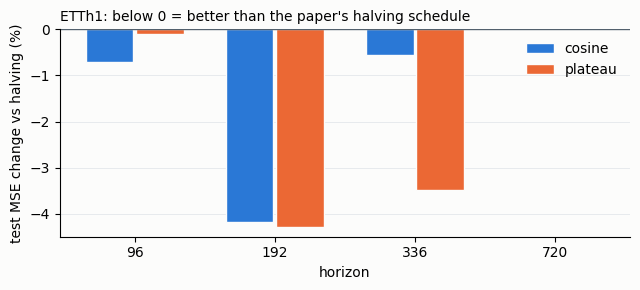

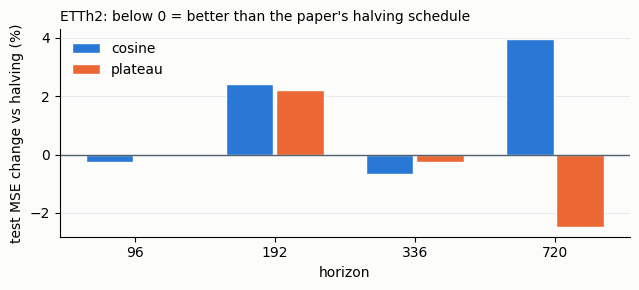

The plateau schedule improves on the paper's halving schedule by 1.0% test MSE on average. This supports the idea that halving every epoch stops learning too early. With one seed, confirm the gain with more seeds before relying on it, especially where it is marked 'within seed noise'.

ETTh1
- cosine vs halving: average test MSE change -1.4% (better at 1, worse at 0, no real change at 3 of 4 horizons); trains for 5.5 epochs on average vs 6.2 for halving.
- plateau vs halving: average test MSE change -2.0% (better at 2, worse at 0, no real change at 2 of 4 horizons); trains for 5.2 epochs on average vs 6.2 for halving.
- Chosen by validation loss (no test data used): halving at 4 horizon(s).

ETTh2
- cosine vs halving: average test MSE change +1.4% (better at 0, worse at 2, no real change at 2 of 4 horizons); trains for 6.2 epochs on average vs 6.5 for halving.
- plateau vs halving: average test MSE change -0.1% (better at 1, worse at 1, no real change at 2 of 4 horizons); trains for 6.

halving MSE  cosine MSE  cosine MSE Δ%  \
dataset horizon                                           
ETTh1   96            0.4048      0.4019        -0.7035   
        192           0.4763      0.4564        -4.1873   
        336           0.5436      0.5406        -0.5626   
        720           0.5308      0.5308         0.0000   
ETTh2   96            0.3370      0.3362        -0.2402   
        192           0.4046      0.4144         2.4152   
        336           0.4538      0.4507        -0.6757   
        720           0.4335      0.4507         3.9723   

                              cosine verdict  plateau MSE  plateau MSE Δ%  \
dataset horizon                                                             
ETTh1   96                  ~ no real change       0.4043         -0.1071   
        192                         ✓ better       0.4559         -4.2838   
        336                 ~ no real change       0.5247         -3.4889   
        720                 ~ no real change       0.5308          0.0000   
ETTh2   96                  ~ no real change       0.3370          0.0000   
        192      ✗ worse (within seed noise)       0.4136          2.2220   
        336                 ~ no real change       0.4527         -0.2424   
        720      ✗ worse (within seed noise)       0.4227         -2.4948   

                              plateau verdict  seed spread %  \
dataset horizon                                                
ETTh1   96                   ~ no real change         0.0670   
        192                          ✓ better         1.9037   
        336      ✓ better (within seed noise)         4.0901   
        720                  ~ no real change         4.2325   
ETTh2   96                   ~ no real change         3.0993   
        192       ✗ worse (within seed noise)         1.9670   
        336                  ~ no real change         0.6909   
        720      ✓ better (within seed noise)         4.6904   

                picked by validation  
dataset horizon                       
ETTh1   96                   halving  
        192                  halving  
        336                  halving  
        720                  halving  
ETTh2   96                    cosine  
        192                   cosine  
        336                   cosine  
        720                  halving


Saved to /content/drive/MyDrive/TimesNet_reproduction/table13_project/table13_lr_report: lr_comparison.csv, lr_runs.csv, plots/, lr_report.md


In [ ]:
# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------
# ---------------- 12.6 Learning-Rate Report (CSV + Markdown + plots) --------
# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------
#
# Builds everything from the runs stored on Drive (can be run at any time) and saves, in
# LR_REPORT_ROOT: lr_comparison.csv, lr_runs.csv, plots/*.png and lr_report.md.

LR_TABLE, LR_RUNS = lr_tables()
assert len(LR_TABLE), "No finished runs yet - run 12.5 first."
plot_paths = [lr_plot(ds, LR_TABLE) for ds in LR_TABLE.index.get_level_values("dataset").unique()]

# Conclusions per schedule and dataset
others = [s for s in LR_SCHEDULES if s != "halving"]
lines = []
for ds, g in LR_TABLE.groupby(level = "dataset"):
    lines.append(f"**{ds}**")
    for s in others:
        if f"{s} MSE Δ%" not in g:
            lines.append(f"- {s}: not run yet.")
            continue
        d = g[f"{s} MSE Δ%"].dropna()
        better = int((g[f"{s} verdict"].str.startswith("✓")).sum())
        worse = int((g[f"{s} verdict"].str.startswith("✗")).sum())
        lines.append(f"- **{s}** vs halving: average test MSE change {d.mean():+.1f}% "
                     f"(better at {better}, worse at {worse}, no real change at {len(d) - better - worse} of {len(d)} horizons); "
                     f"trains for {g[f'{s} epochs'].mean():.1f} epochs on average vs {g['halving epochs'].mean():.1f} for halving.")
    picks = g["picked by validation"].value_counts()
    lines.append(f"- Chosen by validation loss (no test data used): "
                 + ", ".join(f"{k} at {v} horizon(s)" for k, v in picks.items()) + ".")
    lines.append("")

avg = {s: LR_TABLE[f"{s} MSE Δ%"].mean() for s in others if f"{s} MSE Δ%" in LR_TABLE}
best = min(avg, key = avg.get) if avg else None
if best is not None and avg[best] <= -LR_THRESHOLD:
    overall = (f"The **{best}** schedule improves on the paper's halving schedule by {-avg[best]:.1f}% test MSE on average. "
               f"This supports the idea that halving every epoch stops learning too early. With one seed, confirm "
               f"the gain with more seeds before relying on it, especially where it is marked 'within seed noise'.")
elif best is not None and avg[best] < LR_THRESHOLD:
    overall = ("Neither alternative schedule clearly beats halving on average (changes within ±1%). The paper's "
               "schedule, despite reducing the learning rate fast, is not a major limitation for these datasets.")
else:
    overall = "Both alternative schedules are worse than halving on average; the paper's schedule is a good choice here."

guide = f"""## How to read this report

Only the learning-rate schedule differs between the runs: same data, model, 10 epochs maximum, early stopping
(patience 3), learning rate 1e-4 and seed {LR_SEED}. Test MSE/MAE are on the same scale as Table 13.

| Schedule | What it does |
|---|---|
| **halving** (paper) | Learning rate halved after every epoch: 1e-4, 5e-5, 2.5e-5, ... |
| **cosine** | Learning rate lowered smoothly along a cosine curve, reaching ~0 at epoch 10 |
| **plateau** | Learning rate kept at 1e-4, halved only after an epoch in which validation loss did not improve |

| Column | What we can conclude |
|---|---|
| **MSE Δ%** | Change in test MSE vs halving. Negative = better. Within ±{LR_THRESHOLD:g}% counts as no real change. |
| **verdict** | ✓ better / ✗ worse / ~ no real change. "(within seed noise)": the change is smaller than twice the normal seed-to-seed variation from Section 5 (**seed spread %**), so it may be luck. |
| **epochs** | Epochs actually trained (early stopping can end before 10). More epochs with a better score suggests halving stopped learning too early. |
| **picked by validation** | The schedule with the lowest validation loss: what you would choose honestly, without looking at test data. If it matches the best test schedule, the choice is reliable. |
"""

caveats = f"""## Caveats

- One seed ({LR_SEED}). Differences of a few percent can come from randomness; see "seed spread %".
- Only the schedule was changed. More epochs, warm-up or a different starting learning rate could change the picture.
- Tuning TimesNet's training makes the comparison with Table 13's baselines less like-for-like: they were not tuned.
"""

cols = ["halving MSE"] + [c for s in others for c in (f"{s} MSE", f"{s} MSE Δ%", f"{s} verdict")] + \
       ["seed spread %", "picked by validation"]
cols = [c for c in cols if c in LR_TABLE]
md = ["# TimesNet learning-rate schedules (ETTh1, ETTh2)\n",
      f"Horizons {', '.join(map(str, LR_HORIZONS))}; seed {LR_SEED}.\n",
      "## Overall conclusion\n", overall + "\n",
      guide,
      "## Conclusions per dataset\n", "\n".join(lines),
      "## Test MSE by schedule\n", LR_TABLE[cols].round(4).to_markdown() + "\n",
      "## Plots\n", "\n".join(f"![{os.path.basename(p)}](plots/{os.path.basename(p)})" for p in plot_paths) + "\n",
      "## All runs\n", LR_RUNS.drop(columns = ["key"]).round(5).to_markdown(index = False) + "\n",
      caveats]

LR_TABLE.round(5).to_csv(os.path.join(LR_REPORT_ROOT, "lr_comparison.csv"))
LR_RUNS.round(6).to_csv(os.path.join(LR_REPORT_ROOT, "lr_runs.csv"), index = False)
open(os.path.join(LR_REPORT_ROOT, "lr_report.md"), "w").write("\n".join(md))

print(overall.replace("**", "") + "\n")
print("\n".join(lines).replace("**", ""))
display(LR_TABLE[cols].round(4))
print(f"\nSaved to {LR_REPORT_ROOT}: lr_comparison.csv, lr_runs.csv, plots/, lr_report.md")

## 13. TimesNet (GELU) vs TimesNet-KANB: explainability, drift and novelty (any dataset, any horizon)

**Questions**
1. Which cycles (periods) does TimesNet really use, and do they match the data's own cycles?
2. Which variables and which parts of the past drive the forecasts (global and per window), are those explanations
   **trustworthy** (faithfulness) and **stable** (over seeds, folds, the test period, between the two models)?
3. Which variables does each model really **need** (ablation)?
4. How much **drift / novelty** is there between training and test data (covariate drift, concept drift), and
   **which model copes better with large vs small drift**?
5. Where do the models fail (worst windows)?

**Protocol (your choices)**

| Part | Choice | Why it is best practice |
|---|---|---|
| Models | TimesNet (GELU) and TimesNet-KANB, **exactly the Table 17 file** (KANB2 in the TimesBlocks; KANB1 is defined but inactive in forecasting, as the forecasting head has no activation) | same code, only the activation differs |
| Training | **5-fold sliding-window CV with a purge gap** (`seq_len + pred_len` rows) between training and validation and before the test inputs; every fold has the same training length | no window of one split overlaps another; no look-ahead; folds are comparable |
| Test | the **paper's own test period**, never used for training, early stopping or tuning | results stay comparable with Table 13 |
| Test windows | **non-overlapping targets** (stride = `pred_len`), **one window at a time** (batch 1) | independent errors for the statistical tests; TimesNet's FFT period choice depends on the batch, so batch 1 gives every window its own periods |
| Scaling | `StandardScaler` fitted on each fold's **training rows only**; all errors converted to one common ruler (z-units of the CV pool) | no leakage; folds, seeds and models can be averaged |
| Seeds | 2021, 2022, 2023 | |
| SHAP | permutation SHAP on **variable × time-segment** groups (exactly additive) with **real training windows** as replacements + GradientSHAP per hour | no fake "zero" inputs; periods fixed to each window's own |
| Drift | **MMD + energy distance** (block-conformal p-values, block-permutation tests, Benjamini-Hochberg) and a **domain classifier** (blocked CV, block-permutation null, SHAP) | non-parametric; blocks respect autocorrelation |
| Concept drift | **both**: joint (inputs + future) vs inputs only, and residual-based (validation vs test errors) | |
| Drift bins | terciles of the window's drift score | |
| KANB vs GELU | **Diebold-Mariano** test (HAC variance + Harvey small-sample correction) on the per-window loss difference, overall and per drift tercile, plus how many folds KANB wins | the standard test for comparing forecasts |

**How to use:** 13.1 settings → 13.2–13.4 write the scripts → 13.5 helpers → 13.6 train (one cell per dataset and
horizon, resumable: finished folds are skipped) → 13.7 analyse (one cell per dataset and horizon) → 13.8 show the
figures. All results are stored under `table13_s13/` (on Drive with `USE_DRIVE = True`).

**Cost (GPU):** per dataset and horizon, 2 models × 5 folds × 3 seeds = 30 trainings. ETTh1/ETTh2 at horizon 96:
roughly 1–2 min per training on a T4. Start with one horizon and one seed (`seeds=[2021]`), then add the others.

In [ ]:
# ------------------------------ 13.1 Settings ------------------------------

import subprocess, json, time, glob
import numpy as np
import pandas as pd

S13_MODELS = ["TimesNet", "TimesNet_KANB"]     # first = reference (GELU), second = ours
S13_SEEDS = [2021]                               # [2021, 2022, 2023]
S13_FOLDS = 5                                   # sliding-window folds
S13_VAL_FRAC = 0.4                              # share of the CV pool used by the 5 validation segments together
S13_GAP = -1                                    # purge gap in rows; -1 = seq_len + pred_len (one full window)

# Analysis settings (passed to xai13.py); larger = more precise, slower
S13_XAI = {"n_segments": 8,          # time segments per variable (SHAP features = variables x segments)
           "shap_samples": 16,       # permutation SHAP: random orders per window (antithetic pairs)
           "background": 32,         # real training windows used as replacements
           "grad_samples": 32,       # GradientSHAP samples per window
           "grad_seeds": "2021",     # seeds explained with GradientSHAP (the fine-grained heatmap)
           "faith_steps": 10,        # points on the deletion curves
           "ablation_repeats": 3,    # repeats of the variable ablation (different donor windows)
           "block_len": 0,           # rows per drift block (0 = one week)
           "perms": 199,             # permutations for the drift tests
           "clf_perms": 29,          # permutations for the domain classifier's AUC
           "gallery": 6}             # worst windows shown

S13_ROOT = R.results_root(name = "table13_s13", use_drive = USE_DRIVE)
print("Results folder:", S13_ROOT)

# packages for the analyses, installed into the TSLib environment (once)
R.sh(f"uv pip install --python {PY} -q plotly==5.24.1 kaleido==0.2.1 shap==0.48.0 statsmodels")

Results folder: /content/drive/MyDrive/TimesNet_reproduction/table13_project/table13_s13
$ uv pip install --python /content/tslib_env/bin/python -q plotly==5.24.1 kaleido==0.2.1 shap==0.48.0 statsmodels


''

In [ ]:
%%writefile models/TimesNet_KANB.py
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.fft
from layers.Embed import DataEmbedding
from layers.Conv_Blocks import Inception_Block_V1

# ---------------------------------------------------------------------------
# TimesNet with KANB activations ("Ours").
# Identical to TSLib's models/TimesNet.py (commit 4e938a1) except for the two
# activation functions, which are the model's only non-linear activations:
#   * KANB2 replaces nn.GELU() inside every TimesBlock (between the two Inception blocks)
#   * KANB1 replaces F.gelu in the classification head (before the final Linear layer)
#
# KANB: Kanakoudis, Mandalis & Pelekis, "KANB: A Family of Parametric Activation
# Functions With Trainable Parameters", IEEE Access 13 (2025), 146081-146087.
#   s = sigmoid(y)
#   KANB1(y) = 3(1-s)^2 s P1 + 3(1-s) s^2 P2 + s^3        (bounded in [0, 1])
#   KANB2(y) = 3(1-s)^2 s P1 + 3(1-s) s^2 P2 + y s^3      (-> 0 for y -> -inf, ~y for y -> +inf)
#   P1, P2: trainable, kept in [0, 1] (clip after every optimiser step, as in the paper),
#           initialised at KANB1: P1 = 0.2, P2 = 0.8 and KANB2: P1 = 0.8, P2 = 0.2 (every layer).
# ---------------------------------------------------------------------------


class KANB(nn.Module):
    """KANB activation with two trainable Bezier ordinates (one pair per layer)."""

    # initial (P1, P2) per variant; both parameters stay trainable
    INIT = {1: (0.2, 0.8),          # KANB1 (classification head)
            2: (0.8, 0.2)}          # KANB2 (inside every TimesBlock)

    def __init__(self, variant):
        super(KANB, self).__init__()
        assert variant in (1, 2), "variant must be 1 (KANB1) or 2 (KANB2)"
        self.variant = variant
        # Fixed starting values, no random draw: every other weight is initialised exactly as
        # in the original (GELU) TimesNet with the same seed -> a fair comparison.
        p1, p2 = KANB.INIT[variant]
        self.p1 = nn.Parameter(torch.tensor([p1]))
        self.p2 = nn.Parameter(torch.tensor([p2]))

    def forward(self, y):
        s = torch.sigmoid(y)
        t = 1.0 - s
        last = s ** 3 if self.variant == 1 else y * s ** 3
        return 3.0 * t * t * s * self.p1 + 3.0 * t * s * s * self.p2 + last

    @torch.no_grad()
    def clip_(self):
        """Clip01 constraint of the paper: keep P1, P2 in [0, 1]."""
        self.p1.clamp_(0.0, 1.0)
        self.p2.clamp_(0.0, 1.0)

    def extra_repr(self):
        return f"variant=KANB{self.variant}"


def clip_kanb_(model):
    """Call after every optimiser step."""
    for m in model.modules():
        if isinstance(m, KANB):
            m.clip_()


def kanb_parameters(model):
    """{module name: (variant, P1, P2)} for every KANB in the model."""
    return {name: (m.variant, float(m.p1), float(m.p2))
            for name, m in model.named_modules() if isinstance(m, KANB)}


def FFT_for_Period(x, k=2):
    # [B, T, C]
    xf = torch.fft.rfft(x, dim=1)
    # find period by amplitudes
    frequency_list = abs(xf).mean(0).mean(-1)
    frequency_list[0] = 0
    _, top_list = torch.topk(frequency_list, k)
    top_list = top_list.detach().cpu().numpy()
    period = x.shape[1] // top_list
    return period, abs(xf).mean(-1)[:, top_list]


class TimesBlock(nn.Module):
    def __init__(self, configs):
        super(TimesBlock, self).__init__()
        self.seq_len = configs.seq_len
        self.pred_len = configs.pred_len
        self.k = configs.top_k
        # parameter-efficient design
        self.conv = nn.Sequential(
            Inception_Block_V1(configs.d_model, configs.d_ff,
                               num_kernels=configs.num_kernels),
            KANB(2),  # [Ours] was nn.GELU()
            Inception_Block_V1(configs.d_ff, configs.d_model,
                               num_kernels=configs.num_kernels)
        )

    def forward(self, x):
        B, T, N = x.size()
        period_list, period_weight = FFT_for_Period(x, self.k)

        res = []
        for i in range(self.k):
            period = period_list[i]
            # padding
            if (self.seq_len + self.pred_len) % period != 0:
                length = (
                                 ((self.seq_len + self.pred_len) // period) + 1) * period
                padding = torch.zeros([x.shape[0], (length - (self.seq_len + self.pred_len)), x.shape[2]]).to(x.device)
                out = torch.cat([x, padding], dim=1)
            else:
                length = (self.seq_len + self.pred_len)
                out = x
            # reshape
            out = out.reshape(B, length // period, period,
                              N).permute(0, 3, 1, 2).contiguous()
            # 2D conv: from 1d Variation to 2d Variation
            out = self.conv(out)
            # reshape back
            out = out.permute(0, 2, 3, 1).reshape(B, -1, N)
            res.append(out[:, :(self.seq_len + self.pred_len), :])
        res = torch.stack(res, dim=-1)
        # adaptive aggregation
        period_weight = F.softmax(period_weight, dim=1)
        period_weight = period_weight.unsqueeze(
            1).unsqueeze(1).repeat(1, T, N, 1)
        res = torch.sum(res * period_weight, -1)
        # residual connection
        res = res + x
        return res


class Model(nn.Module):
    """
    TimesNet (paper link: https://openreview.net/pdf?id=ju_Uqw384Oq) with KANB2 in the
    TimesBlocks and KANB1 in the classification head.
    """

    def __init__(self, configs):
        super(Model, self).__init__()
        self.configs = configs
        self.task_name = configs.task_name
        self.seq_len = configs.seq_len
        self.label_len = configs.label_len
        self.pred_len = configs.pred_len
        self.model = nn.ModuleList([TimesBlock(configs)
                                    for _ in range(configs.e_layers)])
        self.enc_embedding = DataEmbedding(configs.enc_in, configs.d_model, configs.embed, configs.freq,
                                           configs.dropout)
        self.layer = configs.e_layers
        self.layer_norm = nn.LayerNorm(configs.d_model)
        if self.task_name == 'long_term_forecast' or self.task_name == 'short_term_forecast':
            self.predict_linear = nn.Linear(
                self.seq_len, self.pred_len + self.seq_len)
            self.projection = nn.Linear(
                configs.d_model, configs.c_out, bias=True)
        if self.task_name == 'imputation' or self.task_name == 'anomaly_detection':
            self.projection = nn.Linear(
                configs.d_model, configs.c_out, bias=True)
        if self.task_name == 'classification':
            self.act = KANB(1)  # [Ours] was F.gelu
            self.dropout = nn.Dropout(configs.dropout)
            self.projection = nn.Linear(
                configs.d_model * configs.seq_len, configs.num_class)

    def forecast(self, x_enc, x_mark_enc, x_dec, x_mark_dec):
        # Normalization from Non-stationary Transformer
        means = x_enc.mean(1, keepdim=True).detach()
        x_enc = x_enc.sub(means)
        stdev = torch.sqrt(
            torch.var(x_enc, dim=1, keepdim=True, unbiased=False) + 1e-5)
        x_enc = x_enc.div(stdev)

        # embedding
        enc_out = self.enc_embedding(x_enc, x_mark_enc)  # [B,T,C]
        enc_out = self.predict_linear(enc_out.permute(0, 2, 1)).permute(
            0, 2, 1)  # align temporal dimension
        # TimesNet
        for i in range(self.layer):
            enc_out = self.layer_norm(self.model[i](enc_out))
        # project back
        dec_out = self.projection(enc_out)

        # De-Normalization from Non-stationary Transformer
        dec_out = dec_out.mul(
                  (stdev[:, 0, :].unsqueeze(1).repeat(
                      1, self.pred_len + self.seq_len, 1)))
        dec_out = dec_out.add(
                  (means[:, 0, :].unsqueeze(1).repeat(
                      1, self.pred_len + self.seq_len, 1)))
        return dec_out

    def imputation(self, x_enc, x_mark_enc, x_dec, x_mark_dec, mask):
        # Normalization from Non-stationary Transformer
        means = torch.sum(x_enc, dim=1) / torch.sum(mask == 1, dim=1)
        means = means.unsqueeze(1).detach()
        x_enc = x_enc.sub(means)
        x_enc = x_enc.masked_fill(mask == 0, 0)
        stdev = torch.sqrt(torch.sum(x_enc * x_enc, dim=1) /
                           torch.sum(mask == 1, dim=1) + 1e-5)
        stdev = stdev.unsqueeze(1).detach()
        x_enc = x_enc.div(stdev)

        # embedding
        enc_out = self.enc_embedding(x_enc, x_mark_enc)  # [B,T,C]
        # TimesNet
        for i in range(self.layer):
            enc_out = self.layer_norm(self.model[i](enc_out))
        # project back
        dec_out = self.projection(enc_out)

        # De-Normalization from Non-stationary Transformer
        dec_out = dec_out.mul(
                  (stdev[:, 0, :].unsqueeze(1).repeat(
                      1, self.pred_len + self.seq_len, 1)))
        dec_out = dec_out.add(
                  (means[:, 0, :].unsqueeze(1).repeat(
                      1, self.pred_len + self.seq_len, 1)))
        return dec_out

    def anomaly_detection(self, x_enc):
        # Normalization from Non-stationary Transformer
        means = x_enc.mean(1, keepdim=True).detach()
        x_enc = x_enc.sub(means)
        stdev = torch.sqrt(
            torch.var(x_enc, dim=1, keepdim=True, unbiased=False) + 1e-5)
        x_enc = x_enc.div(stdev)

        # embedding
        enc_out = self.enc_embedding(x_enc, None)  # [B,T,C]
        # TimesNet
        for i in range(self.layer):
            enc_out = self.layer_norm(self.model[i](enc_out))
        # project back
        dec_out = self.projection(enc_out)

        # De-Normalization from Non-stationary Transformer
        dec_out = dec_out.mul(
                  (stdev[:, 0, :].unsqueeze(1).repeat(
                      1, self.pred_len + self.seq_len, 1)))
        dec_out = dec_out.add(
                  (means[:, 0, :].unsqueeze(1).repeat(
                      1, self.pred_len + self.seq_len, 1)))
        return dec_out

    def classification(self, x_enc, x_mark_enc):
        # embedding
        enc_out = self.enc_embedding(x_enc, None)  # [B,T,C]
        # TimesNet
        for i in range(self.layer):
            enc_out = self.layer_norm(self.model[i](enc_out))

        # Output
        # the output transformer encoder/decoder embeddings don't include non-linearity
        output = self.act(enc_out)
        output = self.dropout(output)
        # zero-out padding embeddings
        output = output * x_mark_enc.unsqueeze(-1)
        # (batch_size, seq_length * d_model)
        output = output.reshape(output.shape[0], -1)
        output = self.projection(output)  # (batch_size, num_classes)
        return output

    def forward(self, x_enc, x_mark_enc, x_dec, x_mark_dec, mask=None):
        if self.task_name == 'long_term_forecast' or self.task_name == 'short_term_forecast':
            dec_out = self.forecast(x_enc, x_mark_enc, x_dec, x_mark_dec)
            return dec_out[:, -self.pred_len:, :]  # [B, L, D]
        if self.task_name == 'imputation':
            dec_out = self.imputation(
                x_enc, x_mark_enc, x_dec, x_mark_dec, mask)
            return dec_out  # [B, L, D]
        if self.task_name == 'anomaly_detection':
            dec_out = self.anomaly_detection(x_enc)
            return dec_out  # [B, L, D]
        if self.task_name == 'classification':
            dec_out = self.classification(x_enc, x_mark_enc)
            return dec_out  # [B, N]
        return None

Writing models/TimesNet_KANB.py


In [ ]:
%%writefile cv_forecast.py
"""
Sliding-window cross-validation with a purge gap for TSLib long-term forecasting
(TimesNet and TimesNet_KANB), evaluated on the paper's untouched test period.

Protocol (Section 13 of TimesNet_Table13):
* The paper's test period (TSLib's fixed borders) is never used for training, validation or early stopping.
* The rows before it (minus a purge gap) form the CV pool. K folds slide over the pool: every fold has the
  SAME training length, then a gap, then its own validation segment (early stopping). Validation segments
  are consecutive and non-overlapping; fold k+1's training window moves forward by one validation length.
* gap (default seq_len + pred_len rows) separates training rows from validation rows and the last
  validation segment from the test inputs, so no window shares a single time step with another split.
* The scaler (StandardScaler, like TSLib) is fitted on the fold's training rows only.
* Training = TSLib's own Exp_Long_Term_Forecast.train (Adam, MSE, lradj, EarlyStopping), fed with the
  fold's windows. During training TSLib also asks for a "test" loader for its log line: we give it a small
  part of the VALIDATION set, so the real test period is never seen during training.
* KANB: P1, P2 are clipped to [0, 1] after every optimiser step (as in the Table 17 notebook).
* Test: non-overlapping targets (stride = pred_len), one window at a time (TimesNet picks its FFT periods
  from the whole batch, so batch 1 makes every forecast depend only on its own input).
* Metrics: in the fold's own z-units (TSLib style) and on a COMMON ruler (z-units of the whole CV pool),
  so folds, seeds and models are comparable. Per-window errors are saved for the drift analysis.

Usage (inside the TSLib repository):
  python cv_forecast.py --make_folds --folds_file folds/ETTh1_h96.json -- <TSLib args>
  python cv_forecast.py --folds_file folds/ETTh1_h96.json --fold 0 --seed 2021 \
         --out_dir runs13/ETTh1/TimesNet/h96 -- <TSLib args incl. --model TimesNet --pred_len 96>
"""
import argparse
import json
import os
import random
import shutil
import sys
import tempfile
import textwrap
import time

import numpy as np
import pandas as pd
import torch
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset, Subset


# ---------------------------------------------------------------------------------------------------------
# Arguments
# ---------------------------------------------------------------------------------------------------------
def get_tslib_parser():
    """TSLib's own argparse parser, built from run.py, so every flag and default is identical."""
    with open(os.path.join(os.path.dirname(os.path.abspath(__file__)), "run.py")) as f:
        src = f.read()
    start = src.rfind("\n", 0, src.index("parser = argparse.ArgumentParser")) + 1
    end = src.rfind("\n", 0, src.index("args = parser.parse_args()")) + 1
    namespace = {"argparse": argparse}
    exec(textwrap.dedent(src[start:end]), namespace)
    return namespace["parser"]


def parse_all_args(argv=None):
    argv = sys.argv[1:] if argv is None else argv
    if "--" not in argv:
        raise SystemExit("Put TSLib arguments after a `--` separator.")
    k = argv.index("--")
    p = argparse.ArgumentParser(description="Sliding-window CV with purge gap (forecasting)")
    p.add_argument("--make_folds", action="store_true", help="only create the folds file")
    p.add_argument("--folds_file", required=True)
    p.add_argument("--n_folds", type=int, default=5)
    p.add_argument("--val_frac", type=float, default=0.4,
                   help="share of the CV pool used for validation, summed over all folds")
    p.add_argument("--gap", type=int, default=-1, help="purge gap in rows (-1 = seq_len + pred_len)")
    p.add_argument("--fold", type=int, default=0)
    p.add_argument("--seed", type=int, default=2021)
    p.add_argument("--out_dir", default="./runs13")
    p.add_argument("--save_checkpoint", type=int, default=1)
    own = p.parse_args(argv[:k])
    tslib = get_tslib_parser().parse_args(argv[k + 1:])
    return own, tslib


# ---------------------------------------------------------------------------------------------------------
# Data, exactly as TSLib reads it (column order, time features), without TSLib's fixed borders
# ---------------------------------------------------------------------------------------------------------
def load_frame(args):
    """Values [n, C] in TSLib's column order, the dates, and the column names."""
    df = pd.read_csv(os.path.join(args.root_path, args.data_path))
    if args.data not in ("ETTh1", "ETTh2", "ETTm1", "ETTm2"):          # Dataset_Custom: target last
        cols = [c for c in df.columns if c not in ("date", args.target)]
        df = df[["date"] + cols + [args.target]]
    data_cols = list(df.columns[1:]) if args.features in ("M", "MS") else [args.target]
    return df[data_cols].values.astype(np.float64), pd.to_datetime(df["date"]), data_cols


def time_marks(dates, args):
    """TSLib's time features (embed='timeF' -> time_features; otherwise month/day/weekday/hour[/minute])."""
    from utils.timefeatures import time_features
    if args.embed == "timeF":
        return time_features(pd.to_datetime(dates.values), freq=args.freq).transpose(1, 0)
    marks = pd.DataFrame({"month": dates.dt.month, "day": dates.dt.day, "weekday": dates.dt.weekday,
                          "hour": dates.dt.hour})
    if args.data in ("ETTm1", "ETTm2"):
        marks["minute"] = dates.dt.minute // 15
    return marks.values


def paper_borders(args, n):
    """TSLib's fixed borders: end of train, end of validation, end of test (rows)."""
    if args.data in ("ETTh1", "ETTh2"):
        unit = 30 * 24
    elif args.data in ("ETTm1", "ETTm2"):
        unit = 30 * 24 * 4
    else:
        unit = None
    if unit:
        return {"train_end": 12 * unit, "val_end": 16 * unit, "test_end": 20 * unit}
    num_train, num_test = int(n * 0.7), int(n * 0.2)
    return {"train_end": num_train, "val_end": n - num_test, "test_end": n}


def make_folds(args, n_folds, val_frac, gap):
    values, dates, cols = load_frame(args)
    n = len(values)
    b = paper_borders(args, n)
    L, H = args.seq_len, args.pred_len
    W = L + H                                            # rows used by one window
    gap = W if gap < 0 else gap
    test_input_start = b["val_end"] - L                  # first test window, exactly as TSLib
    pool_end = test_input_start - gap                    # rows [0, pool_end) form the CV pool
    val_len = int(val_frac * pool_end) // n_folds
    train_len = pool_end - n_folds * val_len - gap
    if val_len < W + 10:
        raise SystemExit(f"validation segments too short ({val_len} rows) for windows of {W} rows: "
                         f"use fewer folds or a larger --val_frac")
    if train_len < 3 * W:
        raise SystemExit(f"training segments too short ({train_len} rows): use fewer folds or smaller --val_frac")
    folds = []
    for k in range(n_folds):
        v0 = pool_end - (n_folds - k) * val_len
        t1 = v0 - gap
        folds.append({"fold": k, "train": [t1 - train_len, t1], "val": [v0, v0 + val_len]})
    test = [test_input_start, b["test_end"]]
    starts = list(range(test[0], test[1] - W + 1, H))    # non-overlapping targets
    pool_scaler = StandardScaler().fit(values[:pool_end])
    spec = {"dataset": args.data, "data_path": args.data_path, "seq_len": L, "pred_len": H, "gap": gap,
            "n_folds": n_folds, "val_frac": val_frac, "rows": n, "pool_end": pool_end,
            "train_len": train_len, "val_len": val_len, "paper_borders": b, "test": test,
            "test_starts": starts, "columns": cols,
            "dates": {"start": str(dates.iloc[0]), "end": str(dates.iloc[-1])},
            "common_mean": pool_scaler.mean_.tolist(), "common_std": pool_scaler.scale_.tolist(),
            "folds": folds,
            "protocol": "sliding window, equal training length, purge gap before validation and before the "
                        "test inputs; test = paper's test period, non-overlapping targets"}
    # sanity: no split shares a row with another, and every training row precedes its validation rows
    for f in folds:
        assert f["train"][0] >= 0 and f["train"][1] + gap == f["val"][0] and f["val"][1] <= pool_end
    assert folds[-1]["val"][1] == pool_end and pool_end + gap == test[0]
    return spec


class Windows(Dataset):
    """TSLib-style windows (seq_x, seq_y, seq_x_mark, seq_y_mark) starting at the given rows."""

    def __init__(self, data, marks, starts, args):
        self.data, self.marks, self.starts = data, marks, np.asarray(starts, dtype=int)
        self.L, self.Lb, self.H = args.seq_len, args.label_len, args.pred_len

    def __len__(self):
        return len(self.starts)

    def __getitem__(self, i):
        s = self.starts[i]
        e = s + self.L
        r0, r1 = e - self.Lb, e + self.H
        return self.data[s:e], self.data[r0:r1], self.marks[s:e], self.marks[r0:r1]


def fold_data(spec, fold, args):
    """Scaled data (fold's own scaler), time marks, the scaler and the window starts per split."""
    values, dates, _ = load_frame(args)
    f = spec["folds"][fold]
    scaler = StandardScaler().fit(values[f["train"][0]:f["train"][1]])
    data = scaler.transform(values)
    marks = time_marks(dates, args)
    W = args.seq_len + args.pred_len
    starts = {"train": list(range(f["train"][0], f["train"][1] - W + 1)),
              "val": list(range(f["val"][0], f["val"][1] - W + 1)),
              "test": spec["test_starts"]}
    return data, marks, scaler, starts, values


# ---------------------------------------------------------------------------------------------------------
# Training with TSLib's own loop
# ---------------------------------------------------------------------------------------------------------
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
    if torch.cuda.is_available():
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        torch.backends.cuda.matmul.allow_tf32 = False
        torch.backends.cudnn.allow_tf32 = False
    torch.use_deterministic_algorithms(True, warn_only=True)


def model_module(model):
    return sys.modules[type(model).__module__]


def kanb_parameters(model):
    f = getattr(model_module(model), "kanb_parameters", None)
    return f(model) if f else None


def forward(model, args, x, y, xm, ym):
    """The forward pass of TSLib's Exp_Long_Term_Forecast (decoder input, f_dim, last pred_len steps)."""
    dec = torch.zeros_like(y[:, -args.pred_len:, :]).float()
    dec = torch.cat([y[:, :args.label_len, :], dec], dim=1).float()
    out = model(x, xm, dec, ym)
    f_dim = -1 if args.features == "MS" else 0
    return out[:, -args.pred_len:, f_dim:], y[:, -args.pred_len:, f_dim:]


@torch.no_grad()
def predict(model, args, data, marks, starts, device, batch_size=1):
    """Forecasts for the given windows (batch 1 by default). Returns (pred, true) [n, H, C] in fold z-units."""
    model.eval()
    ds = Windows(data, marks, starts, args)
    preds, trues = [], []
    for i in range(0, len(ds), batch_size):
        items = [ds[j] for j in range(i, min(i + batch_size, len(ds)))]
        x, y, xm, ym = [torch.tensor(np.stack(a), dtype=torch.float32, device=device) for a in zip(*items)]
        p, t = forward(model, args, x, y, xm, ym)
        preds.append(p.cpu().numpy())
        trues.append(t.cpu().numpy())
    return np.concatenate(preds), np.concatenate(trues)


def main():
    own, args = parse_all_args()
    if own.make_folds:
        spec = make_folds(args, own.n_folds, own.val_frac, own.gap)
        os.makedirs(os.path.dirname(os.path.abspath(own.folds_file)), exist_ok=True)
        with open(own.folds_file, "w") as fh:
            json.dump(spec, fh, indent=1)
        print("FOLDS", json.dumps({k: spec[k] for k in ("dataset", "pred_len", "gap", "pool_end", "train_len",
                                                         "val_len")}),
              "| test windows:", len(spec["test_starts"]))
        return

    spec = json.load(open(own.folds_file))
    assert spec["pred_len"] == args.pred_len and spec["seq_len"] == args.seq_len, "folds file of another horizon"
    args.use_gpu = bool(torch.cuda.is_available() and args.use_gpu)
    args.device = torch.device("cuda:0" if args.use_gpu else "cpu")
    set_seed(own.seed)

    data, marks, scaler, starts, values = fold_data(spec, own.fold, args)
    tmp = tempfile.mkdtemp(prefix="cv13_")
    args.checkpoints = tmp

    def provider(a, flag):
        key = {"train": "train", "val": "val", "test": "val", "TEST": "val"}[flag]
        ds = Windows(data, marks, starts[key], a)
        if flag in ("test", "TEST"):                     # TSLib's per-epoch "Test Loss": validation subset
            ds = Subset(ds, list(range(min(len(ds), a.batch_size))))
        return ds, DataLoader(ds, batch_size=a.batch_size, shuffle=(flag == "train" or flag == "val"),
                              num_workers=0, drop_last=False)

    import exp.exp_long_term_forecasting as ELT
    import utils.tools as T
    ELT.data_provider = provider
    history = {"vali": []}
    original_call = T.EarlyStopping.__call__

    def recording_call(self, val_loss, model, path):
        history["vali"].append(float(val_loss))
        return original_call(self, val_loss, model, path)

    ELT.EarlyStopping.__call__ = recording_call
    original_opt = ELT.Exp_Long_Term_Forecast._select_optimizer
    trajectory = []

    def select_optimizer(self):
        opt = original_opt(self)
        clip = getattr(model_module(self.model), "clip_kanb_", None)
        if clip is not None:
            opt.register_step_post_hook(lambda *_: clip(self.model))
        return opt

    ELT.Exp_Long_Term_Forecast._select_optimizer = select_optimizer

    t0 = time.time()
    exp = ELT.Exp_Long_Term_Forecast(args)
    exp.args.device = exp.device
    n_params = sum(p.numel() for p in exp.model.parameters())
    kanb_start = kanb_parameters(exp.model)
    setting = f"{args.model_id}_{args.model}_fold{own.fold}_seed{own.seed}"
    exp.train(setting)
    train_min = (time.time() - t0) / 60
    model = exp.model

    t1 = time.time()
    pred_z, true_z = predict(model, args, data, marks, starts["test"], exp.device)
    test_min = (time.time() - t1) / 60
    # validation windows with non-overlapping targets (for the residual-based concept-drift check)
    W = args.seq_len + args.pred_len
    f = spec["folds"][own.fold]
    val_starts = list(range(f["val"][0], f["val"][1] - W + 1, args.pred_len))
    vpred_z, vtrue_z = predict(model, args, data, marks, val_starts, exp.device)
    # original units -> common ruler (CV-pool z-units)
    C = pred_z.shape[-1]
    inv = lambda z: z * scaler.scale_[-C:] + scaler.mean_[-C:]
    cm, cs = np.array(spec["common_mean"])[-C:], np.array(spec["common_std"])[-C:]
    to_common = lambda z: (inv(z) - cm) / cs
    pred_c, true_c = to_common(pred_z), to_common(true_z)
    err_c = pred_c - true_c
    verr_c = to_common(vpred_z) - to_common(vtrue_z)
    per_window_mse = (err_c ** 2).mean(axis=(1, 2))
    per_window_var_mse = (err_c ** 2).mean(axis=1)                      # [n, C]
    res = {"dataset": args.data, "model": args.model, "horizon": args.pred_len, "fold": own.fold, "seed": own.seed,
           "fold_spec": spec["folds"][own.fold], "gap": spec["gap"], "n_test_windows": int(len(pred_z)),
           "mse_fold_z": float(((pred_z - true_z) ** 2).mean()), "mae_fold_z": float(np.abs(pred_z - true_z).mean()),
           "mse": float((err_c ** 2).mean()), "mae": float(np.abs(err_c).mean()),
           "per_variable_mse": dict(zip(spec["columns"][-C:], (err_c ** 2).mean(axis=(0, 1)).round(6).tolist())),
           "epochs": len(history["vali"]), "vali_losses": history["vali"],
           "best_vali": float(min(history["vali"])) if history["vali"] else None,
           "train_minutes": train_min, "test_minutes": test_min, "n_params": int(n_params),
           "kanb_start": kanb_start, "kanb_end": kanb_parameters(model),
           "scaler_mean": scaler.mean_.tolist(), "scaler_std": scaler.scale_.tolist(),
           "test_batch_size": 1, "tslib_args": {k: v for k, v in vars(args).items()
                                                if isinstance(v, (int, float, str, bool, type(None)))}}
    os.makedirs(own.out_dir, exist_ok=True)
    stem = os.path.join(own.out_dir, f"fold{own.fold}__seed{own.seed}")
    np.savez_compressed(stem + "_test.npz", starts=np.array(starts["test"]), pred=pred_c.astype(np.float32),
                        window_mse=per_window_mse.astype(np.float32),
                        window_var_mse=per_window_var_mse.astype(np.float32),
                        window_var_err=err_c.mean(axis=1).astype(np.float32),        # signed mean error [n, C]
                        val_starts=np.array(val_starts), val_window_mse=(verr_c ** 2).mean(axis=(1, 2)).astype(np.float32),
                        val_window_var_err=verr_c.mean(axis=1).astype(np.float32))
    if own.save_checkpoint:
        ck = os.path.join(tmp, setting, "checkpoint.pth")
        shutil.copy2(ck, stem + ".pth")
    with open(stem + ".json.part", "w") as fh:
        json.dump(res, fh, indent=1)
    os.replace(stem + ".json.part", stem + ".json")
    shutil.rmtree(tmp, ignore_errors=True)
    print("FOLD_RESULT", json.dumps({k: res[k] for k in ("model", "horizon", "fold", "seed", "mse", "mae",
                                                          "epochs", "train_minutes")}))


if __name__ == "__main__":
    main()

Writing cv_forecast.py


In [ ]:
%%writefile xai13.py
"""
Section 13 of TimesNet_Table13: explainability, drift and TimesNet (GELU) vs TimesNet-KANB, for the fold
models of cv_forecast.py (sliding-window CV with purge gap, test = the paper's test period, non-overlapping
targets, one window at a time). No training happens here: every analysis loads the saved models.

Analyses (--analyses, comma separated or "all"):
  periods   which periods TimesNet's FFT picks (per window, per layer), their weights, vs the data's cycles
  shap      permutation SHAP on groups (variable x time segment), real training windows as replacements,
            exact additivity; global importance, stability over the test period, beeswarm, local waterfall
  gradshap  GradientSHAP (expected gradients) per hour x variable: fine-grained lag heatmaps
  faith     faithfulness (deletion with real replacements, SHAP order vs random) + stability of the
            explanations across seeds, across folds and between the two models
  ablation  variable ablation: one variable replaced by the same variable of another real window
  drift     novelty, train/test shift and drift: MMD + energy distance (block-conformal p-values, block
            permutation tests, Benjamini-Hochberg), domain classifier (blocked CV, block-permutation null,
            SHAP), concept drift (joint vs marginal; residual-based), drift terciles, Diebold-Mariano
  gallery   worst windows: input, truth, both models' forecasts, drift and novelty

Every forecast is made in the fold's own z-units (as in training) and converted to a COMMON ruler (z-units of
the whole CV pool), so folds, seeds and models can be averaged and compared.
"""
import argparse
import glob
import importlib
import json
import math
import os
import sys
import time
from argparse import Namespace

import numpy as np
import pandas as pd
import torch

import cv_forecast as CVF

COLORS = {"TimesNet": "#2B6CB0", "TimesNet_KANB": "#C05621"}
LIGHT = {"TimesNet": "rgba(43,108,176,0.18)", "TimesNet_KANB": "rgba(192,86,33,0.18)"}
LABEL = {"TimesNet": "TimesNet (GELU)", "TimesNet_KANB": "TimesNet-KANB (ours)"}
PAL = ["#2B6CB0", "#DD6B20", "#2F855A", "#6B46C1", "#B7791F", "#C53030", "#319795", "#D53F8C", "#4A5568",
       "#975A16", "#2C5282", "#9C4221"]
label = lambda m: LABEL.get(m, m)
color = lambda m: COLORS.get(m, "#4A5568")


# =========================================================================================================
# Figures
# =========================================================================================================
def save(fig, out_dir, name, width=1200, height=650):
    os.makedirs(out_dir, exist_ok=True)
    fig.update_layout(template="plotly_white", font=dict(family="Arial", size=12),
                      title_font=dict(size=16), width=width, height=height)
    fig.write_html(os.path.join(out_dir, name + ".html"), include_plotlyjs="directory")
    fig.write_json(os.path.join(out_dir, name + ".json"))          # reopened interactively in the notebook
    try:
        fig.write_image(os.path.join(out_dir, name + ".png"), scale=2)
    except Exception as e:  # noqa: BLE001
        print(f"PNG export failed for {name}: {e}")
    FIGURES.append(name)


FIGURES = []


def title(main, sub):
    return f"<b>{main}</b><br><sup>{sub}</sup>"


# =========================================================================================================
# Loading runs and models
# =========================================================================================================
def find_runs(run_root, model, horizon, folds=None, seeds=None):
    out = []
    for js in sorted(glob.glob(os.path.join(run_root, model, f"h{horizon}", "fold*__seed*.json"))):
        stem = js[:-5]
        res = json.load(open(js))
        if folds is not None and res["fold"] not in folds:
            continue
        if seeds is not None and res["seed"] not in seeds:
            continue
        if os.path.exists(stem + ".pth") and os.path.exists(stem + "_test.npz"):
            out.append({"model": model, "fold": res["fold"], "seed": res["seed"], "res": res,
                        "pth": stem + ".pth", "npz": stem + "_test.npz"})
    return out


def model_args(res):
    a = Namespace(**res["tslib_args"])
    a.use_gpu = torch.cuda.is_available()
    return a


def build_model(run, device):
    args = model_args(run["res"])
    mod = importlib.import_module(f"models.{args.model}")
    model = mod.Model(args).float().to(device)
    model.load_state_dict(torch.load(run["pth"], map_location=device))
    model.eval()
    return model, args, mod


# ---- control over TimesNet's period selection (record a window's periods, reuse them) -------------------
PER = {"mode": "normal", "rec": [], "i": 0, "log": None}


def fft_for_period(x, k=2):
    xf = torch.fft.rfft(x, dim=1)
    amp = abs(xf).mean(-1)                                      # per window, as TSLib
    if PER["mode"] == "force":
        top = PER["rec"][PER["i"]]
        PER["i"] += 1
    else:                                                       # TSLib's own rule, unchanged
        fl = abs(xf).mean(0).mean(-1)
        fl[0] = 0
        _, top = torch.topk(fl, k)
        top = top.detach().cpu().numpy()
        if PER["mode"] == "record":
            PER["rec"].append(top)
    period = x.shape[1] // top
    if PER["log"] is not None:
        w = torch.softmax(amp[:, top], dim=1)[0].detach().cpu().numpy()
        PER["log"].append((period.tolist(), w.tolist()))
    return period, amp[:, top]


def forecast_full_gradient(self, x_enc, x_mark_enc, x_dec, x_mark_dec):
    """TSLib's forecast() without .detach() on the window mean (same values; full gradient for SHAP)."""
    means = x_enc.mean(1, keepdim=True)
    x_enc = x_enc.sub(means)
    stdev = torch.sqrt(torch.var(x_enc, dim=1, keepdim=True, unbiased=False) + 1e-5)
    x_enc = x_enc.div(stdev)
    enc_out = self.enc_embedding(x_enc, x_mark_enc)
    enc_out = self.predict_linear(enc_out.permute(0, 2, 1)).permute(0, 2, 1)
    for i in range(self.layer):
        enc_out = self.layer_norm(self.model[i](enc_out))
    dec_out = self.projection(enc_out)
    dec_out = dec_out.mul(stdev[:, 0, :].unsqueeze(1).repeat(1, self.pred_len + self.seq_len, 1))
    dec_out = dec_out.add(means[:, 0, :].unsqueeze(1).repeat(1, self.pred_len + self.seq_len, 1))
    return dec_out


def patch_module(mod):
    if getattr(mod, "_xai13", False):
        return
    mod.FFT_for_Period = fft_for_period
    mod._original_forecast = mod.Model.forecast
    mod._xai13 = True


class Runner:
    """One fold model: its data (fold z-units), and forward passes with or without forced periods."""

    def __init__(self, run, spec, device):
        self.run, self.spec, self.device = run, spec, device
        self.model, self.args, self.mod = build_model(run, device)
        patch_module(self.mod)
        self.data, self.marks, self.scaler, self.starts, self.values = CVF.fold_data(spec, run["fold"], self.args)
        C = self.data.shape[1]
        self.C, self.L, self.H, self.Lb = C, self.args.seq_len, self.args.pred_len, self.args.label_len
        cm, cs = np.array(spec["common_mean"]), np.array(spec["common_std"])
        self.a = self.scaler.scale_ / cs                        # fold z -> common z: z_c = a z_f + b
        self.b = (self.scaler.mean_ - cm) / cs
        self.test_starts = np.array(spec["test_starts"])
        self.train_starts = np.array(self.starts["train"])

    def window(self, s):
        x = self.data[s:s + self.L]
        y = self.data[s + self.L - self.Lb:s + self.L + self.H]
        return x, y, self.marks[s:s + self.L], self.marks[s + self.L - self.Lb:s + self.L + self.H]

    def forward(self, xs, s, mode="normal", rec=None, grad=False, chunk=256):
        """Forecasts [B, H, C] (fold z) for a batch of inputs xs [B, L, C], with window s's marks."""
        _, y, xm, ym = self.window(s)
        outs = []
        self.mod.Model.forecast = forecast_full_gradient if grad else self.mod._original_forecast
        for i in range(0, len(xs), chunk):
            xb = xs[i:i + chunk]
            B = len(xb)
            xt = xb if torch.is_tensor(xb) else torch.tensor(np.asarray(xb), dtype=torch.float32, device=self.device)
            yt = torch.tensor(y, dtype=torch.float32, device=self.device).unsqueeze(0).expand(B, -1, -1)
            xmt = torch.tensor(xm, dtype=torch.float32, device=self.device).unsqueeze(0).expand(B, -1, -1)
            ymt = torch.tensor(ym, dtype=torch.float32, device=self.device).unsqueeze(0).expand(B, -1, -1)
            PER.update(mode=mode, rec=rec if rec is not None else [], i=0)
            dec = torch.zeros_like(yt[:, -self.H:, :])
            dec = torch.cat([yt[:, :self.Lb, :], dec], dim=1)
            with torch.set_grad_enabled(grad):
                o = self.model(xt, xmt, dec, ymt)[:, -self.H:, :]
            outs.append(o)
            if mode == "record":
                self.last_rec = list(PER["rec"])
            PER.update(mode="normal", rec=[], i=0)
        self.mod.Model.forecast = self.mod._original_forecast
        return torch.cat(outs)

    def own_periods(self, s):
        """The periods TimesNet picks for window s on its own (batch 1, its own time marks), per TimesBlock."""
        with torch.no_grad():
            self.forward([self.window(s)[0]], s, mode="record")
        return self.last_rec

    def to_common(self, z):
        return z * self.a[-z.shape[-1]:] + self.b[-z.shape[-1]:]

    def truth_common(self, s):
        return self.to_common(self.data[s + self.L:s + self.L + self.H])


def outputs_of(pred_c, H):
    """Explained outputs from forecasts [B, H, C] (common z): every variable's mean over the horizon, and the
    target (last column) at steps 1, H/2 and H."""
    steps = sorted({0, H // 2 - 1, H - 1})
    return torch.cat([pred_c.mean(1), pred_c[:, steps, -1]], dim=1)


def output_names(cols, H):
    steps = sorted({1, H // 2, H})
    return [f"{c} (mean)" for c in cols] + [f"{cols[-1]} t+{h}" for h in steps]


# =========================================================================================================
# Statistics
# =========================================================================================================
def bh(p):
    p = np.asarray(p, float)
    q = np.full_like(p, np.nan)
    ok = np.isfinite(p)
    if ok.sum() == 0:
        return q
    pv = p[ok]
    order = np.argsort(pv)
    ranked = pv[order] * len(pv) / (np.arange(len(pv)) + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty_like(pv)
    out[order] = np.minimum(ranked, 1)
    q[ok] = out
    return q


def dm_test(d):
    """Diebold-Mariano test on a loss differential series d (time order), HAC (Newey-West, Bartlett, automatic
    lag) variance and the Harvey-Leybourne-Newbold small-sample correction (h = 1: the windows' targets do not
    overlap). Returns (mean d, statistic, two-sided p, n)."""
    from scipy.stats import t as student
    d = np.asarray(d, float)
    d = d[np.isfinite(d)]
    n = len(d)
    if n < 4:
        return float(d.mean()) if n else np.nan, np.nan, np.nan, n
    dbar = d.mean()
    lag = max(1, int(np.floor(4 * (n / 100) ** (2 / 9))))
    e = d - dbar
    var = np.mean(e ** 2)
    for k in range(1, min(lag, n - 1) + 1):
        var += 2 * (1 - k / (lag + 1)) * np.mean(e[k:] * e[:-k])
    if var <= 0:
        return float(dbar), np.nan, np.nan, n
    stat = dbar / np.sqrt(var / n) * np.sqrt((n - 1) / n)       # HLN with h = 1
    return float(dbar), float(stat), float(2 * student.sf(abs(stat), n - 1)), n


def median_gamma(ref, rng, max_n=600):
    from scipy.spatial.distance import pdist
    r = ref[rng.choice(len(ref), min(len(ref), max_n), replace=False)]
    d = pdist(r, "sqeuclidean")
    med = np.median(d[d > 0]) if (d > 0).any() else 1.0
    return 1.0 / med


def mmd2(A, B, gamma):
    """Unbiased MMD^2 with an RBF kernel."""
    from scipy.spatial.distance import cdist
    Kaa = np.exp(-gamma * cdist(A, A, "sqeuclidean"))
    Kbb = np.exp(-gamma * cdist(B, B, "sqeuclidean"))
    Kab = np.exp(-gamma * cdist(A, B, "sqeuclidean"))
    m, n = len(A), len(B)
    return float((Kaa.sum() - np.trace(Kaa)) / (m * (m - 1)) + (Kbb.sum() - np.trace(Kbb)) / (n * (n - 1))
                 - 2 * Kab.mean())


def energy(A, B):
    """Energy distance (Szekely-Rizzo)."""
    from scipy.spatial.distance import cdist
    return float(2 * cdist(A, B).mean() - cdist(A, A).mean() - cdist(B, B).mean())


def evenly(idx, k):
    idx = np.asarray(idx)
    if len(idx) <= k:
        return idx
    return idx[np.linspace(0, len(idx) - 1, k).round().astype(int)]


def lowess_line(x, y, frac=0.6):
    try:
        from statsmodels.nonparametric.smoothers_lowess import lowess
        r = lowess(y, x, frac=frac)
        return r[:, 0], r[:, 1]
    except Exception:  # noqa: BLE001
        o = np.argsort(x)
        k = max(3, len(x) // 5)
        return np.asarray(x)[o], pd.Series(np.asarray(y)[o]).rolling(k, center=True, min_periods=1).mean().values


# =========================================================================================================
# 0. Periods
# =========================================================================================================
def analysis_periods(R_by_model, spec, out_dir, ctx):
    from plotly.subplots import make_subplots
    import plotly.graph_objects as go
    rows = []
    for m, runners in R_by_model.items():
        for R in runners:
            for w, s in enumerate(R.test_starts):
                PER["log"] = []
                with torch.no_grad():
                    R.forward([R.window(s)[0]], s)
                for layer, (periods, weights) in enumerate(PER["log"]):
                    for rank, (p, wt) in enumerate(zip(periods, weights)):
                        rows.append({"model": m, "fold": R.run["fold"], "seed": R.run["seed"], "window": w,
                                     "start": int(s), "layer": layer + 1, "rank": rank + 1, "period": int(p),
                                     "weight": float(wt)})
                PER["log"] = None
    P = pd.DataFrame(rows)
    P.to_csv(os.path.join(out_dir, "periods.csv"), index=False)
    models = list(R_by_model)
    # data's own cycles: autocorrelation of every variable on the CV pool (common z), averaged
    vals = (ctx["values"][:spec["pool_end"]] - np.array(spec["common_mean"])) / np.array(spec["common_std"])
    max_lag = min(spec["seq_len"] + spec["pred_len"], len(vals) // 3)
    acf = np.mean([[1.0] + [np.corrcoef(v[:-k], v[k:])[0, 1] for k in range(1, max_lag + 1)] for v in vals.T], axis=0)
    peaks = [k for k in range(2, max_lag) if acf[k] > acf[k - 1] and acf[k] >= acf[k + 1] and acf[k] > 0.1]
    # (a) how often each period is chosen
    top_periods = P.groupby("period").size().sort_values(ascending=False).index[:12]
    fig = make_subplots(rows=1, cols=2, column_widths=[0.55, 0.45], horizontal_spacing=0.1,
                        subplot_titles=["share of test windows choosing each period (any rank, any layer)",
                                        "data's own cycles: mean autocorrelation of the variables (CV pool)"])
    for m in models:
        d = P[P.model == m].drop_duplicates(["fold", "seed", "window", "layer", "period"])   # (L+H)//k can repeat
        n_w = d.groupby(["fold", "seed", "window", "layer"]).ngroups
        share = d.groupby("period").size().reindex(top_periods).fillna(0) / max(n_w, 1)
        fig.add_trace(go.Bar(x=[str(p) for p in top_periods], y=share.values, name=label(m), marker_color=color(m)),
                      1, 1)
    fig.add_trace(go.Scatter(x=list(range(len(acf))), y=acf, mode="lines", name="autocorrelation",
                             line=dict(color="#4A5568")), 1, 2)
    for k in peaks[:8]:
        fig.add_vline(x=k, line=dict(color="#A0AEC0", dash="dot"), row=1, col=2)
        fig.add_annotation(x=k, y=acf[k], text=str(k), showarrow=False, yshift=10, row=1, col=2)
    fig.update_xaxes(title_text="period (time steps)", type="category", row=1, col=1)
    fig.update_xaxes(title_text="lag (time steps)", row=1, col=2)
    fig.update_yaxes(title_text="share of windows", row=1, col=1)
    fig.update_layout(barmode="group", legend=dict(orientation="h", y=-0.2), margin=dict(t=120),
                      title=title(f"{ctx['dataset']} · h={spec['pred_len']} · Which cycles does TimesNet use?",
                                  "left: the periods TimesNet's FFT picks for each test window (top-k, both TimesBlocks; "
                                  "fold models and seeds pooled). Right: the data's own cycles (autocorrelation peaks, "
                                  "dotted).<br>Good sign: the chosen periods match the data's peaks (e.g. 24 = daily, 12 = "
                                  "half-daily for hourly data)"))
    save(fig, out_dir, "01_periods_chosen", 1400, 560)
    # (b) weights and stability over time
    fig = make_subplots(rows=1, cols=len(models), shared_yaxes=True, subplot_titles=[label(m) for m in models])
    for j, m in enumerate(models, 1):
        d = P[(P.model == m) & (P.layer == 1)]
        piv = d.groupby(["window", "period"]).size().unstack(fill_value=0)
        piv = piv.div(piv.sum(1), axis=0).reindex(columns=list(top_periods), fill_value=0.0)
        fig.add_trace(go.Heatmap(z=piv.values.T, x=[str(pd.Timestamp(ctx["dates"].iloc[int(s)]).date())
                                                     for s in spec["test_starts"][:len(piv)]],
                                 y=[str(p) for p in piv.columns], colorscale="Blues", zmin=0, zmax=1,
                                 showscale=(j == 1), colorbar=dict(title="share")), 1, j)
    fig.update_yaxes(type="category")
    fig.update_yaxes(title_text="period", row=1, col=1)
    fig.update_layout(margin=dict(t=110), title=title(
        f"{ctx['dataset']} · h={spec['pred_len']} · Period choice over the test period (first TimesBlock)",
        "share of fold models / seeds that pick each period for the window starting at that date. Changes over time "
        "show TimesNet adapting its cycles to the data (or reacting to drift)"))
    save(fig, out_dir, "02_periods_over_time", 1400, 520)
    summary = {}
    for m in models:
        d = P[(P.model == m) & (P["rank"] == 1)]
        if len(d):
            top = d.period.value_counts(normalize=True)
            summary[m] = {"most_chosen_period": int(top.index[0]), "share": float(top.iloc[0])}
    summary["acf_peaks"] = peaks[:8]
    return summary


# =========================================================================================================
# 1. SHAP (permutation on groups) and GradientSHAP
# =========================================================================================================
def feature_groups(L, C, cols, n_seg):
    edges = np.linspace(0, L, n_seg + 1).round().astype(int)
    feats, masks = [], []
    for c in range(C):
        for j in range(n_seg):
            m = np.zeros((L, C), bool)
            m[edges[j]:edges[j + 1], c] = True
            masks.append(m)
            lag0, lag1 = L - edges[j + 1] + 1, L - edges[j]
            feats.append({"variable": cols[c], "segment": j, "lags": f"{lag0}-{lag1}", "name": f"{cols[c]} · lag {lag0}-{lag1}"})
    return feats, masks, edges


def perm_shap_window(R, s, masks, bgs, samples, rng, H):
    """Permutation SHAP (antithetic orders, same background per pair) for one window, all outputs at once.
    Periods are fixed to the window's own (TimesNet's period choice is explained in the periods analysis)."""
    x = R.window(s)[0]
    rec = R.own_periods(s)
    F = len(masks)
    inputs, orders = [], []
    for _ in range(max(1, samples // 2)):
        b = bgs[rng.integers(len(bgs))]
        o = rng.permutation(F)
        for order in (o, o[::-1]):
            cur = b.copy()
            seq = [cur.copy()]
            for j in order:
                cur = np.where(masks[j], x, cur)
                seq.append(cur.copy())
            inputs.extend(seq)
            orders.append(order)
    with torch.no_grad():
        pred = R.forward(np.stack(inputs), s, mode="force", rec=rec)
    pc = pred.cpu().numpy() * R.a[-R.C:] + R.b[-R.C:]
    out = outputs_of(torch.tensor(pc), H).numpy().reshape(len(orders), F + 1, -1)
    phi = np.zeros((F, out.shape[-1]))
    for k, order in enumerate(orders):
        diff = out[k, 1:] - out[k, :-1]
        phi[order] += diff
    phi /= len(orders)
    full, base = out[0, -1], out[:, 0].mean(0)
    return phi, full, base


def grad_shap_window(R, s, bgs, samples, rng, H):
    """Expected gradients per time step x variable for every output, with the window's own periods and the
    full gradient through the window mean."""
    x = R.window(s)[0]
    rec = R.own_periods(s)
    pick = bgs[rng.integers(0, len(bgs), size=samples)]
    alpha = rng.uniform(size=(samples, 1, 1))
    diff = x[None] - pick
    xb = torch.tensor(pick + alpha * diff, dtype=torch.float32, device=R.device, requires_grad=True)
    pred = R.forward(xb, s, mode="force", rec=rec, grad=True, chunk=10 ** 6)
    a = torch.tensor(R.a[-R.C:], dtype=torch.float32, device=R.device)
    b = torch.tensor(R.b[-R.C:], dtype=torch.float32, device=R.device)
    outs = outputs_of(pred * a + b, H)
    phis = []
    for t in range(outs.shape[1]):
        g, = torch.autograd.grad(outs[:, t].sum(), xb, retain_graph=t < outs.shape[1] - 1)
        phis.append((torch.tensor(diff, dtype=torch.float32, device=R.device) * g).mean(0).detach().cpu().numpy())
    return np.stack(phis, -1)                                    # [L, C, n_out]


def analysis_shap(R_by_model, spec, out_dir, ctx, opt):
    """Permutation SHAP for every fold model and seed; global + over-time + local figures."""
    from plotly.subplots import make_subplots
    import plotly.graph_objects as go
    cols, H, L = spec["columns"], spec["pred_len"], spec["seq_len"]
    C = len(cols)
    feats, masks, edges = feature_groups(L, C, cols, opt.n_segments)
    onames = output_names(cols, H)
    rng0 = np.random.default_rng(opt.seed)
    store, checks = {}, []
    for m, runners in R_by_model.items():
        for R in runners:
            rng = np.random.default_rng(rng0.integers(1 << 31))
            bg_idx = rng.choice(len(R.train_starts), min(opt.background, len(R.train_starts)), replace=False)
            bgs = np.stack([R.window(int(R.train_starts[i]))[0] for i in bg_idx])
            phis, fulls, bases = [], [], []
            for s in R.test_starts:
                phi, full, base = perm_shap_window(R, int(s), masks, bgs, opt.shap_samples, rng, H)
                phis.append(phi); fulls.append(full); bases.append(base)
                checks.append(float(np.abs(phi.sum(0) - (full - base)).max()))
            store[(m, R.run["fold"], R.run["seed"])] = {"phi": np.stack(phis), "full": np.stack(fulls),
                                                        "base": np.stack(bases)}
            print(f"  SHAP {label(m)} fold {R.run['fold']} seed {R.run['seed']}: {len(phis)} windows", flush=True)
    np.savez_compressed(os.path.join(out_dir, "shap_values.npz"),
                        **{f"{m}__fold{f}__seed{s}__{k}": v[k] for (m, f, s), v in store.items() for k in v},
                        feature_names=np.array([f["name"] for f in feats]), output_names=np.array(onames))
    models = list(R_by_model)
    F = len(feats)
    # importance = mean |SHAP| over windows and outputs (common z-units)
    imp = {k: np.abs(v["phi"]).mean(axis=(0, 2)) for k, v in store.items()}          # [F]
    rows = []
    for (m, f, s), v in imp.items():
        share = v / v.sum()
        for j, ft in enumerate(feats):
            rows.append({"model": m, "fold": f, "seed": s, **ft, "importance": v[j], "share": share[j]})
    I = pd.DataFrame(rows)
    I.to_csv(os.path.join(out_dir, "shap_importance.csv"), index=False)
    # (a) global importance per variable and per segment (mean +- sd over folds x seeds)
    fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.12,
                        subplot_titles=["share of importance per variable", "share of importance per time segment (lags)"])
    seg_names = [f"lag {L - edges[j + 1] + 1}-{L - edges[j]}" for j in range(opt.n_segments)]
    for m in models:
        d = I[I.model == m]
        pv = d.groupby(["fold", "seed", "variable"]).share.sum().unstack()[cols]
        ps = d.groupby(["fold", "seed", "segment"]).share.sum().unstack()
        fig.add_trace(go.Bar(x=cols, y=pv.mean().values, error_y=dict(type="data", array=pv.std().fillna(0).values),
                             name=label(m), marker_color=color(m), legendgroup=m), 1, 1)
        fig.add_trace(go.Bar(x=seg_names, y=ps.mean().values, error_y=dict(type="data", array=ps.std().fillna(0).values),
                             name=label(m), marker_color=color(m), legendgroup=m, showlegend=False), 1, 2)
    fig.update_yaxes(tickformat=".0%")
    fig.update_xaxes(title_text="time segment of the input (lag 1 = most recent step)", row=1, col=2)
    fig.update_layout(barmode="group", legend=dict(orientation="h", y=-0.22), margin=dict(t=120),
                      title=title(f"{ctx['dataset']} · h={H} · Global feature importance (permutation SHAP)",
                                  "share of the total |SHAP| (all explained outputs, test windows), mean ± sd over the "
                                  f"{len(I.groupby(['fold', 'seed']))} fold models and seeds of each model. Features = "
                                  f"variable × time segment ({opt.n_segments} segments of the {L}-step input); "
                                  "replacements = real training windows"))
    save(fig, out_dir, "03_shap_global_importance", 1400, 560)
    # (b) variable x segment heatmaps + difference
    fig = make_subplots(rows=1, cols=len(models) + (1 if len(models) == 2 else 0), horizontal_spacing=0.07,
                        subplot_titles=[label(m) for m in models] + (["KANB − GELU"] if len(models) == 2 else []))
    mats = {}
    for j, m in enumerate(models, 1):
        mat = I[I.model == m].groupby(["variable", "segment"]).share.mean().unstack().reindex(cols)
        mats[m] = mat
        fig.add_trace(go.Heatmap(z=100 * mat.values, x=seg_names, y=cols, colorscale="Viridis", showscale=(j == 1),
                                 colorbar=dict(title="% of<br>importance", x=-0.08),
                                 hovertemplate="%{y} · %{x}<br>%{z:.2f}%<extra></extra>"), 1, j)
    if len(models) == 2:
        dmat = 100 * (mats[models[1]] - mats[models[0]])
        zmax = max(1e-9, float(np.nanmax(np.abs(dmat.values))))
        fig.add_trace(go.Heatmap(z=dmat.values, x=seg_names, y=cols, colorscale="RdBu_r", zmin=-zmax, zmax=zmax,
                                 colorbar=dict(title="points"), hovertemplate="%{y} · %{x}<br>%{z:+.2f}<extra></extra>"),
                      1, 3)
    fig.update_xaxes(tickangle=45)
    fig.update_layout(margin=dict(t=120), title=title(
        f"{ctx['dataset']} · h={H} · Where the evidence sits: variable × time segment",
        "share of importance per input block (mean over fold models and seeds). Right: KANB minus GELU; red = KANB "
        "relies more on that block"))
    save(fig, out_dir, "04_shap_variable_segment", 1500, 520)
    # (c) importance over the test period (stability over the series) + rank stability
    stab_rows, fig = [], make_subplots(rows=len(models), cols=1, shared_xaxes=True, vertical_spacing=0.12,
                                       subplot_titles=[label(m) for m in models])
    dates = [pd.Timestamp(ctx["dates"].iloc[int(s) + L]) for s in spec["test_starts"]]
    for r, m in enumerate(models, 1):
        per_w = np.mean([np.abs(v["phi"]).mean(axis=2) for (mm, f, s), v in store.items() if mm == m], axis=0)  # [W, F]
        var_w = np.stack([per_w[:, [j for j, ft in enumerate(feats) if ft["variable"] == c]].sum(1) for c in cols], 1)
        var_share = var_w / var_w.sum(1, keepdims=True)
        for c_i, c in enumerate(cols):
            fig.add_trace(go.Scatter(x=dates, y=var_share[:, c_i], mode="lines", stackgroup=f"g{r}", name=c,
                                     legendgroup=c, showlegend=(r == 1), line=dict(width=0.5, color=PAL[c_i % len(PAL)])),
                          r, 1)
        from scipy.stats import spearmanr
        rho = [spearmanr(per_w[i], per_w[j]).statistic for i in range(len(per_w)) for j in range(i + 1, len(per_w))]
        cv = var_share.std(0) / np.maximum(var_share.mean(0), 1e-12)
        stab_rows.append({"model": m, "median Spearman between windows": float(np.nanmedian(rho)) if rho else np.nan,
                          **{f"CV share {c}": float(v) for c, v in zip(cols, cv)}})
    fig.update_yaxes(tickformat=".0%", title_text="share of importance")
    fig.update_layout(margin=dict(t=120), legend=dict(orientation="h", y=-0.12), title=title(
        f"{ctx['dataset']} · h={H} · Are the important variables the same over the whole test period?",
        "share of importance of each variable per test window (date = forecast start), mean over fold models and seeds. "
        "Flat bands = stable explanations; bands that change = the model relies on different variables as the data "
        "drift"))
    save(fig, out_dir, "05_shap_importance_over_time", 1400, 300 + 280 * len(models))
    stab = pd.DataFrame(stab_rows).set_index("model")
    stab.round(4).to_csv(os.path.join(out_dir, "shap_stability_over_time.csv"))
    # (d) beeswarm for the target's mean forecast
    t_out = C - 1
    top = I.groupby("name").importance.mean().sort_values(ascending=False).index[:12]
    fig = make_subplots(rows=1, cols=len(models), shared_yaxes=True, horizontal_spacing=0.06,
                        subplot_titles=[label(m) for m in models])
    for j, m in enumerate(models, 1):
        for rank, name in enumerate(top[::-1]):
            fj = [f["name"] for f in feats].index(name)
            xs, vs = [], []
            for (mm, f, s), v in store.items():
                if mm != m:
                    continue
                R = [r for r in R_by_model[m] if r.run["fold"] == f and r.run["seed"] == s][0]
                for w, st in enumerate(R.test_starts):
                    x = R.to_common(R.window(int(st))[0])
                    xs.append(v["phi"][w, fj, t_out])
                    vs.append(float(x[masks[fj]].mean()))
            vs = np.array(vs)
            z = (vs - vs.mean()) / (vs.std() + 1e-12)
            jitter = np.random.default_rng(rank).uniform(-0.3, 0.3, len(xs))
            fig.add_trace(go.Scatter(x=xs, y=rank + jitter, mode="markers", showlegend=False,
                                     marker=dict(size=5, color=z, colorscale="RdBu_r", cmin=-2, cmax=2, opacity=0.75,
                                                 colorbar=dict(title="feature<br>value") if (j == 1 and rank == 0) else None,
                                                 showscale=(j == 1 and rank == 0))), 1, j)
        fig.add_vline(x=0, line=dict(color="#A0AEC0"), row=1, col=j)
        fig.update_xaxes(title_text=f"SHAP on mean forecast of {cols[-1]} (common z)", row=1, col=j)
    fig.update_yaxes(tickvals=list(range(len(top))), ticktext=list(top[::-1]), col=1)
    fig.update_layout(margin=dict(t=120, l=200), title=title(
        f"{ctx['dataset']} · h={H} · Beeswarm: how each input block moves the {cols[-1]} forecast",
        "one dot = one test window of one fold model / seed; colour = the block's mean value (red high, blue low). "
        "Red dots on the right = higher values raise the forecast"))
    save(fig, out_dir, "06_shap_beeswarm_target", 1500, 650)
    # (e) local waterfall + decision for chosen windows (worst / best of the ensemble)
    ctx["shap_store"], ctx["feats"], ctx["onames"] = store, feats, onames
    for m in models:
        ens = ctx["window_mse"][m]
        picks = [("worst window", int(np.argmax(ens))), ("best window", int(np.argmin(ens)))]
        if "drift_window" in ctx:
            picks.append(("largest drift", int(np.argmax(ctx["drift_window"]))))
        for why, w in picks:
            local_figure(m, w, why, store, feats, onames, spec, ctx, out_dir)
    msg = {}
    for m in models:
        d = I[I.model == m].groupby(["fold", "seed", "variable"]).share.sum().groupby("variable").mean()
        d = d.sort_values(ascending=False)
        msg[m] = f"most important variable {d.index[0]} ({100 * d.iloc[0]:.0f}% of importance)"
    return {"messages": msg, "efficiency_max_error": float(np.max(checks)) if checks else None,
            "stability_over_time": stab.round(4).to_dict(orient="index")}


def local_figure(m, w, why, store, feats, onames, spec, ctx, out_dir, top=10):
    from plotly.subplots import make_subplots
    import plotly.graph_objects as go
    keys = [k for k in store if k[0] == m]
    phi = np.mean([store[k]["phi"][w] for k in keys], axis=0)           # [F, n_out]
    full = np.mean([store[k]["full"][w] for k in keys], axis=0)
    base = np.mean([store[k]["base"][w] for k in keys], axis=0)
    t = len(spec["columns"]) - 1                                         # target's mean forecast
    names = [f["name"] for f in feats]
    order = np.argsort(-np.abs(phi[:, t]))
    head, rest = order[:top], order[top:]
    xs = ["average forecast<br>(training windows)"] + [names[i] for i in head] + [f"{len(rest)} other blocks", "forecast"]
    ys = [base[t]] + [phi[i, t] for i in head] + [phi[rest, t].sum(), 0.0]
    meas = ["absolute"] + ["relative"] * (len(ys) - 2) + ["total"]
    texts = [f"{v:+.3f}" if mm == "relative" else f"{v:.3f}" for v, mm in zip(ys, meas)]
    texts[-1] = f"{full[t]:.3f}"
    fig = make_subplots(rows=1, cols=2, column_widths=[0.5, 0.5], horizontal_spacing=0.16,
                        subplot_titles=[f"waterfall: mean forecast of {spec['columns'][-1]} (common z)",
                        "decision plot: every explained output built up block by block"])
    fig.add_trace(go.Waterfall(orientation="h", y=xs, x=ys, measure=meas, text=texts, textposition="outside",
                               increasing=dict(marker=dict(color="#C53030")), decreasing=dict(marker=dict(color="#2B6CB0")),
                               totals=dict(marker=dict(color="#2D3748")), showlegend=False, cliponaxis=False), 1, 1)
    run_ = np.cumsum([base[t]] + [phi[i, t] for i in head] + [phi[rest, t].sum()])
    lo_, hi_ = min(0.0, run_.min()), max(0.0, run_.max())
    pad = 0.18 * (hi_ - lo_ + 1e-9)
    fig.update_xaxes(range=[lo_ - pad, hi_ + pad], row=1, col=1)
    fig.update_yaxes(autorange="reversed", row=1, col=1)
    imp_order = np.argsort(-np.abs(phi).sum(1))
    show = list(imp_order[:top][::-1])
    others = [i for i in imp_order if i not in show]
    labels_ = ["average"] + ([f"{len(others)} other blocks"] if others else []) + [names[i] for i in show]
    for k, on in enumerate(onames):
        steps = [base[k]] + ([base[k] + phi[others, k].sum()] if others else [])
        cur = steps[-1]
        for i in show:
            cur += phi[i, k]
            steps.append(cur)
        fig.add_trace(go.Scatter(x=steps, y=labels_, mode="lines+markers", name=on,
                                 line=dict(color=PAL[k % len(PAL)], width=3 if k == t else 1.3)), 1, 2)
    start = pd.Timestamp(ctx["dates"].iloc[int(spec["test_starts"][w]) + spec["seq_len"]])
    fig.update_layout(margin=dict(t=130, l=170), legend=dict(orientation="h", y=-0.15), title=title(
        f"{ctx['dataset']} · h={spec['pred_len']} · {label(m)} · test window {w} (forecast from {start:%Y-%m-%d %H:%M}): {why}",
        f"ensemble MSE {ctx['window_mse'][m][w]:.3f} (common z). Left: from the average forecast on real training windows, "
        "each input block adds (red) or removes (blue); the bars add up exactly to the forecast. Right: the same for every "
        "explained output"))
    save(fig, out_dir, f"07_shap_local_{m}_w{w}", 1600, 640)


def analysis_gradshap(R_by_model, spec, out_dir, ctx, opt):
    from plotly.subplots import make_subplots
    import plotly.graph_objects as go
    cols, L, H = spec["columns"], spec["seq_len"], spec["pred_len"]
    rng = np.random.default_rng(opt.seed + 1)
    maps, checks = {}, []
    for m, runners in R_by_model.items():
        acc = []
        for R in runners:
            if R.run["seed"] not in opt.grad_seeds:
                continue
            bg_idx = rng.choice(len(R.train_starts), min(opt.background, len(R.train_starts)), replace=False)
            bgs = np.stack([R.window(int(R.train_starts[i]))[0] for i in bg_idx])
            for s in R.test_starts:
                acc.append(np.abs(grad_shap_window(R, int(s), bgs, opt.grad_samples, rng, H)))
        if acc:
            maps[m] = np.mean(acc, axis=0)                                # [L, C, n_out]
    if not maps:
        return {}
    np.savez_compressed(os.path.join(out_dir, "gradshap_maps.npz"), **{m: v for m, v in maps.items()})
    steps_per_day = ctx["steps_per_day"]
    models = list(maps)
    fig = make_subplots(rows=2, cols=len(models), row_heights=[0.62, 0.38], vertical_spacing=0.14,
                        horizontal_spacing=0.08, subplot_titles=[label(m) for m in models] + [""] * len(models))
    for j, m in enumerate(models, 1):
        mp = maps[m].mean(-1)[::-1]                                       # row 0 = lag 1
        share = mp / mp.sum()
        fig.add_trace(go.Heatmap(z=100 * share.T, x=list(range(1, L + 1)), y=cols, colorscale="Viridis",
                                 showscale=(j == 1), colorbar=dict(title="%", len=0.55, y=0.75),
                                 hovertemplate="lag %{x} · %{y}<br>%{z:.3f}%<extra></extra>"), 1, j)
        prof = share.sum(1)
        fig.add_trace(go.Bar(x=list(range(1, L + 1)), y=100 * prof, marker_color=color(m), showlegend=False), 2, j)
        if steps_per_day and steps_per_day < L:
            for k in range(steps_per_day, L + 1, steps_per_day):
                fig.add_vline(x=k, line=dict(color="#A0AEC0", dash="dot"), row=2, col=j)
        fig.update_xaxes(title_text="lag (1 = most recent step)", row=2, col=j)
    fig.update_yaxes(title_text="% of importance", row=2, col=1)
    fig.update_layout(margin=dict(t=120), title=title(
        f"{ctx['dataset']} · h={H} · Fine-grained importance per past step and variable (GradientSHAP)",
        "expected gradients with real training windows as references (seed(s) " + ", ".join(map(str, opt.grad_seeds))
        + ", all folds, test windows). Bottom: importance per lag; dotted = whole days back (the daily cycle)"))
    save(fig, out_dir, "08_gradshap_lag_variable", 1500, 760)
    out = {}
    for m in models:
        prof = maps[m].mean(-1)[::-1].sum(1)
        recent = prof[:min(steps_per_day or L // 4, L)].sum() / prof.sum()
        out[m] = {"share of importance in the most recent day": float(recent)}
    return out


# =========================================================================================================
# 2. Faithfulness and stability of the explanations
# =========================================================================================================
def analysis_faith(R_by_model, spec, out_dir, ctx, opt):
    from plotly.subplots import make_subplots
    import plotly.graph_objects as go
    from scipy.stats import spearmanr
    from itertools import combinations
    store, feats = ctx["shap_store"], ctx["feats"]
    cols, L, H = spec["columns"], spec["seq_len"], spec["pred_len"]
    _, masks, _ = feature_groups(L, len(cols), cols, opt.n_segments)
    F = len(masks)
    steps = opt.faith_steps
    cuts = np.linspace(0, F, steps + 1).round().astype(int)
    rng = np.random.default_rng(opt.seed + 2)
    rows = []
    for m, runners in R_by_model.items():
        for R in runners:
            v = store[(m, R.run["fold"], R.run["seed"])]
            bg_idx = rng.choice(len(R.train_starts), min(3, len(R.train_starts)), replace=False)
            bgs = [R.window(int(R.train_starts[i]))[0] for i in bg_idx]
            for w, s in enumerate(R.test_starts):
                s = int(s)
                x = R.window(s)[0]
                rec = R.own_periods(s)
                imp = np.abs(v["phi"][w]).sum(1)
                orders = {"SHAP order": list(np.argsort(-imp)), "random order": list(rng.permutation(F))}
                inputs, tags = [], []
                for kind, order in orders.items():
                    for b in bgs:
                        for n in cuts:
                            cur = x.copy()
                            for j in order[:n]:
                                cur = np.where(masks[j], b, cur)
                            inputs.append(cur)
                            tags.append((kind, n))
                with torch.no_grad():
                    pred = R.forward(np.stack(inputs), s, mode="force", rec=rec).cpu().numpy()
                out = outputs_of(torch.tensor(pred * R.a[-R.C:] + R.b[-R.C:]), H).numpy()
                fx = out[0]
                ref = np.mean([out[i] for i, (k, n) in enumerate(tags) if n == F and k == "SHAP order"], axis=0)
                scale = np.linalg.norm(ref - fx) + 1e-9
                for i, (kind, n) in enumerate(tags):
                    rows.append({"model": m, "fold": R.run["fold"], "seed": R.run["seed"], "window": w, "order": kind,
                                 "fraction": n / F, "change": float(np.linalg.norm(out[i] - fx) / scale)})
    D = pd.DataFrame(rows).groupby(["model", "fold", "seed", "window", "order", "fraction"]).change.mean().reset_index()
    D.to_csv(os.path.join(out_dir, "faithfulness.csv"), index=False)
    models = list(R_by_model)
    res = {}
    fig = make_subplots(rows=1, cols=2, column_widths=[0.6, 0.4], horizontal_spacing=0.12,
                        subplot_titles=["forecast change while blocks are replaced", "area under the curve (higher = more faithful)"])
    for m in models:
        d = D[D.model == m]
        for kind, dash in (("SHAP order", "solid"), ("random order", "dot")):
            c = d[d.order == kind].groupby("fraction").change.mean()
            fig.add_trace(go.Scatter(x=100 * c.index, y=c.values, mode="lines+markers", name=f"{label(m)} · {kind}",
                                     line=dict(color=color(m), dash=dash, width=3 if dash == "solid" else 2)), 1, 1)
        auc = d.groupby(["order", "fold", "seed", "window"]).change.mean().unstack("order")
        res[m] = {"auc_shap": float(auc["SHAP order"].mean()), "auc_random": float(auc["random order"].mean()),
                  "shap_better_share": float((auc["SHAP order"] > auc["random order"]).mean())}
    fig.add_trace(go.Bar(x=[label(m) for m in res], y=[res[m]["auc_shap"] for m in res], name="SHAP order",
                         marker_color="#2D3748"), 1, 2)
    fig.add_trace(go.Bar(x=[label(m) for m in res], y=[res[m]["auc_random"] for m in res], name="random order",
                         marker_color="#CBD5E0"), 1, 2)
    fig.update_xaxes(title_text="% of input blocks replaced by real training values", row=1, col=1)
    fig.update_yaxes(title_text="forecast change (1 = all blocks replaced)", row=1, col=1)
    fig.update_layout(barmode="group", legend=dict(orientation="h", y=-0.22), margin=dict(t=120), title=title(
        f"{ctx['dataset']} · h={H} · Faithfulness: does SHAP find what the model really uses?",
        "input blocks are replaced (most important first, or at random) by the same blocks of real training windows. "
        "A faster rise for the SHAP order = trustworthy explanations; share of windows where SHAP beats random: "
        + ", ".join(f"{label(m)} {100 * r['shap_better_share']:.0f}%" for m, r in res.items())))
    save(fig, out_dir, "09_faithfulness", 1400, 560)
    # stability: across seeds (same fold), across folds (same seed), GELU vs KANB (same fold and seed)
    imp = {k: np.abs(v["phi"]).mean(axis=2) for k, v in store.items()}       # [W, F]
    rows = []
    for m in models:
        keys = [k for k in imp if k[0] == m]
        for a, b in combinations(keys, 2):
            kind = "across seeds (same fold)" if a[1] == b[1] else ("across folds (same seed)" if a[2] == b[2] else None)
            if kind:
                for w in range(imp[a].shape[0]):
                    rows.append({"pair": f"{label(m)}: {kind}", "rho": spearmanr(imp[a][w], imp[b][w]).statistic})
    if len(models) == 2:
        for k in [k for k in imp if k[0] == models[0]]:
            k2 = (models[1], k[1], k[2])
            if k2 in imp:
                for w in range(imp[k].shape[0]):
                    rows.append({"pair": "GELU vs KANB (same fold, seed)", "rho": spearmanr(imp[k][w], imp[k2][w]).statistic})
    S = pd.DataFrame(rows).dropna()
    fig = go.Figure()
    for i, (pair, g) in enumerate(S.groupby("pair", sort=False)):
        fig.add_trace(go.Box(y=g.rho, name=pair, boxmean=True, marker_color=PAL[i % len(PAL)]))
    fig.add_hline(y=0, line=dict(color="#A0AEC0", dash="dash"))
    fig.update_yaxes(range=[-1, 1], title_text="Spearman correlation of the block rankings (per window)")
    fig.update_layout(showlegend=False, margin=dict(t=120), title=title(
        f"{ctx['dataset']} · h={H} · Stability of the explanations",
        "1 = the two models rank the input blocks identically for the same window. Across seeds: same data, different "
        "initialisation; across folds: different (sliding) training windows"))
    save(fig, out_dir, "10_explanation_stability", 1300, 560)
    res["stability"] = S.groupby("pair").rho.median().round(3).to_dict()
    return res


# =========================================================================================================
# 3. Variable ablation
# =========================================================================================================
def analysis_ablation(R_by_model, spec, out_dir, ctx, opt):
    from plotly.subplots import make_subplots
    import plotly.graph_objects as go
    cols, H = spec["columns"], spec["pred_len"]
    rng = np.random.default_rng(opt.seed + 3)
    rows = []
    for m, runners in R_by_model.items():
        for R in runners:
            starts = [int(s) for s in R.test_starts]
            truth = np.stack([R.truth_common(s) for s in starts])
            base = []
            for s in starts:
                with torch.no_grad():
                    base.append(R.to_common(R.forward([R.window(s)[0]], s).cpu().numpy()[0]))
            base_mse = ((np.stack(base) - truth) ** 2).mean()
            for c, name in enumerate(cols):
                for rep in range(opt.ablation_repeats):
                    preds = []
                    for w, s in enumerate(starts):
                        x = R.window(s)[0].copy()
                        donor = starts[(w + 1 + rng.integers(len(starts) - 1)) % len(starts)] if len(starts) > 1 else s
                        x[:, c] = R.window(donor)[0][:, c]
                        with torch.no_grad():
                            preds.append(R.to_common(R.forward([x], s).cpu().numpy()[0]))
                    mse = ((np.stack(preds) - truth) ** 2).mean()
                    rows.append({"model": m, "fold": R.run["fold"], "seed": R.run["seed"], "variable": name,
                                 "repeat": rep, "base_mse": base_mse, "mse": mse,
                                 "increase_pct": 100 * (mse - base_mse) / base_mse})
    A = pd.DataFrame(rows)
    A.to_csv(os.path.join(out_dir, "variable_ablation.csv"), index=False)
    g = A.groupby(["model", "fold", "seed", "variable"]).increase_pct.mean().reset_index()
    fig = go.Figure()
    for m in R_by_model:
        d = g[g.model == m].groupby("variable").increase_pct
        mean, lo, hi = d.mean().reindex(cols), d.quantile(0.025).reindex(cols), d.quantile(0.975).reindex(cols)
        fig.add_trace(go.Bar(x=cols, y=mean.values, name=label(m), marker_color=color(m),
                             error_y=dict(type="data", symmetric=False, array=(hi - mean).values,
                                          arrayminus=(mean - lo).values)))
    fig.add_hline(y=0, line=dict(color="#4A5568"))
    fig.update_yaxes(title_text="test MSE increase when the variable is replaced (%)")
    fig.update_layout(barmode="group", legend=dict(orientation="h", y=-0.15), margin=dict(t=120), title=title(
        f"{ctx['dataset']} · h={H} · Which variables does each model need? (variable ablation)",
        "each variable's whole input is replaced by the same variable from another real test window "
        f"({opt.ablation_repeats} repeats); bars = mean over fold models and seeds, whiskers = 2.5–97.5% range. "
        "Large = the model needs that variable; ≈ 0 = it can do without it"))
    save(fig, out_dir, "11_variable_ablation", 1300, 560)
    out = {}
    for m in R_by_model:
        d = g[g.model == m].groupby("variable").increase_pct.mean().sort_values(ascending=False)
        out[m] = {"most needed": d.index[0], "increase_pct": float(d.iloc[0])}
    return out


# =========================================================================================================
# 4. Novelty, shift, drift (covariate and concept), drift terciles and Diebold-Mariano
# =========================================================================================================
def row_features(z, H):
    """Per time step t: x_t, x_t - x_{t-1} (marginal) and the mean of the next H steps (future), common z."""
    dz = np.vstack([np.zeros((1, z.shape[1])), np.diff(z, axis=0)])
    fut = np.full_like(z, np.nan)
    cs = np.vstack([np.zeros((1, z.shape[1])), np.cumsum(z, axis=0)])
    for t in range(len(z) - H):
        fut[t] = (cs[t + 1 + H] - cs[t + 1]) / H
    return np.hstack([z, dz]), np.hstack([z, dz, fut])


def blocks_of(a, b, block_len):
    return [(s, min(s + block_len, b)) for s in range(a, b, block_len) if min(s + block_len, b) - s >= block_len // 2]


def analysis_drift(R_by_model, spec, out_dir, ctx, opt):
    from plotly.subplots import make_subplots
    import plotly.graph_objects as go
    cols, L, H = spec["columns"], spec["seq_len"], spec["pred_len"]
    C = len(cols)
    rng = np.random.default_rng(opt.seed + 4)
    z = (ctx["values"] - np.array(spec["common_mean"])) / np.array(spec["common_std"])
    marg, joint = row_features(z, H)
    BL = opt.block_len or ctx["block_len"]
    t0, t1 = spec["test"][0] + L, spec["test"][1]                 # the test targets' rows
    t1_joint = t1 - H
    test_blocks = blocks_of(t0, t1, BL)
    folds = sorted({R.run["fold"] for rs in R_by_model.values() for R in rs})
    feat_names_m = [f"{c}" for c in cols] + [f"Δ{c}" for c in cols]
    feat_names_j = feat_names_m + [f"future mean {c}" for c in cols]
    per_fold, block_rows, glob_rows, clf_rows, shap_rows = {}, [], [], [], []
    for f in folds:
        tr = spec["folds"][f]["train"]
        ref_blocks = blocks_of(tr[0] + 1, tr[1] - H, BL)
        ref_rows = np.concatenate([np.arange(a, b) for a, b in ref_blocks])
        for kind, Xall, names in (("covariate", marg, feat_names_m), ("joint", joint, feat_names_j)):
            ref_sub = rng.choice(ref_rows, min(opt.ref_rows, len(ref_rows)), replace=False)
            gamma = median_gamma(Xall[ref_sub], rng)
            # null: every training block against the rest of the training rows (leave-block-out)
            null_m, null_e = [], []
            for (a, b) in ref_blocks[:opt.max_null_blocks] if len(ref_blocks) <= opt.max_null_blocks else \
                    [ref_blocks[i] for i in evenly(range(len(ref_blocks)), opt.max_null_blocks)]:
                rest = ref_sub[(ref_sub < a) | (ref_sub >= b)]
                blk = evenly(np.arange(a, b), opt.block_rows)
                null_m.append(mmd2(Xall[blk], Xall[rest], gamma))
                null_e.append(energy(Xall[blk], Xall[rest]))
            null_m, null_e = np.array(null_m), np.array(null_e)
            for bi, (a, b) in enumerate(test_blocks):
                if kind == "joint" and a >= t1_joint:
                    continue
                blk = evenly(np.arange(a, min(b, t1_joint) if kind == "joint" else b), opt.block_rows)
                sm, se = mmd2(Xall[blk], Xall[ref_sub], gamma), energy(Xall[blk], Xall[ref_sub])
                block_rows.append({"fold": f, "kind": kind, "block": bi, "start": a, "end": b, "mmd2": sm, "energy": se,
                                   "p_mmd": (1 + (null_m >= sm).sum()) / (1 + len(null_m)),
                                   "p_energy": (1 + (null_e >= se).sum()) / (1 + len(null_e)),
                                   "mmd_z": (sm - null_m.mean()) / (null_m.std() + 1e-12)})
            # global block-permutation test: training blocks vs test blocks
            te_blocks = [(a, min(b, t1_joint)) for a, b in test_blocks if (kind == "covariate" or a < t1_joint)]
            allb = [("ref", x) for x in ref_blocks] + [("test", x) for x in te_blocks]
            samp = {i: evenly(np.arange(*x), opt.rows_per_block_perm) for i, (_, x) in enumerate(allb)}
            labels = np.array([g == "test" for g, _ in allb])
            def stat(lab):
                A = np.concatenate([samp[i] for i in np.where(lab)[0]])
                B = np.concatenate([samp[i] for i in np.where(~lab)[0]])
                return mmd2(Xall[A], Xall[B], gamma), energy(Xall[A], Xall[B])
            obs = stat(labels)
            perm = np.array([stat(rng.permutation(labels)) for _ in range(opt.perms)])
            glob_rows.append({"fold": f, "kind": kind, "mmd2": obs[0], "energy": obs[1],
                              "p_mmd": (1 + (perm[:, 0] >= obs[0]).sum()) / (1 + opt.perms),
                              "p_energy": (1 + (perm[:, 1] >= obs[1]).sum()) / (1 + opt.perms)})
            # domain classifier: blocked CV, block-permutation null, SHAP
            auc, p_auc, oof_by_block, sh = domain_classifier(Xall, allb, names, opt, rng)
            clf_rows.append({"fold": f, "kind": kind, "auc": auc, "p": p_auc})
            for (g_, (a, b)), pr in zip(allb, oof_by_block):
                if g_ == "test":
                    clf_rows_block = {"fold": f, "kind": kind, "start": a, "proba_test": pr}
                    block_rows.append({**clf_rows_block, "block": next(i for i, x in enumerate(test_blocks) if x[0] == a),
                                       "end": b, "clf": True})
            if sh is not None:
                for n_, v in zip(names, sh):
                    shap_rows.append({"fold": f, "kind": kind, "feature": n_, "mean_abs_shap": v})
        print(f"  drift: fold {f} done", flush=True)
    B = pd.DataFrame(block_rows)
    Bs = B[B.get("clf") != True].drop(columns=[c for c in ("clf", "proba_test") if c in B]).copy()  # noqa: E712
    Bc = B[B.get("clf") == True][["fold", "kind", "block", "start", "proba_test"]] if "clf" in B else pd.DataFrame()  # noqa: E712
    for kind in ("covariate", "joint"):
        for f in folds:
            sel = (Bs.kind == kind) & (Bs.fold == f)
            Bs.loc[sel, "q_mmd"] = bh(Bs.loc[sel, "p_mmd"])
            Bs.loc[sel, "q_energy"] = bh(Bs.loc[sel, "p_energy"])
    Bs.to_csv(os.path.join(out_dir, "drift_blocks.csv"), index=False)
    G = pd.DataFrame(glob_rows)
    G.to_csv(os.path.join(out_dir, "drift_global_tests.csv"), index=False)
    CL = pd.DataFrame(clf_rows)
    CL.to_csv(os.path.join(out_dir, "domain_classifier.csv"), index=False)
    SH = pd.DataFrame(shap_rows)
    # ---- per-block summary over folds; concept drift = joint drift beyond covariate drift
    agg = Bs.groupby(["kind", "block"]).agg(start=("start", "first"), end=("end", "first"), mmd2=("mmd2", "mean"),
                                            energy=("energy", "mean"), mmd_z=("mmd_z", "mean"),
                                            sig_share=("q_mmd", lambda q: float((q < 0.05).mean()))).reset_index()
    cov = agg[agg.kind == "covariate"].set_index("block")
    jnt = agg[agg.kind == "joint"].set_index("block")
    blk = cov[["start", "end"]].copy()
    blk["covariate_mmd2"], blk["covariate_z"], blk["covariate_sig"] = cov.mmd2, cov.mmd_z, cov.sig_share
    blk["joint_z"], blk["joint_sig"] = jnt.mmd_z, jnt.sig_share
    blk["concept_z"] = blk.joint_z - blk.covariate_z
    blk["type"] = np.select([(blk.covariate_sig >= 0.5) & (blk.joint_sig >= 0.5),
                             blk.covariate_sig >= 0.5, blk.joint_sig >= 0.5],
                            ["covariate + concept?", "covariate drift", "concept drift"], "no significant drift")
    blk.to_csv(os.path.join(out_dir, "drift_blocks_summary.csv"))
    # ---- window-level drift score (blocks overlapping the window), novelty, and terciles
    starts = np.array(spec["test_starts"])
    wscore = []
    for s in starts:
        a, b = s, s + L + H
        ov = [(min(b, r.end) - max(a, r.start), r.covariate_mmd2) for r in blk.itertuples() if min(b, r.end) > max(a, r.start)]
        wscore.append(sum(w * v for w, v in ov) / max(sum(w for w, _ in ov), 1) if ov else np.nan)
    wscore = np.array(wscore)
    ctx["drift_window"] = np.nan_to_num(wscore, nan=np.nanmean(wscore))
    nov = novelty(z, spec, folds, rng, opt)
    q1, q2 = np.nanquantile(wscore, [1 / 3, 2 / 3])
    bins = np.where(wscore <= q1, "small drift", np.where(wscore <= q2, "medium drift", "large drift"))
    W = pd.DataFrame({"window": np.arange(len(starts)), "start": starts,
                      "forecast_start": [str(ctx["dates"].iloc[int(s) + L]) for s in starts],
                      "drift_score": wscore, "drift_bin": bins, "novelty": nov})
    models = list(R_by_model)
    for m in models:
        W[f"mse_{m}"] = ctx["window_mse"][m]
    # ---- Diebold-Mariano per drift bin (KANB vs GELU), loss differential averaged over folds and seeds
    dm_rows = []
    if len(models) == 2:
        d = ctx["window_diff"]                                              # KANB - GELU, per window
        W["loss_diff_KANB_minus_GELU"] = d
        for bname in ("small drift", "medium drift", "large drift", "all windows"):
            sel = np.ones(len(d), bool) if bname == "all windows" else (bins == bname)
            dbar, st, p, n = dm_test(d[sel])
            g_mse = np.mean(ctx["window_mse"][models[0]][sel])
            wins = ctx["fold_bin_wins"](sel)
            dm_rows.append({"drift": bname, "windows": int(n), "GELU MSE": g_mse,
                            "KANB MSE": np.mean(ctx["window_mse"][models[1]][sel]),
                            "mean diff (KANB-GELU)": dbar, "change %": 100 * dbar / g_mse if g_mse else np.nan,
                            "DM statistic": st, "p": p, "KANB better in folds": wins,
                            "verdict": ("KANB better" if (np.isfinite(p) and p < 0.05 and dbar < 0) else
                                        "GELU better" if (np.isfinite(p) and p < 0.05 and dbar > 0) else
                                        "no significant difference")})
    W.to_csv(os.path.join(out_dir, "windows_drift_novelty.csv"), index=False)
    DM = pd.DataFrame(dm_rows)
    DM.to_csv(os.path.join(out_dir, "diebold_mariano_by_drift.csv"), index=False)
    # ---- residual-based concept drift (model-specific): validation vs test residuals
    res_rows = []
    for m, runners in R_by_model.items():
        for R in runners:
            npz = np.load(R.run["npz"])
            if "val_window_var_err" not in npz:
                continue
            A, Bv = npz["window_var_err"], npz["val_window_var_err"]
            obs = energy(A, Bv)
            pool = np.vstack([A, Bv])
            perm = []
            for _ in range(opt.perms):
                idx = rng.permutation(len(pool))
                perm.append(energy(pool[idx[:len(A)]], pool[idx[len(A):]]))
            res_rows.append({"model": m, "fold": R.run["fold"], "seed": R.run["seed"], "energy": obs,
                             "p": (1 + (np.array(perm) >= obs).sum()) / (1 + opt.perms),
                             "test MSE": float(npz["window_mse"].mean()), "val MSE": float(npz["val_window_mse"].mean())})
    RS = pd.DataFrame(res_rows)
    if len(RS):
        RS["q"] = bh(RS.p)
    RS.to_csv(os.path.join(out_dir, "residual_concept_drift.csv"), index=False)
    drift_figures(blk, Bs, Bc, G, CL, SH, W, DM, RS, nov, spec, ctx, out_dir, models, folds, z)
    msgs = {}
    if len(DM):
        for r in DM.itertuples():
            msgs[f"DM {r.drift}"] = (f"{r.drift}: KANB {r._6:+.1f}% MSE vs GELU (DM p = {r.p:.3f}, {r.windows} windows) → "
                                     f"{r.verdict}")
    msgs["global"] = "; ".join(f"fold {r.fold} {r.kind}: MMD p = {r.p_mmd:.3f}" for r in G.itertuples())
    msgs["classifier"] = "; ".join(f"fold {r.fold} {r.kind}: AUC {r.auc:.2f} (p = {r.p:.3f})" for r in CL.itertuples())
    return {"messages": msgs, "dm": DM.round(4).to_dict(orient="records"),
            "block_types": blk.type.value_counts().to_dict()}


def domain_classifier(X, allb, names, opt, rng):
    """Train (0) vs test (1) rows; blocked 5-fold CV (blocks never split); AUC; block-permutation null; SHAP."""
    from sklearn.ensemble import HistGradientBoostingClassifier
    from sklearn.metrics import roc_auc_score
    from sklearn.model_selection import GroupKFold
    rows, groups, y = [], [], []
    for gi, (g, (a, b)) in enumerate(allb):
        r = evenly(np.arange(a, b), opt.clf_rows_per_block)
        rows.append(r)
        groups += [gi] * len(r)
        y += [int(g == "test")] * len(r)
    rows, groups, y = np.concatenate(rows), np.array(groups), np.array(y)
    Xr = X[rows]
    blk_lab = np.array([int(g == "test") for g, _ in allb])

    def oof(lab_rows):
        p = np.zeros(len(lab_rows))
        for tr, te in GroupKFold(n_splits=min(5, len(allb))).split(Xr, lab_rows, groups):
            if len(set(lab_rows[tr])) < 2:
                p[te] = lab_rows[tr].mean()
                continue
            clf = HistGradientBoostingClassifier(max_iter=opt.clf_iter, max_depth=3, learning_rate=0.1, random_state=0)
            clf.fit(Xr[tr], lab_rows[tr])
            p[te] = clf.predict_proba(Xr[te])[:, 1]
        return p

    p = oof(y)
    auc = roc_auc_score(y, p)
    null = []
    for _ in range(opt.clf_perms):
        perm_blk = rng.permutation(blk_lab)
        null.append(roc_auc_score(perm_blk[groups], oof(perm_blk[groups])))
    p_auc = (1 + (np.array(null) >= auc).sum()) / (1 + opt.clf_perms)
    by_block = [float(p[groups == gi].mean()) for gi in range(len(allb))]
    sh = None
    try:
        import shap
        clf = HistGradientBoostingClassifier(max_iter=opt.clf_iter, max_depth=3, learning_rate=0.1, random_state=0)
        clf.fit(Xr, y)
        sv = shap.TreeExplainer(clf).shap_values(Xr[evenly(np.arange(len(Xr)), 600)])
        sv = sv[1] if isinstance(sv, list) else sv
        sh = np.abs(sv).mean(0)
    except Exception as e:  # noqa: BLE001
        print("domain-classifier SHAP unavailable:", e)
    return float(auc), float(p_auc), by_block, sh


def novelty(z, spec, folds, rng, opt):
    """Novelty of each test window's INPUT: mean distance to its k nearest training windows (summary features),
    ranked against training windows' own distances (leaving out their neighbours): 1 = more unusual than every
    training window. Averaged over the folds' training windows."""
    from scipy.spatial.distance import cdist
    L, H = spec["seq_len"], spec["pred_len"]

    def summ(s):
        w = z[s:s + L]
        return np.concatenate([w.mean(0), w.std(0), w[-1] - w[0]])

    test = np.stack([summ(s) for s in spec["test_starts"]])
    ranks = []
    for f in folds:
        tr = spec["folds"][f]["train"]
        rs = np.arange(tr[0], tr[1] - L - H + 1, max(1, L // 4))
        ref = np.stack([summ(s) for s in rs])
        mu, sd = ref.mean(0), ref.std(0) + 1e-9
        refz, testz = (ref - mu) / sd, (test - mu) / sd
        k = opt.knn
        D = cdist(refz, refz)
        for i in range(len(rs)):                                         # leave out overlapping neighbours
            D[i, np.abs(rs - rs[i]) < L + H] = np.inf
        null = np.sort(D, axis=1)[:, :k].mean(1)
        dt = np.sort(cdist(testz, refz), axis=1)[:, :k].mean(1)
        ranks.append([(null < d).mean() for d in dt])
    return np.mean(ranks, axis=0)


def drift_figures(blk, Bs, Bc, G, CL, SH, W, DM, RS, nov, spec, ctx, out_dir, models, folds, z):
    from plotly.subplots import make_subplots
    import plotly.graph_objects as go
    cols, L, H = spec["columns"], spec["seq_len"], spec["pred_len"]
    dates = ctx["dates"]
    bdates = [dates.iloc[int(s)] for s in blk.start]
    # (a) drift timeline
    fig = make_subplots(rows=3, cols=1, shared_xaxes=True, vertical_spacing=0.07, row_heights=[0.4, 0.3, 0.3],
                        subplot_titles=["drift of each test block vs the fold's training window (MMD, z vs the training "
                                        "blocks' own variation)", "share of folds where the block drifts significantly "
                                        "(block-conformal p, BH q < 0.05)", "domain classifier: P(test) of the block "
                                        "(out-of-fold, mean over folds)"])
    fig.add_trace(go.Bar(x=bdates, y=blk.covariate_z, name="covariate drift (inputs)", marker_color="#2B6CB0"), 1, 1)
    fig.add_trace(go.Bar(x=bdates, y=blk.concept_z, name="concept drift (joint − inputs)", marker_color="#C05621"), 1, 1)
    fig.add_trace(go.Scatter(x=bdates, y=blk.covariate_sig, mode="lines+markers", name="covariate: significant share",
                             line=dict(color="#2B6CB0")), 2, 1)
    fig.add_trace(go.Scatter(x=bdates, y=blk.joint_sig, mode="lines+markers", name="joint: significant share",
                             line=dict(color="#C05621", dash="dot")), 2, 1)
    if len(Bc):
        for kind, dash in (("covariate", "solid"), ("joint", "dot")):
            c = Bc[Bc.kind == kind].groupby("block").proba_test.mean()
            fig.add_trace(go.Scatter(x=[bdates[i] for i in c.index if i < len(bdates)], y=c.values, mode="lines+markers",
                                     name=f"classifier ({kind})", line=dict(color="#2D3748", dash=dash)), 3, 1)
    fig.add_hline(y=0.5, line=dict(color="#A0AEC0", dash="dash"), row=3, col=1)
    fig.update_yaxes(title_text="z", row=1, col=1)
    fig.update_yaxes(range=[0, 1.05], tickformat=".0%", row=2, col=1)
    fig.update_yaxes(range=[0, 1.05], row=3, col=1)
    fig.update_layout(barmode="group", legend=dict(orientation="h", y=-0.1), margin=dict(t=120), title=title(
        f"{ctx['dataset']} · h={H} · Drift over the test period",
        f"blocks of {int(blk.end.iloc[0] - blk.start.iloc[0])} steps. Covariate drift = the inputs changed; concept drift = "
        "inputs and their future changed together beyond the inputs alone (P(future | past) moved). All tests respect "
        "the autocorrelation (block-wise)"))
    save(fig, out_dir, "12_drift_timeline", 1400, 880)
    # (b) train/test shift per variable (KDE of the CV pool vs the test period)
    from scipy.stats import gaussian_kde, ks_2samp
    ncol = min(4, len(cols))
    nrow = -(-len(cols) // ncol)
    fig = make_subplots(rows=nrow, cols=ncol, subplot_titles=cols, horizontal_spacing=0.06, vertical_spacing=0.16)
    pool = z[:spec["pool_end"]]
    test = z[spec["test"][0] + L:spec["test"][1]]
    shift_rows = []
    for i, c in enumerate(cols):
        a, b = pool[:, i], test[:, i]
        lo, hi = np.percentile(np.r_[a, b], [0.5, 99.5])
        grid = np.linspace(lo, hi, 200)
        fa, fb = gaussian_kde(a[::max(1, len(a) // 4000)])(grid), gaussian_kde(b)(grid)
        ovl = float(np.trapezoid(np.minimum(fa, fb), grid))
        shift_rows.append({"variable": c, "overlap (OVL)": ovl, "energy": energy(a[::20, None], b[::5, None]),
                           "KS D (descriptive)": ks_2samp(a, b).statistic})
        r, cc = i // ncol + 1, i % ncol + 1
        fig.add_trace(go.Scatter(x=grid, y=fa, fill="tozeroy", name="CV pool (training data)", legendgroup="a",
                                 showlegend=(i == 0), line=dict(color="#2B6CB0")), r, cc)
        fig.add_trace(go.Scatter(x=grid, y=fb, fill="tozeroy", name="test period", legendgroup="b", showlegend=(i == 0),
                                 line=dict(color="#C53030")), r, cc)
        fig.layout.annotations[i].text = f"{c} · OVL {ovl:.2f}"
    pd.DataFrame(shift_rows).round(4).to_csv(os.path.join(out_dir, "train_test_shift.csv"), index=False)
    fig.update_layout(legend=dict(orientation="h", y=-0.08), margin=dict(t=120), title=title(
        f"{ctx['dataset']} · Train/test shift per variable (no model)",
        "density of each variable in the CV pool vs the test period (common z). OVL = overlap of the two densities "
        "(1 = identical). Marginal view only; the drift tests above are multivariate"))
    save(fig, out_dir, "13_train_test_shift", 1400, 260 * nrow + 160)
    # (c) domain classifier: AUC per fold, marginal vs joint, and SHAP of the classifier
    fig = make_subplots(rows=1, cols=2, column_widths=[0.4, 0.6], horizontal_spacing=0.14,
                        subplot_titles=["AUC per fold (0.5 = cannot tell train from test)",
                                        "what gives the test period away (SHAP of the classifier)"])
    for kind, col_ in (("covariate", "#2B6CB0"), ("joint", "#C05621")):
        d = CL[CL.kind == kind]
        fig.add_trace(go.Bar(x=[f"fold {f}" for f in d.fold], y=d.auc, name=f"inputs only" if kind == "covariate"
                             else "inputs + future", marker_color=col_,
                             text=[f"p={p:.2f}" for p in d.p], textposition="outside"), 1, 1)
    fig.add_hline(y=0.5, line=dict(color="#A0AEC0", dash="dash"), row=1, col=1)
    if len(SH):
        s = SH.groupby(["kind", "feature"]).mean_abs_shap.mean().reset_index()
        for kind, col_ in (("covariate", "#2B6CB0"), ("joint", "#C05621")):
            d = s[s.kind == kind].sort_values("mean_abs_shap").tail(12)
            fig.add_trace(go.Bar(y=d.feature, x=d.mean_abs_shap, orientation="h", marker_color=col_, showlegend=False),
                          1, 2)
    fig.update_yaxes(range=[0, 1.1], row=1, col=1)
    fig.update_xaxes(title_text="mean |SHAP| (log-odds of 'test period')", row=1, col=2)
    fig.update_layout(barmode="group", legend=dict(orientation="h", y=-0.18), margin=dict(t=120, l=60), title=title(
        f"{ctx['dataset']} · h={H} · Domain classifier: can a model tell training from test data?",
        "gradient-boosted trees, blocked 5-fold CV (a block is never split), p-value from block-label permutations. "
        "If 'inputs + future' is clearly higher than 'inputs only', the relation past → future changed (concept drift)"))
    save(fig, out_dir, "14_domain_classifier", 1400, 560)
    # (d) error vs drift and novelty per model, with the DM results per tercile
    fig = make_subplots(rows=1, cols=3, column_widths=[0.36, 0.36, 0.28], horizontal_spacing=0.08,
                        subplot_titles=["window MSE vs drift score", "window MSE vs novelty of the input",
                                        "MSE per drift tercile"])
    for m in models:
        y = W[f"mse_{m}"].values
        for j, xcol in ((1, "drift_score"), (2, "novelty")):
            x = W[xcol].values
            fig.add_trace(go.Scatter(x=x, y=y, mode="markers", marker=dict(color=color(m), size=7, opacity=0.6),
                                     name=label(m), legendgroup=m, showlegend=(j == 1),
                                     hovertext=W.forecast_start, hoverinfo="text+x+y"), 1, j)
            if len(x) >= 6:
                lx, ly = lowess_line(x, y)
                fig.add_trace(go.Scatter(x=lx, y=ly, mode="lines", line=dict(color=color(m), width=3), showlegend=False,
                                         legendgroup=m), 1, j)
        order = ["small drift", "medium drift", "large drift"]
        g = W.groupby("drift_bin")[f"mse_{m}"].mean().reindex(order)
        fig.add_trace(go.Bar(x=order, y=g.values, marker_color=color(m), showlegend=False, legendgroup=m), 1, 3)
    if len(DM):
        for r in DM[DM.drift != "all windows"].itertuples():
            fig.add_annotation(x=r.drift, y=max(r._3, r._4), text=f"{r._6:+.1f}%<br>p={r.p:.2f}", showarrow=False,
                               yshift=22, row=1, col=3, font=dict(size=10))
    fig.update_xaxes(title_text="drift score (MMD²)", row=1, col=1)
    fig.update_xaxes(title_text="novelty (share of training windows less unusual)", range=[0, 1.02], row=1, col=2)
    fig.update_yaxes(title_text="window MSE (common z, mean over folds and seeds)", row=1, col=1)
    fig.update_layout(barmode="group", legend=dict(orientation="h", y=-0.2), margin=dict(t=130), title=title(
        f"{ctx['dataset']} · h={H} · Which model copes better with drift and novelty?",
        "one dot = one test window (non-overlapping targets), MSE averaged over the fold models and seeds; lines = LOWESS. "
        "Right: MSE per drift tercile with KANB's change vs GELU and the Diebold-Mariano p (HAC, HLN correction)"))
    save(fig, out_dir, "15_error_vs_drift", 1600, 600)
    # (e) residual-based concept drift
    if len(RS):
        fig = go.Figure()
        for m in models:
            d = RS[RS.model == m]
            fig.add_trace(go.Box(y=d.energy, name=label(m), marker_color=color(m), boxpoints="all", jitter=0.4,
                                 pointpos=0, hovertext=[f"fold {f} seed {s}: p={p:.3f}" for f, s, p in
                                                        zip(d.fold, d.seed, d.p)]))
        fig.update_yaxes(title_text="energy distance: test vs validation residuals")
        fig.update_layout(showlegend=False, margin=dict(t=120), title=title(
            f"{ctx['dataset']} · h={H} · Did the relation each model learned break on the test period?",
            "per fold model and seed: energy distance between the per-window mean errors (all variables) on its own "
            "validation windows and on the test windows; permutation p-values in the hover. Lower = the model's errors "
            "behave on the test period as on validation data"))
        save(fig, out_dir, "16_residual_concept_drift", 1100, 540)


# =========================================================================================================
# 5. Worst windows
# =========================================================================================================
def analysis_gallery(R_by_model, spec, out_dir, ctx, opt):
    from plotly.subplots import make_subplots
    import plotly.graph_objects as go
    cols, L, H = spec["columns"], spec["seq_len"], spec["pred_len"]
    models = list(R_by_model)
    ens = np.mean([ctx["window_mse"][m] for m in models], axis=0)
    worst = list(np.argsort(-ens)[:opt.gallery])
    z = (ctx["values"] - np.array(spec["common_mean"])) / np.array(spec["common_std"])
    t = len(cols) - 1
    nrow = -(-len(worst) // 2)
    titles = []
    for w in worst:
        s = int(spec["test_starts"][w])
        extra = ""
        if "drift_window" in ctx:
            extra = f" · drift {ctx['drift_window'][w]:.3f}"
        titles.append(f"window {w}: forecast from {ctx['dates'].iloc[s + L]:%Y-%m-%d}<br><sup>" +
                      " · ".join(f"{label(m)} MSE {ctx['window_mse'][m][w]:.2f}" for m in models) + extra + "</sup>")
    fig = make_subplots(rows=nrow, cols=2, subplot_titles=titles, vertical_spacing=0.13, horizontal_spacing=0.06)
    for i, w in enumerate(worst):
        s = int(spec["test_starts"][w])
        r, c = i // 2 + 1, i % 2 + 1
        xs = list(range(-L + 1, 1))
        ys = list(range(1, H + 1))
        fig.add_trace(go.Scatter(x=xs, y=z[s:s + L, t], mode="lines", line=dict(color="#718096"), name="input",
                                 legendgroup="in", showlegend=(i == 0)), r, c)
        fig.add_trace(go.Scatter(x=ys, y=z[s + L:s + L + H, t], mode="lines", line=dict(color="black", width=2),
                                 name="truth", legendgroup="tr", showlegend=(i == 0)), r, c)
        for m in models:
            p = ctx["window_pred"][m][w][:, t]
            fig.add_trace(go.Scatter(x=ys, y=p, mode="lines", line=dict(color=color(m), width=2), name=label(m),
                                     legendgroup=m, showlegend=(i == 0)), r, c)
            lo, hi = ctx["window_pred_lo"][m][w][:, t], ctx["window_pred_hi"][m][w][:, t]
            fig.add_trace(go.Scatter(x=ys + ys[::-1], y=list(hi) + list(lo[::-1]), fill="toself", fillcolor=LIGHT.get(m),
                                     line=dict(width=0), hoverinfo="skip", showlegend=False, legendgroup=m), r, c)
        fig.add_vline(x=0.5, line=dict(color="#A0AEC0", dash="dash"), row=r, col=c)
    fig.update_xaxes(title_text="steps (≤ 0 input, > 0 forecast)")
    fig.update_layout(legend=dict(orientation="h", y=-0.06), margin=dict(t=120), title=title(
        f"{ctx['dataset']} · h={H} · Worst test windows: what the models miss ({cols[-1]})",
        "the windows with the largest MSE (mean of both models); lines = mean forecast over fold models and seeds, "
        "bands = their range. Compare with the drift timeline: are the misses in drifting periods?"))
    save(fig, out_dir, "17_worst_windows", 1500, 330 * nrow + 160)
    return {"worst_windows": [int(w) for w in worst]}


# =========================================================================================================
# Main
# =========================================================================================================
def main():
    p = argparse.ArgumentParser()
    p.add_argument("--dataset", required=True)
    p.add_argument("--folds_file", required=True)
    p.add_argument("--run_root", required=True, help="runs13/<dataset> (contains <model>/h<H>/)")
    p.add_argument("--out_dir", required=True)
    p.add_argument("--models", default="TimesNet,TimesNet_KANB")
    p.add_argument("--analyses", default="all")
    p.add_argument("--folds", default="")
    p.add_argument("--seeds", default="")
    p.add_argument("--n_segments", type=int, default=8)
    p.add_argument("--shap_samples", type=int, default=16)
    p.add_argument("--background", type=int, default=32)
    p.add_argument("--grad_samples", type=int, default=32)
    p.add_argument("--grad_seeds", default="2021")
    p.add_argument("--faith_steps", type=int, default=10)
    p.add_argument("--ablation_repeats", type=int, default=3)
    p.add_argument("--block_len", type=int, default=0, help="rows per drift block (0 = one week)")
    p.add_argument("--block_rows", type=int, default=150)
    p.add_argument("--ref_rows", type=int, default=800)
    p.add_argument("--max_null_blocks", type=int, default=40)
    p.add_argument("--rows_per_block_perm", type=int, default=30)
    p.add_argument("--perms", type=int, default=199)
    p.add_argument("--clf_rows_per_block", type=int, default=40)
    p.add_argument("--clf_iter", type=int, default=100)
    p.add_argument("--clf_perms", type=int, default=29)
    p.add_argument("--knn", type=int, default=5)
    p.add_argument("--gallery", type=int, default=6)
    p.add_argument("--seed", type=int, default=2021)
    opt = p.parse_args()
    opt.grad_seeds = [int(s) for s in opt.grad_seeds.split(",") if s]
    todo = {"periods", "shap", "gradshap", "faith", "ablation", "drift", "gallery"} if opt.analyses == "all" else \
        set(opt.analyses.split(","))
    if "faith" in todo:
        todo.add("shap")
    spec = json.load(open(opt.folds_file))
    H = spec["pred_len"]
    folds = [int(f) for f in opt.folds.split(",") if f] or None
    seeds = [int(s) for s in opt.seeds.split(",") if s] or None
    models = [m for m in opt.models.split(",") if m]
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    out_dir = os.path.join(opt.out_dir, f"h{H}")
    os.makedirs(out_dir, exist_ok=True)
    runs = {m: find_runs(opt.run_root, m, H, folds, seeds) for m in models}
    runs = {m: r for m, r in runs.items() if r}
    if len(runs) >= 2:                           # fair comparison: only folds/seeds finished for every model
        keys = set.intersection(*[{(r["fold"], r["seed"]) for r in rs} for rs in runs.values()])
        for m in runs:
            dropped = [(r["fold"], r["seed"]) for r in runs[m] if (r["fold"], r["seed"]) not in keys]
            if dropped:
                print(f"note: {m}: folds/seeds {dropped} not finished for every model - left out")
            runs[m] = [r for r in runs[m] if (r["fold"], r["seed"]) in keys]
        runs = {m: r for m, r in runs.items() if r}
    if not runs:
        raise SystemExit(f"no finished runs in {opt.run_root} for h={H}")
    t_start = time.time()
    R_by_model = {m: [Runner(r, spec, device) for r in rs] for m, rs in runs.items()}
    any_R = next(iter(R_by_model.values()))[0]
    dates = CVF.load_frame(any_R.args)[1].reset_index(drop=True)
    step = (dates.iloc[1] - dates.iloc[0]).total_seconds()
    steps_per_day = int(round(86400 / step)) if step < 86400 else None
    ctx = {"dataset": opt.dataset, "values": any_R.values, "dates": dates, "steps_per_day": steps_per_day,
           "block_len": (steps_per_day or 1) * 7 if steps_per_day else 30}
    # ensemble per-window errors and forecasts (from the saved test predictions)
    ctx["window_mse"], ctx["window_pred"], ctx["window_pred_lo"], ctx["window_pred_hi"] = {}, {}, {}, {}
    per_run = {}
    for m, rs in runs.items():
        Z = [np.load(r["npz"]) for r in rs]
        ctx["window_mse"][m] = np.mean([z_["window_mse"] for z_ in Z], axis=0)
        P = np.stack([z_["pred"] for z_ in Z])
        ctx["window_pred"][m], ctx["window_pred_lo"][m], ctx["window_pred_hi"][m] = P.mean(0), P.min(0), P.max(0)
        per_run[m] = {(r["fold"], r["seed"]): z_["window_mse"] for r, z_ in zip(rs, Z)}
    if len(runs) == 2:
        m0, m1 = models[0], models[1]
        common = sorted(set(per_run[m0]) & set(per_run[m1]))
        diffs = np.array([per_run[m1][k] - per_run[m0][k] for k in common])      # [pairs, W]
        ctx["window_diff"] = diffs.mean(0)
        folds_present = sorted({k[0] for k in common})

        def fold_bin_wins(sel):
            wins = 0
            for f in folds_present:
                dd = np.mean([diffs[i] for i, k in enumerate(common) if k[0] == f], axis=0)[sel]
                wins += int(dd.mean() < 0)
            return f"{wins}/{len(folds_present)}"
        ctx["fold_bin_wins"] = fold_bin_wins
    summary = {"dataset": opt.dataset, "horizon": H, "models": list(runs), "runs": {m: len(r) for m, r in runs.items()},
               "test_windows": len(spec["test_starts"]), "ensemble_mse": {m: float(v.mean()) for m, v in ctx["window_mse"].items()}}
    order = ["periods", "drift", "shap", "gradshap", "faith", "ablation", "gallery"]   # drift first: windows for local plots
    for a in order:
        if a not in todo:
            continue
        t0 = time.time()
        print(f"== {a} ==", flush=True)
        fn = {"periods": lambda: analysis_periods(R_by_model, spec, out_dir, ctx),
              "shap": lambda: analysis_shap(R_by_model, spec, out_dir, ctx, opt),
              "gradshap": lambda: analysis_gradshap(R_by_model, spec, out_dir, ctx, opt),
              "faith": lambda: analysis_faith(R_by_model, spec, out_dir, ctx, opt),
              "ablation": lambda: analysis_ablation(R_by_model, spec, out_dir, ctx, opt),
              "drift": lambda: analysis_drift(R_by_model, spec, out_dir, ctx, opt),
              "gallery": lambda: analysis_gallery(R_by_model, spec, out_dir, ctx, opt)}[a]
        summary[a] = fn()
        summary.setdefault("minutes", {})[a] = round((time.time() - t0) / 60, 2)
    sp = os.path.join(out_dir, "xai13_summary.json")
    if os.path.exists(sp):                       # keep the results of analyses run earlier (merge, newest wins)
        old = json.load(open(sp))
        old_minutes = old.get("minutes", {})
        old.update({k: v for k, v in summary.items() if k != "minutes"})
        old_minutes.update(summary.get("minutes", {}))
        summary = old
        summary["minutes"] = old_minutes
    figs = list(summary.get("figures", []))
    summary["figures"] = sorted(set(figs) | set(FIGURES))
    summary["total_minutes"] = round((time.time() - t_start) / 60, 2)
    with open(sp, "w") as fh:
        json.dump(summary, fh, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
    print("XAI13_SUMMARY " + json.dumps(summary, default=lambda o: o.item() if hasattr(o, "item") else str(o)))


if __name__ == "__main__":
    main()

Writing xai13.py


In [ ]:
# ----------------------------- 13.5 Helpers ------------------------------

def s13_env():
    """Environment of the training / analysis processes. Colab sets MPLBACKEND to its inline backend, which the
    TSLib environment does not have (matplotlib then fails on import), so the scripts get the plain 'Agg' backend."""
    return dict(os.environ, CUBLAS_WORKSPACE_CONFIG = ":4096:8", MPLBACKEND = "Agg")


def s13_command(dataset, horizon, model):
    """The paper command (Section 4) of this dataset and horizon, with the model swapped."""
    cmd = [c for c in PAPER_COMMANDS if dataset_of(R.arg(c, "model_id")) == dataset
           and int(R.arg(c, "pred_len")) == horizon]
    assert cmd, f"no paper command for {dataset} at horizon {horizon}"
    cmd = R.set_arg(cmd[0], "model", model)
    if dataset == "Weather":
        # the raw Weather file stores "no reading" as -9999 (81 cells, Section 9): use the cleaned copy
        clean = os.path.join(REPO, "dataset", "weather_clean", "weather.csv")
        assert os.path.exists(clean), "run Section 9.1-9.2 first: it writes the cleaned Weather file"
        cmd = R.set_arg(cmd, "root_path", "./dataset/weather_clean/")
    if SMOKE:
        cmd = R.set_arg(cmd, "train_epochs", 1)
    return cmd


def s13_folds_file(dataset, horizon):
    return os.path.join(S13_ROOT, "folds", f"{dataset}_h{horizon}.json")


def s13_run_dir(dataset, model, horizon):
    return os.path.join(S13_ROOT, "runs", dataset, model, f"h{horizon}")


def s13_make_folds(dataset, horizon):
    path = s13_folds_file(dataset, horizon)
    if not os.path.exists(path):
        out = subprocess.run([PY, "-u", "cv_forecast.py", "--make_folds", "--folds_file", path,
                              "--n_folds", str(S13_FOLDS), "--val_frac", str(S13_VAL_FRAC), "--gap", str(S13_GAP),
                              "--"] + s13_command(dataset, horizon, S13_MODELS[0]),
                             cwd = REPO, text = True, capture_output = True, env = s13_env())
        if out.returncode != 0:
            print(out.stdout[-2000:], out.stderr[-3000:])
            raise RuntimeError("could not create the folds")
    spec = json.load(open(path))
    return spec


def s13_show_folds(spec):
    """Table of the rows used by each fold (dates included)."""
    v, d, _ = None, None, None
    rows = []
    for f in spec["folds"]:
        rows.append({"fold": f["fold"], "train rows": f"{f['train'][0]}–{f['train'][1] - 1}",
                     "train size": f["train"][1] - f["train"][0], "gap": spec["gap"],
                     "validation rows": f"{f['val'][0]}–{f['val'][1] - 1}", "validation size": f["val"][1] - f["val"][0]})
    rows.append({"fold": "test", "train rows": "", "train size": "", "gap": spec["gap"],
                 "validation rows": f"{spec['test'][0]}–{spec['test'][1] - 1} (inputs + targets)",
                 "validation size": f"{len(spec['test_starts'])} windows"})
    display(pd.DataFrame(rows).set_index("fold"))


def run_cv13(dataset, horizons = (96,), models = None, seeds = None, folds = None):
    """Trains every model x fold x seed for each horizon (one horizon per call is fine). Finished runs are skipped."""
    models = models or S13_MODELS
    seeds = seeds or S13_SEEDS
    for h in horizons:
        spec = s13_make_folds(dataset, h)
        print(f"== {dataset} h={h}: {len(models)} model(s) x {S13_FOLDS} folds x {len(seeds)} seed(s); "
              f"{len(spec['test_starts'])} non-overlapping test windows ==")
        s13_show_folds(spec)
        for model in models:
            for seed in seeds:
                for fold in (folds if folds is not None else range(S13_FOLDS)):
                    out_dir = s13_run_dir(dataset, model, h)
                    stem = os.path.join(out_dir, f"fold{fold}__seed{seed}")
                    if os.path.exists(stem + ".json") and os.path.exists(stem + "_test.npz"):
                        continue
                    os.makedirs(out_dir, exist_ok = True)
                    log_path = os.path.join(S13_ROOT, "logs", dataset, f"{model}_h{h}_fold{fold}_seed{seed}.log")
                    os.makedirs(os.path.dirname(log_path), exist_ok = True)
                    print(f"   {model:14s} fold {fold} seed {seed} ...", end = "", flush = True)
                    t0 = time.time()
                    with open(log_path, "w") as log:
                        proc = subprocess.run([PY, "-u", "cv_forecast.py", "--folds_file", s13_folds_file(dataset, h),
                                               "--fold", str(fold), "--seed", str(seed), "--out_dir", out_dir, "--"]
                                              + s13_command(dataset, h, model),
                                              cwd = REPO, text = True, stdout = log, stderr = subprocess.STDOUT,
                                              env = s13_env())
                    if proc.returncode != 0 or not os.path.exists(stem + ".json"):
                        print(f" FAILED - see {log_path}")
                        print(open(log_path).read()[-2500:])
                        return
                    res = json.load(open(stem + ".json"))
                    print(f" MSE {res['mse']:.4f}  MAE {res['mae']:.4f}  ({res['epochs']} epochs, "
                          f"{(time.time() - t0) / 60:.1f} min)")
    display(cv13_table(dataset))


def cv13_results(dataset = None):
    rows = []
    for js in glob.glob(os.path.join(S13_ROOT, "runs", "*", "*", "h*", "fold*__seed*.json")):
        r = json.load(open(js))
        if dataset and r["dataset"] != dataset:
            continue
        rows.append({"dataset": r["dataset"], "model": r["model"], "horizon": r["horizon"], "fold": r["fold"],
                     "seed": r["seed"], "mse": r["mse"], "mae": r["mae"], "epochs": r["epochs"],
                     "train_minutes": r["train_minutes"]})
    return pd.DataFrame(rows)


def cv13_table(dataset = None):
    """Mean ± sd over folds x seeds (common ruler), and the paired comparison KANB vs GELU per horizon
    (the same fold and seed for both models): KANB wins and a Wilcoxon signed-rank test over the pairs."""
    from scipy.stats import wilcoxon
    df = cv13_results(dataset)
    if not len(df):
        return pd.DataFrame()
    rows = []
    for (ds, h), g in df.groupby(["dataset", "horizon"]):
        row = {"dataset": ds, "horizon": h}
        for m in S13_MODELS:
            d = g[g.model == m]
            row[f"{m} MSE"] = f"{d.mse.mean():.4f} ± {d.mse.std():.4f}" if len(d) else ""
            row[f"{m} MAE"] = f"{d.mae.mean():.4f} ± {d.mae.std():.4f}" if len(d) else ""
            row[f"{m} runs"] = len(d)
        p = g.pivot_table(index = ["fold", "seed"], columns = "model", values = "mse").dropna()
        if len(S13_MODELS) == 2 and all(m in p for m in S13_MODELS) and len(p):
            diff = p[S13_MODELS[1]] - p[S13_MODELS[0]]
            row["KANB better (pairs)"] = f"{int((diff < 0).sum())}/{len(diff)}"
            row["MSE change %"] = round(100 * diff.mean() / p[S13_MODELS[0]].mean(), 2)
            row["Wilcoxon p"] = round(wilcoxon(diff).pvalue, 4) if len(diff) >= 6 and (diff != 0).any() else None
        rows.append(row)
    return pd.DataFrame(rows)


def run_xai13(dataset, horizon, analyses = "all", **overrides):
    """Runs the Section 13 analyses on the saved fold models of one dataset and horizon (no training)."""
    opts = dict(S13_XAI, **overrides)
    out_root = os.path.join(S13_ROOT, "xai", dataset)
    cmd = [PY, "-u", "xai13.py", "--dataset", dataset, "--folds_file", s13_folds_file(dataset, horizon),
           "--run_root", os.path.join(S13_ROOT, "runs", dataset), "--out_dir", out_root,
           "--models", ",".join(S13_MODELS), "--analyses", analyses]
    for k, v in opts.items():
        cmd += [f"--{k}", str(v)]
    log_path = os.path.join(S13_ROOT, "logs", dataset, f"xai13_h{horizon}.log")
    os.makedirs(os.path.dirname(log_path), exist_ok = True)
    print(f"== Section 13 analyses: {dataset} h={horizon} ({analyses}) ==", flush = True)
    t0 = time.time()
    with open(log_path, "w") as log:
        proc = subprocess.Popen(cmd, cwd = REPO, text = True, stdout = subprocess.PIPE, stderr = subprocess.STDOUT,
                                env = s13_env())
        for line in proc.stdout:
            log.write(line)
            if line.startswith(("==", "  SHAP", "  drift", "note")):
                print("  " + line.rstrip(), flush = True)
        proc.wait()
    if proc.returncode != 0:
        print(f"FAILED - see {log_path}")
        print(open(log_path).read()[-3000:])
        return
    print(f"done in {(time.time() - t0) / 60:.1f} min")
    show13(dataset, horizon, figures = False)


FIGURE_NOTES = {
 "01": "**Periods.** Left: how often each period is chosen by TimesNet's FFT; right: the data's own cycles. Matching peaks = TimesNet uses the real seasonality.",
 "02": "**Periods over time.** Changes show TimesNet switching cycles across the test period (often where the data drift).",
 "03": "**Global importance.** Share of |SHAP| per variable and per time segment, mean ± sd over folds × seeds.",
 "04": "**Variable × time segment.** Where the evidence sits for each model; right panel = KANB − GELU.",
 "05": "**Stability over the test period.** Flat bands = the same variables matter all the time.",
 "06": "**Beeswarm.** Direction of each input block's effect on the target's mean forecast.",
 "07": "**Local explanation** (waterfall + decision plot) of one window: worst, best and largest-drift windows.",
 "08": "**GradientSHAP per hour × variable.** Fine-grained lags; dotted lines = whole days back.",
 "09": "**Faithfulness.** The SHAP order must change the forecast faster than a random order.",
 "10": "**Stability of the explanations** across seeds, folds and the two models (Spearman of block rankings).",
 "11": "**Variable ablation.** Test-MSE increase when one variable is replaced by real data of another window.",
 "12": "**Drift timeline.** Covariate drift (inputs) and concept drift (joint − inputs) per block; significant share over folds; domain classifier.",
 "13": "**Train/test shift per variable** (densities, overlap OVL).",
 "14": "**Domain classifier.** AUC (0.5 = no drift) for inputs vs inputs + future, and what reveals the test period (SHAP).",
 "15": "**Who copes better with drift / novelty?** Window MSE vs drift and novelty; MSE per drift tercile with Diebold-Mariano p-values.",
 "16": "**Residual-based concept drift.** Do each model's errors on the test period look like on its validation data?",
 "17": "**Worst windows gallery.**"}


def show13(dataset, horizon, figures = True, only = None):
    """Summary tables and the interactive figures of one dataset and horizon."""
    import plotly.io as pio
    from IPython.display import Markdown
    d = os.path.join(S13_ROOT, "xai", dataset, f"h{horizon}")
    sp = os.path.join(d, "xai13_summary.json")
    if not os.path.exists(sp):
        print("no analyses yet: run run_xai13 first")
        return
    s = json.load(open(sp))
    display(Markdown(f"### {dataset} · horizon {horizon}: {s['runs']} runs, {s['test_windows']} test windows"))
    display(pd.DataFrame({"ensemble test MSE (common z)": s["ensemble_mse"]}).round(4))
    for name, title in (("diebold_mariano_by_drift.csv", "KANB vs GELU per drift tercile (Diebold-Mariano)"),
                        ("drift_global_tests.csv", "Global drift tests per fold (block permutation)"),
                        ("domain_classifier.csv", "Domain classifier per fold"),
                        ("residual_concept_drift.csv", "Residual-based concept drift per fold model"),
                        ("train_test_shift.csv", "Train/test shift per variable"),
                        ("shap_stability_over_time.csv", "Stability of the importance over the test period")):
        p = os.path.join(d, name)
        if os.path.exists(p):
            display(Markdown(f"**{title}**"))
            display(pd.read_csv(p).round(4))
    for k in ("shap", "drift", "faith", "ablation", "gradshap", "periods"):
        if k in s:
            v = s[k]
            msgs = v.get("messages", v) if isinstance(v, dict) else v
            display(Markdown(f"**{k}:** " + "; ".join(f"{a}: {b}" for a, b in msgs.items())
                             if isinstance(msgs, dict) else f"**{k}:** {msgs}"))
    if not figures:
        return
    for f in s.get("figures", []):
        if only and not any(f.startswith(o) for o in only):
            continue
        display(Markdown(FIGURE_NOTES.get(f[:2], "")))
        pio.read_json(os.path.join(d, f + ".json")).show()

### 13.6 Train the fold models
One cell per dataset and horizon (you can run them separately, in any order; finished folds are skipped, so an
interrupted cell can simply be run again). For a first quick look use `seeds=[2021]`, then run again with all seeds.
Any other dataset of Section 4 works the same way, e.g. `run_cv13("Weather", horizons=[96])`. Weather
automatically uses the cleaned file of Section 9 (no -9999 placeholders), so run 9.1–9.2 first.

#### ETTh1

In [ ]:
run_cv13("ETTh1", horizons=[96])

== ETTh1 h=96: 2 model(s) x 5 folds x 1 seed(s); 30 non-overlapping test windows ==


,train rows,train size,gap,validation rows,validation size
fold,,,,,
0,0–6549,6550,192,6742–7639,898
1,898–7447,6550,192,7640–8537,898
2,1796–8345,6550,192,8538–9435,898
3,2694–9243,6550,192,9436–10333,898
4,3592–10141,6550,192,10334–11231,898
test,,,192,11424–14399 (inputs + targets),30 windows


   TimesNet       fold 0 seed 2021 ... MSE 0.3410  MAE 0.3891  (10 epochs, 2.7 min)
   TimesNet       fold 1 seed 2021 ... MSE 0.3696  MAE 0.4029  (10 epochs, 2.6 min)
   TimesNet       fold 2 seed 2021 ... MSE 0.3493  MAE 0.3927  (9 epochs, 2.4 min)
   TimesNet       fold 3 seed 2021 ... MSE 0.3610  MAE 0.4041  (5 epochs, 1.4 min)
   TimesNet       fold 4 seed 2021 ... MSE 0.3808  MAE 0.4156  (9 epochs, 2.3 min)
   TimesNet_KANB  fold 0 seed 2021 ... MSE 0.3368  MAE 0.3906  (10 epochs, 2.7 min)
   TimesNet_KANB  fold 1 seed 2021 ... MSE 0.3577  MAE 0.4065  (5 epochs, 1.4 min)
   TimesNet_KANB  fold 2 seed 2021 ... MSE 0.3480  MAE 0.3953  (9 epochs, 2.5 min)
   TimesNet_KANB  fold 3 seed 2021 ... MSE 0.3623  MAE 0.4054  (10 epochs, 2.7 min)
   TimesNet_KANB  fold 4 seed 2021 ... MSE 0.3805  MAE 0.4174  (9 epochs, 2.5 min)


,dataset,horizon,TimesNet MSE,TimesNet MAE,TimesNet runs,TimesNet_KANB MSE,TimesNet_KANB MAE,TimesNet_KANB runs,KANB better (pairs),MSE change %,Wilcoxon p
0,ETTh1,96,0.3603 ± 0.0158,0.4009 ± 0.0105,5,0.3571 ± 0.0164,0.4030 ± 0.0105,5,4/5,-0.91,None


In [ ]:
run_cv13("ETTh1", horizons=[192])

In [ ]:
run_cv13("ETTh1", horizons=[336])

In [ ]:
run_cv13("ETTh1", horizons=[720])

#### ETTh2

In [ ]:
run_cv13("ETTh2", horizons=[96])

== ETTh2 h=96: 2 model(s) x 5 folds x 1 seed(s); 30 non-overlapping test windows ==


,train rows,train size,gap,validation rows,validation size
fold,,,,,
0,0–6549,6550,192,6742–7639,898
1,898–7447,6550,192,7640–8537,898
2,1796–8345,6550,192,8538–9435,898
3,2694–9243,6550,192,9436–10333,898
4,3592–10141,6550,192,10334–11231,898
test,,,192,11424–14399 (inputs + targets),30 windows


   TimesNet       fold 0 seed 2021 ... MSE 0.2685  MAE 0.3357  (7 epochs, 2.0 min)
   TimesNet       fold 1 seed 2021 ... MSE 0.3050  MAE 0.3653  (7 epochs, 2.2 min)
   TimesNet       fold 2 seed 2021 ... MSE 0.3131  MAE 0.3700  (10 epochs, 3.4 min)
   TimesNet       fold 3 seed 2021 ... MSE 0.2977  MAE 0.3598  (6 epochs, 1.9 min)
   TimesNet       fold 4 seed 2021 ... MSE 0.2910  MAE 0.3535  (6 epochs, 1.9 min)
   TimesNet_KANB  fold 0 seed 2021 ... MSE 0.2758  MAE 0.3394  (5 epochs, 1.5 min)
   TimesNet_KANB  fold 1 seed 2021 ... MSE 0.2870  MAE 0.3573  (7 epochs, 2.3 min)
   TimesNet_KANB  fold 2 seed 2021 ... MSE 0.3267  MAE 0.3776  (5 epochs, 2.0 min)
   TimesNet_KANB  fold 3 seed 2021 ... MSE 0.3177  MAE 0.3715  (5 epochs, 2.0 min)
   TimesNet_KANB  fold 4 seed 2021 ... MSE 0.3542  MAE 0.3966  (6 epochs, 2.0 min)


,dataset,horizon,TimesNet MSE,TimesNet MAE,TimesNet runs,TimesNet_KANB MSE,TimesNet_KANB MAE,TimesNet_KANB runs,KANB better (pairs),MSE change %,Wilcoxon p
0,ETTh2,96,0.2951 ± 0.0170,0.3569 ± 0.0133,5,0.3123 ± 0.0315,0.3685 ± 0.0215,5,1/5,5.83,None


In [ ]:
run_cv13("ETTh2", horizons=[192])

In [ ]:
run_cv13("ETTh2", horizons=[336])

In [ ]:
run_cv13("ETTh2", horizons=[720])

### 13.7 Analyse (no training)
One cell per dataset and horizon; uses every finished fold model and seed. `analyses="all"` or a subset, e.g.
`analyses="drift,gallery"` (quick) or `analyses="periods,shap,faith"`. Few test windows at long horizons
(non-overlapping targets: about 29/15/8/3 windows at 96/192/336/720 for ETTh) make the tests weak there: read the
p-values together with the number of windows.

#### ETTh1

In [ ]:
run_xai13("ETTh1", 96)

== Section 13 analyses: ETTh1 h=96 (all) ==
  == periods ==
  == drift ==
    drift: fold 0 done
    drift: fold 1 done
    drift: fold 2 done
    drift: fold 3 done
    drift: fold 4 done
  == shap ==
    SHAP TimesNet (GELU) fold 0 seed 2021: 30 windows
    SHAP TimesNet (GELU) fold 1 seed 2021: 30 windows
    SHAP TimesNet (GELU) fold 2 seed 2021: 30 windows
    SHAP TimesNet (GELU) fold 3 seed 2021: 30 windows
    SHAP TimesNet (GELU) fold 4 seed 2021: 30 windows
    SHAP TimesNet-KANB (ours) fold 0 seed 2021: 30 windows
    SHAP TimesNet-KANB (ours) fold 1 seed 2021: 30 windows
    SHAP TimesNet-KANB (ours) fold 2 seed 2021: 30 windows
    SHAP TimesNet-KANB (ours) fold 3 seed 2021: 30 windows
    SHAP TimesNet-KANB (ours) fold 4 seed 2021: 30 windows
  == gradshap ==
  == faith ==
  == ablation ==
  == gallery ==
done in 9.0 min


### ETTh1 · horizon 96: {'TimesNet': 5, 'TimesNet_KANB': 5} runs, 30 test windows

,ensemble test MSE (common z)
TimesNet,0.3603
TimesNet_KANB,0.3571


**KANB vs GELU per drift tercile (Diebold-Mariano)**

,drift,windows,GELU MSE,KANB MSE,mean diff (KANB-GELU),change %,DM statistic,p,KANB better in folds,verdict
0,small drift,10,0.3149,0.3111,-0.0038,-1.2170,-0.5766,0.5783,3/5,no significant difference
1,medium drift,10,0.3496,0.3472,-0.0024,-0.6990,-0.2516,0.8070,3/5,no significant difference
2,large drift,10,0.4165,0.4129,-0.0036,-0.8580,-0.7382,0.4792,3/5,no significant difference
3,all windows,30,0.3603,0.3571,-0.0033,-0.9112,-0.9056,0.3726,4/5,no significant difference


**Global drift tests per fold (block permutation)**

... (11 outputs left out)

**faith:** TimesNet: {'auc_shap': 0.9317034862778641, 'auc_random': 0.639148747438011, 'shap_better_share': 0.9933333333333333}; TimesNet_KANB: {'auc_shap': 0.9195422038387282, 'auc_random': 0.6439068660117829, 'shap_better_share': 1.0}; stability: {'GELU vs KANB (same fold, seed)': 0.711, 'TimesNet (GELU): across folds (same seed)': 0.633, 'TimesNet-KANB (ours): across folds (same seed)': 0.583}

**ablation:** TimesNet: {'most needed': 'HUFL', 'increase_pct': 24.1388323614123}; TimesNet_KANB: {'most needed': 'HUFL', 'increase_pct': 18.49844027239392}

**gradshap:** TimesNet: {'share of importance in the most recent day': 0.3371368646621704}; TimesNet_KANB: {'share of importance in the most recent day': 0.3188968300819397}

**periods:** TimesNet: {'most_chosen_period': 9, 'share': 1.0}; TimesNet_KANB: {'most_chosen_period': 9, 'share': 0.9866666666666667}; acf_peaks: [24, 48, 72, 96, 120, 144, 168]

In [ ]:
run_xai13("ETTh1", 192)

In [ ]:
run_xai13("ETTh1", 336)

In [ ]:
run_xai13("ETTh1", 720)

#### ETTh2

In [ ]:
run_xai13("ETTh2", 96)

== Section 13 analyses: ETTh2 h=96 (all) ==
  == periods ==
  == drift ==
    drift: fold 0 done
    drift: fold 1 done
    drift: fold 2 done
    drift: fold 3 done
    drift: fold 4 done
  == shap ==
    SHAP TimesNet (GELU) fold 0 seed 2021: 30 windows
    SHAP TimesNet (GELU) fold 1 seed 2021: 30 windows
    SHAP TimesNet (GELU) fold 2 seed 2021: 30 windows
    SHAP TimesNet (GELU) fold 3 seed 2021: 30 windows
    SHAP TimesNet (GELU) fold 4 seed 2021: 30 windows
    SHAP TimesNet-KANB (ours) fold 0 seed 2021: 30 windows
    SHAP TimesNet-KANB (ours) fold 1 seed 2021: 30 windows
    SHAP TimesNet-KANB (ours) fold 2 seed 2021: 30 windows
    SHAP TimesNet-KANB (ours) fold 3 seed 2021: 30 windows
    SHAP TimesNet-KANB (ours) fold 4 seed 2021: 30 windows
  == gradshap ==
  == faith ==
  == ablation ==
  == gallery ==
done in 9.3 min


### ETTh2 · horizon 96: {'TimesNet': 5, 'TimesNet_KANB': 5} runs, 30 test windows

,ensemble test MSE (common z)
TimesNet,0.2951
TimesNet_KANB,0.3123


**KANB vs GELU per drift tercile (Diebold-Mariano)**

,drift,windows,GELU MSE,KANB MSE,mean diff (KANB-GELU),change %,DM statistic,p,KANB better in folds,verdict
0,small drift,10,0.5142,0.5349,0.0207,4.0312,0.6104,0.5567,0/5,no significant difference
1,medium drift,10,0.2684,0.2910,0.0226,8.4290,1.1390,0.2841,2/5,no significant difference
2,large drift,10,0.1027,0.1110,0.0083,8.0845,1.3463,0.2111,2/5,no significant difference
3,all windows,30,0.2951,0.3123,0.0172,5.8345,2.0131,0.0535,1/5,no significant difference


**Global drift tests per fold (block permutation)**

... (11 outputs left out)

**faith:** TimesNet: {'auc_shap': 0.8226607293159364, 'auc_random': 0.6026384493005466, 'shap_better_share': 0.96}; TimesNet_KANB: {'auc_shap': 0.7947893776756652, 'auc_random': 0.5725484915911518, 'shap_better_share': 1.0}; stability: {'GELU vs KANB (same fold, seed)': 0.638, 'TimesNet (GELU): across folds (same seed)': 0.663, 'TimesNet-KANB (ours): across folds (same seed)': 0.622}

**ablation:** TimesNet: {'most needed': 'HUFL', 'increase_pct': 37.57797841570433}; TimesNet_KANB: {'most needed': 'HUFL', 'increase_pct': 35.6991562115588}

**gradshap:** TimesNet: {'share of importance in the most recent day': 0.293240487575531}; TimesNet_KANB: {'share of importance in the most recent day': 0.2606964707374573}

**periods:** TimesNet: {'most_chosen_period': 9, 'share': 0.99}; TimesNet_KANB: {'most_chosen_period': 9, 'share': 0.79}; acf_peaks: [15, 24, 48, 72, 96, 107, 120, 144]

In [ ]:
run_xai13("ETTh2", 192)

In [ ]:
run_xai13("ETTh2", 336)

In [ ]:
run_xai13("ETTh2", 720)

### 13.8 Report
Tables, automatic conclusions and every interactive figure (zoom, hover, legend clicks). `only=["12", "15"]` shows
only the drift timeline and the drift comparison. The HTML and PNG files are also stored in `table13_s13/xai/`.

In [ ]:
show13("ETTh1", 96)

### ETTh1 · horizon 96: {'TimesNet': 5, 'TimesNet_KANB': 5} runs, 30 test windows

,ensemble test MSE (common z)
TimesNet,0.3603
TimesNet_KANB,0.3571


**KANB vs GELU per drift tercile (Diebold-Mariano)**

,drift,windows,GELU MSE,KANB MSE,mean diff (KANB-GELU),change %,DM statistic,p,KANB better in folds,verdict
0,small drift,10,0.3149,0.3111,-0.0038,-1.2170,-0.5766,0.5783,3/5,no significant difference
1,medium drift,10,0.3496,0.3472,-0.0024,-0.6990,-0.2516,0.8070,3/5,no significant difference
2,large drift,10,0.4165,0.4129,-0.0036,-0.8580,-0.7382,0.4792,3/5,no significant difference
3,all windows,30,0.3603,0.3571,-0.0033,-0.9112,-0.9056,0.3726,4/5,no significant difference


**Global drift tests per fold (block permutation)**

,fold,kind,mmd2,energy,p_mmd,p_energy
0,0,covariate,0.1949,0.9423,0.005,0.005
1,0,joint,0.2571,1.5573,0.005,0.005
2,1,covariate,0.1821,0.8118,0.005,0.005
3,1,joint,0.2498,1.3558,0.005,0.005
4,2,covariate,0.1929,0.8501,0.005,0.005
5,2,joint,0.2646,1.3947,0.005,0.005
6,3,covariate,0.2034,0.9463,0.005,0.005
7,3,joint,0.2795,1.5602,0.005,0.005
8,4,covariate,0.2154,0.9919,0.005,0.005
9,4,joint,0.2958,1.6281,0.005,0.005


... (32 outputs left out)

**Domain classifier.** AUC (0.5 = no drift) for inputs vs inputs + future, and what reveals the test period (SHAP).

**Who copes better with drift / novelty?** Window MSE vs drift and novelty; MSE per drift tercile with Diebold-Mariano p-values.

**Residual-based concept drift.** Do each model's errors on the test period look like on its validation data?

**Worst windows gallery.**

In [ ]:
cv13_table()          # all datasets and horizons trained so far

,dataset,horizon,TimesNet MSE,TimesNet MAE,TimesNet runs,TimesNet_KANB MSE,TimesNet_KANB MAE,TimesNet_KANB runs,KANB better (pairs),MSE change %,Wilcoxon p
0,ETTh1,96,0.3603 ± 0.0158,0.4009 ± 0.0105,5,0.3571 ± 0.0164,0.4030 ± 0.0105,5,4/5,-0.91,None
1,ETTh2,96,0.2951 ± 0.0170,0.3569 ± 0.0133,5,0.3123 ± 0.0315,0.3685 ± 0.0215,5,1/5,5.83,None


In [ ]:
# Save everything to Google Drive, then disconnect from the runtime
from google.colab import drive, runtime

drive.flush_and_unmount()   # makes sure all files are written to Drive
runtime.unassign()          # disconnects and deletes the runtime (stops using compute units)